# PlantPulse - Tomato Disease Detection

## 1. Dataset Inspection

Our goal is to classify tomato leaves into three categories:

1. Tomato Early Blight
2. Tomato Late Blight
3. Tomato Healthy

In this section, we will inspect our dataset and count the images in each category.

In [1]:
# Import required libraries

import os

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Set the path to our tomato dataset

dataset_path = r"C:\Users\haneef\Desktop\PlantPulse\dataset\Tomato"

print("Dataset path:", dataset_path)
print("Folder exists:", os.path.exists(dataset_path))

Dataset path: C:\Users\haneef\Desktop\PlantPulse\dataset\Tomato
Folder exists: True


In [3]:
# Count images in each tomato disease category

classes = os.listdir(dataset_path)

total_images = 0

for class_name in classes:

    class_path = os.path.join(dataset_path, class_name)

    if os.path.isdir(class_path):

        images = [
            file for file in os.listdir(class_path)
            if file.lower().endswith((".jpg", ".jpeg", ".png"))
        ]

        image_count = len(images)
        total_images += image_count

        print(f"{class_name}: {image_count} images")

print("\nTotal Images:", total_images)

Tomato___Early_blight: 1000 images
Tomato___healthy: 1591 images
Tomato___Late_blight: 1909 images

Total Images: 4500


In [4]:
%pip install matplotlib pillow

Note: you may need to restart the kernel to use updated packages.


In [5]:
import matplotlib.pyplot as plt
from PIL import Image
import random


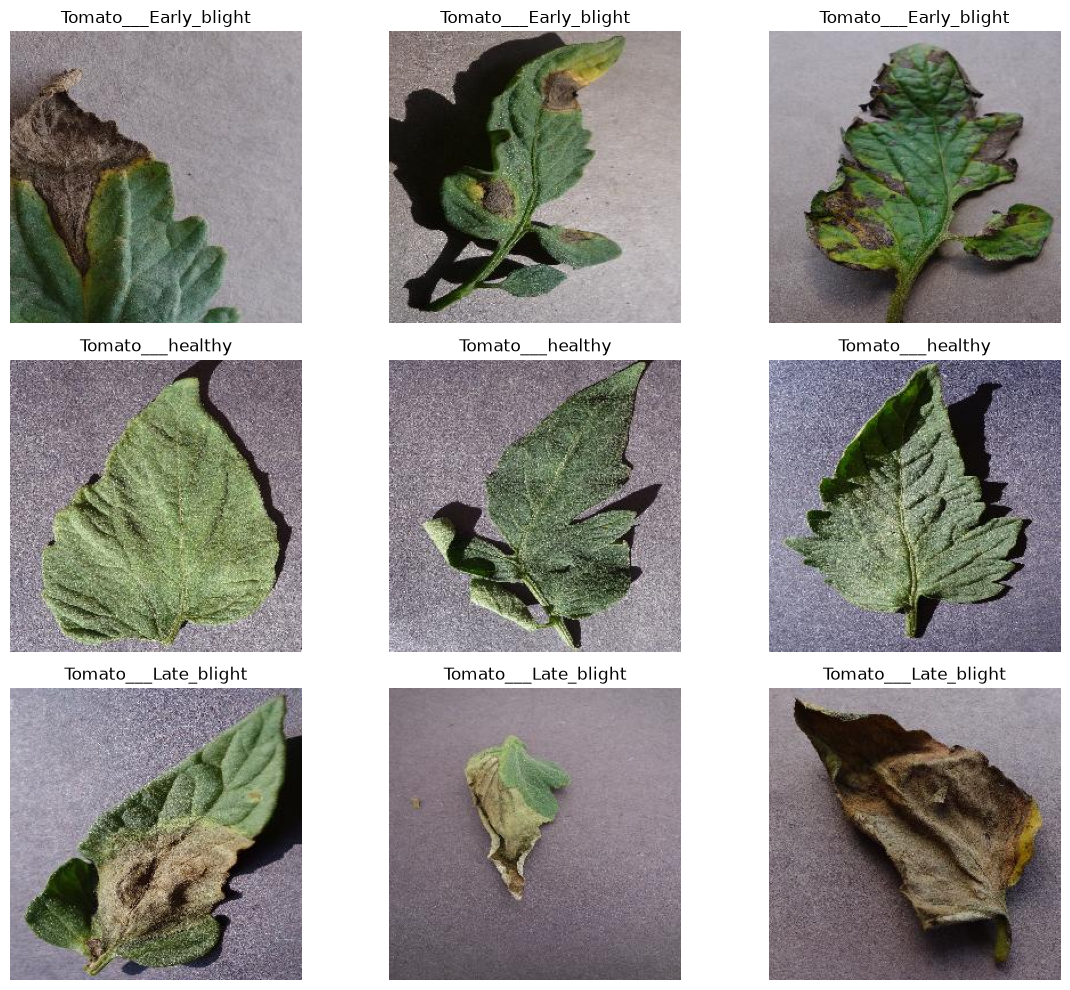

In [6]:
# Display 3 sample images from each class

plt.figure(figsize=(12, 10))

for row, class_name in enumerate(classes):

    class_path = os.path.join(dataset_path, class_name)

    images = [
        file for file in os.listdir(class_path)
        if file.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    selected_images = random.sample(images, 3)

    for col, image_name in enumerate(selected_images):

        image_path = os.path.join(class_path, image_name)

        image = Image.open(image_path)

        plt.subplot(3, 3, row * 3 + col + 1)
        plt.imshow(image)
        plt.title(class_name)
        plt.axis("off")

plt.tight_layout()
plt.show()

In [7]:
# Check dimensions of sample images

for class_name in classes:

    class_path = os.path.join(dataset_path, class_name)

    images = os.listdir(class_path)

    image_name = images[0]

    image_path = os.path.join(class_path, image_name)

    image = Image.open(image_path)

    print(class_name)
    print("Image dimensions:", image.size)
    print("Image format:", image.format)
    print("--------------------------")

Tomato___Early_blight
Image dimensions: (256, 256)
Image format: JPEG
--------------------------
Tomato___healthy
Image dimensions: (256, 256)
Image format: JPEG
--------------------------
Tomato___Late_blight
Image dimensions: (256, 256)
Image format: JPEG
--------------------------


In [8]:
# Check for corrupted images

corrupted_images = []

for class_name in classes:

    class_path = os.path.join(dataset_path, class_name)

    for image_name in os.listdir(class_path):

        image_path = os.path.join(class_path, image_name)

        try:
            with Image.open(image_path) as img:
                img.verify()

        except Exception:
            corrupted_images.append(image_path)

print("Total corrupted images:", len(corrupted_images))

Total corrupted images: 0


In [9]:
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [10]:
import shutil
from sklearn.model_selection import train_test_split

print("Libraries imported successfully!")

Libraries imported successfully!


In [11]:
# Create paths for our three datasets

split_path = r"C:\Users\haneef\Desktop\PlantPulse\dataset\split"

train_path = os.path.join(split_path, "train")
val_path = os.path.join(split_path, "validation")
test_path = os.path.join(split_path, "test")

# Create folders and divide images class by class

for class_name in classes:

    class_path = os.path.join(dataset_path, class_name)

    image_files = [
        file for file in os.listdir(class_path)
        if file.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    # First: 70% training, 30% temporary
    train_images, temp_images = train_test_split(
        image_files,
        test_size=0.30,
        random_state=42
    )

    # Second: Divide temporary images into 15% validation and 15% testing
    val_images, test_images = train_test_split(
        temp_images,
        test_size=0.50,
        random_state=42
    )

    # Create class folders
    for folder in [train_path, val_path, test_path]:
        os.makedirs(os.path.join(folder, class_name), exist_ok=True)

    # Copy training images
    for image in train_images:
        shutil.copy2(
            os.path.join(class_path, image),
            os.path.join(train_path, class_name, image)
        )

    # Copy validation images
    for image in val_images:
        shutil.copy2(
            os.path.join(class_path, image),
            os.path.join(val_path, class_name, image)
        )

    # Copy testing images
    for image in test_images:
        shutil.copy2(
            os.path.join(class_path, image),
            os.path.join(test_path, class_name, image)
        )

    print(f"\n{class_name}")
    print("Training:", len(train_images))
    print("Validation:", len(val_images))
    print("Testing:", len(test_images))

print("\nDataset splitting completed!")


Tomato___Early_blight
Training: 700
Validation: 150
Testing: 150

Tomato___healthy
Training: 1113
Validation: 239
Testing: 239

Tomato___Late_blight
Training: 1336
Validation: 286
Testing: 287

Dataset splitting completed!


In [12]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


In [13]:
# Define image settings

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

# Load training dataset
train_ds = tf.keras.utils.image_dataset_from_directory(
    train_path,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=True,
    seed=SEED
)

# Load validation dataset
val_ds = tf.keras.utils.image_dataset_from_directory(
    val_path,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

# Load testing dataset
test_ds = tf.keras.utils.image_dataset_from_directory(
    test_path,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

Found 3149 files belonging to 3 classes.
Found 675 files belonging to 3 classes.
Found 676 files belonging to 3 classes.


In [14]:
class_names = train_ds.class_names

print("Class names:", class_names)
print("Number of classes:", len(class_names))

Class names: ['Tomato___Early_blight', 'Tomato___Late_blight', 'Tomato___healthy']
Number of classes: 3


In [15]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.prefetch(buffer_size=AUTOTUNE)

print("Datasets are ready for training!")

Datasets are ready for training!


In [16]:
# Get one batch from the training dataset

images, labels = next(iter(train_ds))

print("Image batch shape:", images.shape)
print("Labels shape:", labels.shape)
print("First 10 labels:", labels[:10].numpy())

Image batch shape: (32, 224, 224, 3)
Labels shape: (32,)
First 10 labels: [2 1 1 2 0 2 2 1 0 2]


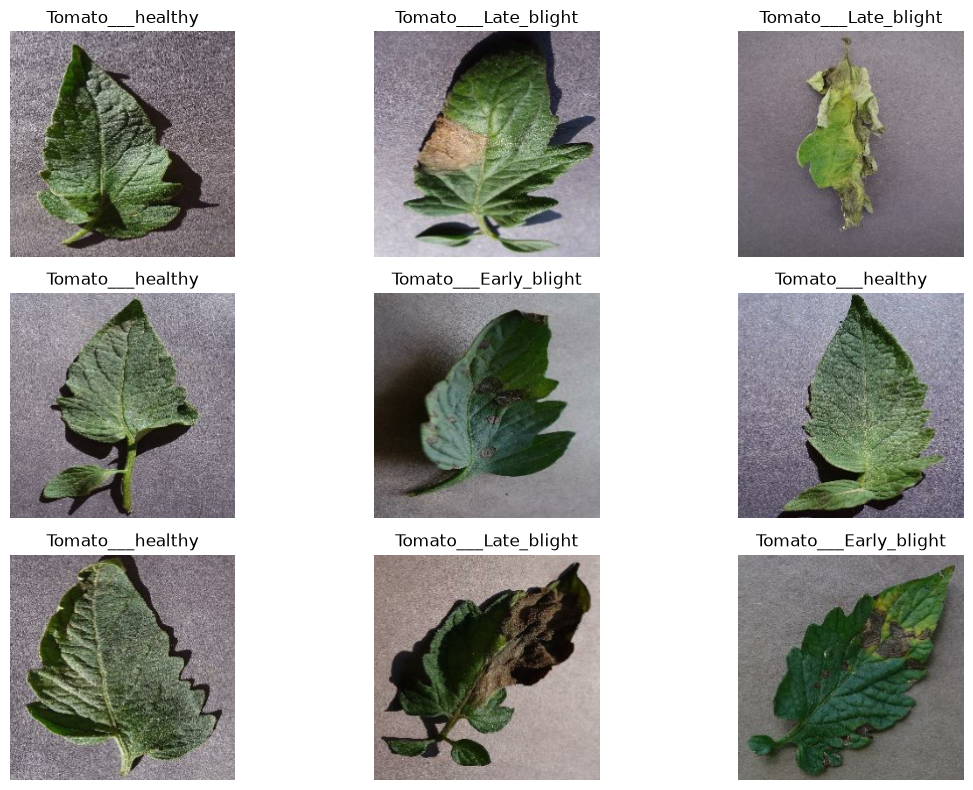

In [17]:
plt.figure(figsize=(12, 8))

for i in range(9):

    plt.subplot(3, 3, i + 1)

    plt.imshow(images[i].numpy().astype("uint8"))

    label = labels[i].numpy()

    plt.title(class_names[label])

    plt.axis("off")

plt.tight_layout()
plt.show()

In [18]:
# Load the pretrained EfficientNet-B0 model

base_model = tf.keras.applications.EfficientNetB0(
    include_top=False,
    weights="imagenet",
    input_shape=(224, 224, 3)
)

print("EfficientNet-B0 loaded successfully!")

EfficientNet-B0 loaded successfully!


In [19]:
# Freeze the pretrained layers

base_model.trainable = False

print("Pretrained layers frozen!")
print("Total layers:", len(base_model.layers))

Pretrained layers frozen!
Total layers: 238


In [20]:
# Build our PlantPulse classification model

inputs = tf.keras.Input(shape=(224, 224, 3))

# Extract image features
x = base_model(inputs, training=False)

# Reduce feature dimensions
x = tf.keras.layers.GlobalAveragePooling2D()(x)

# Reduce overfitting
x = tf.keras.layers.Dropout(0.3)(x)

# Three output classes
outputs = tf.keras.layers.Dense(3, activation="softmax")(x)

# Create final model
model = tf.keras.Model(inputs, outputs)

print("PlantPulse model created successfully!")

PlantPulse model created successfully!


In [21]:
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)           │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ efficientnetb0 (Functional)          │ (None, 7, 7, 1280)          │       4,049,571 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 1280)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 1280)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 3)                   │           3,843 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 4,053,414 (15.46 MB)

 Trainable params: 3,843 (15.01 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [22]:
# Compile the PlantPulse model

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("PlantPulse model compiled successfully!")

PlantPulse model compiled successfully!


In [23]:
# Stop training if validation loss stops improving

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

# Reduce learning rate when progress becomes slow

reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.2,
    patience=2,
    min_lr=0.00001
)

print("Training callbacks configured!")

Training callbacks configured!


In [24]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=[early_stopping, reduce_lr]
)

Epoch 1/10


C:\Users\haneef\anaconda3\envs\plantpulse\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


99/99 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.7815 - loss: 0.5420


KeyboardInterrupt


KeyboardInterrupt



In [ ]:
# Plot training and validation accuracy

plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("PlantPulse Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.legend()
plt.grid(True)
plt.show()

In [ ]:
# Plot training and validation loss

plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("PlantPulse Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.legend()
plt.grid(True)
plt.show()

In [ ]:
# Enable fine-tuning

base_model.trainable = True

# Freeze all layers except the last 30
for layer in base_model.layers[:-30]:
    layer.trainable = False

# Keep Batch Normalization layers frozen
for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

print("Fine-tuning layers configured!")

print("Total layers:", len(base_model.layers))
print("Trainable layers:", sum(
    layer.trainable for layer in base_model.layers
))

In [ ]:
# Compile with a smaller learning rate

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.00001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model recompiled for fine-tuning!")

In [ ]:
# Configure fine-tuning callbacks

fine_tune_early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

fine_tune_reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.2,
    patience=2,
    min_lr=0.0000001
)

print("Fine-tuning callbacks configured successfully!")

In [ ]:
history_finetune = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=[
        fine_tune_early_stopping,
        fine_tune_reduce_lr
    ]
)

In [ ]:
# Fine-tuning accuracy graph

plt.figure(figsize=(8, 5))

plt.plot(history_finetune.history["accuracy"], label="Training Accuracy")
plt.plot(history_finetune.history["val_accuracy"], label="Validation Accuracy")

plt.title("PlantPulse Fine-tuning Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.show()

In [ ]:
# Fine-tuning loss graph

plt.figure(figsize=(8, 5))

plt.plot(history_finetune.history["loss"], label="Training Loss")
plt.plot(history_finetune.history["val_loss"], label="Validation Loss")

plt.title("PlantPulse Fine-tuning Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.show()

In [ ]:
test_loss, test_accuracy = model.evaluate(test_ds)

print("PlantPulse Test Results")
print("-----------------------")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")
print(f"Test Loss: {test_loss:.4f}")

In [ ]:
import numpy as np

from sklearn.metrics import classification_report

# Get actual labels from test dataset
y_true = np.concatenate([
    labels.numpy() for images, labels in test_ds
])

# Get model predictions
y_probs = model.predict(test_ds)

# Convert probabilities into predicted class numbers
y_pred = np.argmax(y_probs, axis=1)

print("Classification Report:\n")

print(classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    digits=4
))

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Calculate confusion matrix
cm = confusion_matrix(y_true, y_pred)

# Display confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "Early Blight",
        "Late Blight",
        "Healthy"
    ]
)

disp.plot(xticks_rotation=45)

plt.title("PlantPulse - Confusion Matrix")
plt.tight_layout()
plt.show()

In [ ]:
import os

models_path = r"C:\Users\haneef\Desktop\PlantPulse\models"

# Create models folder if it doesn't exist
os.makedirs(models_path, exist_ok=True)

# Save trained model
model.save(
    os.path.join(models_path, "plantpulse_efficientnetb0.keras")
)

print("PlantPulse model saved successfully!")

In [ ]:
import json

class_names_path = os.path.join(models_path, "class_names.json")

with open(class_names_path, "w") as f:
    json.dump(class_names, f)

print("Class names saved successfully!")

In [ ]:
import tensorflow as tf
import json
import os

models_path = r"C:\Users\haneef\Desktop\PlantPulse\models"

# Load trained model
model = tf.keras.models.load_model(
    os.path.join(models_path, "plantpulse_efficientnetb0.keras")
)

# Load class names
with open(os.path.join(models_path, "class_names.json"), "r") as f:
    class_names = json.load(f)

print("PlantPulse loaded successfully!")
print("Classes:", class_names)

In [ ]:
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

def predict_disease(image_path):

    # Load image
    img = Image.open(image_path).convert("RGB")

    # Resize image to model input size
    img = img.resize((224, 224))

    # Convert image into NumPy array
    img_array = np.array(img)

    # Add batch dimension
    img_array = np.expand_dims(img_array, axis=0)

    # Make prediction
    predictions = model.predict(img_array, verbose=0)

    # Get predicted class
    predicted_index = np.argmax(predictions[0])

    # Get confidence
    confidence = predictions[0][predicted_index] * 100

    # Get disease name
    disease = class_names[predicted_index]

    # Display image and result
    plt.figure(figsize=(5, 5))
    plt.imshow(img)
    plt.axis("off")
    plt.title(f"{disease}\nConfidence: {confidence:.2f}%")
    plt.show()

    print("Predicted Disease:", disease)
    print(f"Confidence: {confidence:.2f}%")

    return disease, confidence

In [ ]:
test_image = r"C:\Users\haneef\Desktop\PlantPulse\dataset\Tomato\Tomato___Early_blight"

import os

image_name = os.listdir(test_image)[0]

image_path = os.path.join(test_image, image_name)

predict_disease(image_path)

In [ ]:
test_image = r"C:\Users\haneef\Desktop\PlantPulse\dataset\Tomato\Tomato___Early_blight"

import os

image_name = os.listdir(test_image)[5]

image_path = os.path.join(test_image, image_name)

predict_disease(image_path)

In [ ]:
test_image = r"C:\Users\haneef\Desktop\PlantPulse\dataset\Tomato\Tomato___Early_blight"

import os

image_name = os.listdir(test_image)[2]

image_path = os.path.join(test_image, image_name)

predict_disease(image_path)

In [ ]:
test_image = r"C:\Users\haneef\Desktop\PlantPulse\dataset\Tomato\Tomato___Late_blight"

import os

image_name = os.listdir(test_image)[0]

image_path = os.path.join(test_image, image_name)

predict_disease(image_path)

In [ ]:
test_image = r"C:\Users\haneef\Desktop\PlantPulse\dataset\Tomato\Tomato___Late_blight"

import os

image_name = os.listdir(test_image)[2]

image_path = os.path.join(test_image, image_name)

predict_disease(image_path)

In [ ]:
def predict_disease(image_path, threshold=80):

    img = Image.open(image_path).convert("RGB")
    img = img.resize((224, 224))

    img_array = np.array(img)
    img_array = np.expand_dims(img_array, axis=0)

    predictions = model.predict(img_array, verbose=0)

    predicted_index = np.argmax(predictions[0])
    confidence = predictions[0][predicted_index] * 100

    disease = class_names[predicted_index]

    plt.figure(figsize=(5, 5))
    plt.imshow(img)
    plt.axis("off")
    
    if confidence >= threshold:
        plt.title(f"{disease}\nConfidence: {confidence:.2f}%")
        print("Predicted Disease:", disease)
        print(f"Confidence: {confidence:.2f}%")
    else:
        plt.title("Uncertain Prediction")
        print("PlantPulse is not sufficiently confident.")
        print("Please upload a clearer leaf image.")
        print(f"Current confidence: {confidence:.2f}%")

    plt.show()

    return disease, confidence

In [ ]:
predict_disease(image_path)

In [ ]:
test_image = r"C:\Users\haneef\Desktop\PlantPulse\dataset\Tomato\Tomato___Late_blight"

import os

image_name = os.listdir(test_image)[29]

image_path = os.path.join(test_image, image_name)

predict_disease(image_path)

In [ ]:
import random
import os

random.seed(42)

test_samples = []

for class_name in class_names:

    folder_path = os.path.join(test_path, class_name)

    images = os.listdir(folder_path)

    selected_images = random.sample(images, 5)

    for image_name in selected_images:

        image_path = os.path.join(folder_path, image_name)

        test_samples.append((class_name, image_path))

print("Total selected images:", len(test_samples))

In [ ]:
correct = 0
total = len(test_samples)

for actual_class, image_path in test_samples:

    predicted_class, confidence = predict_disease(image_path)

    if actual_class == predicted_class:
        correct += 1

    print("Actual:", actual_class)
    print("Predicted:", predicted_class)
    print(f"Confidence: {confidence:.2f}%")
    print("-" * 50)

print("\n15-Image Testing Results")
print("Correct predictions:", correct)
print("Incorrect predictions:", total - correct)
print(f"Accuracy: {(correct / total) * 100:.2f}%")

In [ ]:
import os

knowledge_path = r"C:\Users\haneef\Desktop\PlantPulse\knowledge_base"

documents = {}

for filename in os.listdir(knowledge_path):

    if filename.endswith(".txt"):

        file_path = os.path.join(knowledge_path, filename)

        with open(file_path, "r", encoding="utf-8") as file:
            content = file.read()

        documents[filename] = content

        print(f"Loaded: {filename}")
        print(f"Characters: {len(content)}")
        print("-" * 40)

print("Total documents loaded:", len(documents))

In [ ]:
from textwrap import wrap

chunks = {}

chunk_size = 700
overlap = 100

for filename, content in documents.items():

    document_chunks = []

    start = 0

    while start < len(content):

        end = start + chunk_size

        chunk = content[start:end]

        document_chunks.append(chunk)

        start += chunk_size - overlap

    chunks[filename] = document_chunks

    print(f"\nDocument: {filename}")
    print("Number of chunks:", len(document_chunks))

print("\nTotal chunks:", sum(len(c) for c in chunks.values()))

In [ ]:
# Display the first chunk from each document

for filename, document_chunks in chunks.items():

    print("\nDocument:", filename)
    print("-" * 50)

    print(document_chunks[0])

    print("\nChunk length:", len(document_chunks[0]))

In [ ]:
%pip install langchain-text-splitters

In [ ]:
from langchain_text_splitters import RecursiveCharacterTextSplitter

text_splitter = RecursiveCharacterTextSplitter(
    chunk_size=700,
    chunk_overlap=100,
    separators=["\n\n", "\n", ". ", " ", ""]
)

improved_chunks = {}

for filename, content in documents.items():

    document_chunks = text_splitter.split_text(content)

    improved_chunks[filename] = document_chunks

    print(f"\nDocument: {filename}")
    print("Number of chunks:", len(document_chunks))

print("\nTotal chunks:", sum(len(c) for c in improved_chunks.values()))

In [ ]:
for filename, document_chunks in improved_chunks.items():

    print("\nDocument:", filename)
    print("-" * 50)

    print(document_chunks[0])
    print("\nChunk length:", len(document_chunks[0]))

In [ ]:
for filename, document_chunks in improved_chunks.items():

    print(f"\n{filename}")

    for i, chunk in enumerate(document_chunks):
        print(f"Chunk {i + 1}: {len(chunk)} characters")

In [ ]:
%pip install sentence-transformers

In [ ]:
from sentence_transformers import SentenceTransformer

embedding_model = SentenceTransformer("all-MiniLM-L6-v2")

print("Embedding model loaded successfully!")

In [ ]:
%pip install --upgrade ipywidgets jupyter

In [ ]:
import os

knowledge_path = r"C:\Users\haneef\Desktop\PlantPulse\knowledge_base"

documents = {}

for filename in os.listdir(knowledge_path):
    if filename.endswith(".txt"):
        file_path = os.path.join(knowledge_path, filename)

        with open(file_path, "r", encoding="utf-8") as file:
            documents[filename] = file.read()

print("Documents loaded:", len(documents))

In [ ]:
from langchain_text_splitters import RecursiveCharacterTextSplitter

text_splitter = RecursiveCharacterTextSplitter(
    chunk_size=700,
    chunk_overlap=100,
    separators=["\n\n", "\n", ". ", " ", ""]
)

improved_chunks = {}

for filename, content in documents.items():
    improved_chunks[filename] = text_splitter.split_text(content)

print("Improved chunks recreated!")
print("Total chunks:", sum(len(c) for c in improved_chunks.values()))

In [ ]:
all_chunks = []
chunk_metadata = []

for filename, document_chunks in improved_chunks.items():

    for i, chunk in enumerate(document_chunks):

        all_chunks.append(chunk)

        chunk_metadata.append({
            "source": filename,
            "chunk_id": i
        })

print("Total text chunks:", len(all_chunks))
print("Total metadata records:", len(chunk_metadata))

In [ ]:
embeddings = embedding_model.encode(all_chunks)

print("Embeddings generated successfully!")
print("Embedding shape:", embeddings.shape)

In [ ]:
print("Original text:")
print(all_chunks[0])

print("\nNumerical embedding:")
print(embeddings[0])

print("\nNumber of values:", len(embeddings[0]))

In [ ]:
%pip install chromadb

In [ ]:
import chromadb

client = chromadb.PersistentClient(
    path=r"C:\Users\haneef\Desktop\PlantPulse\chroma_db"
)

print("ChromaDB connected successfully!")

In [ ]:
collection = client.get_or_create_collection(
    name="plantpulse_knowledge",
    metadata={"hnsw:space": "cosine"}
)

print("PlantPulse knowledge collection created!")

In [ ]:
collection.upsert(
    ids=[f"chunk_{i}" for i in range(len(all_chunks))],
    documents=all_chunks,
    embeddings=embeddings.tolist(),
    metadatas=chunk_metadata
)

print("Knowledge successfully stored in ChromaDB!")
print("Total stored chunks:", collection.count())

In [ ]:
question = "What are the symptoms of early blight in tomato plants?"

query_embedding = embedding_model.encode([question]).tolist()

results = collection.query(
    query_embeddings=query_embedding,
    n_results=3,
    include=["documents", "metadatas", "distances"]
)

for i in range(3):
    print(f"\nResult {i + 1}")
    print("Source:", results["metadatas"][0][i]["source"])
    print("Distance:", results["distances"][0][i])
    print("Retrieved text:")
    print(results["documents"][0][i])
    print("-" * 50)

In [ ]:
question = "What is the capital of France?"

query_embedding = embedding_model.encode([question]).tolist()

results = collection.query(
    query_embeddings=query_embedding,
    n_results=3,
    include=["documents", "metadatas", "distances"]
)

for i in range(3):
    print(f"\nResult {i + 1}")
    print("Source:", results["metadatas"][0][i]["source"])
    print("Distance:", results["distances"][0][i])
    print(results["documents"][0][i])
    print("-" * 50)

In [ ]:
def retrieve_knowledge(question, threshold=0.5, top_k=3):

    query_embedding = embedding_model.encode([question]).tolist()

    results = collection.query(
        query_embeddings=query_embedding,
        n_results=top_k,
        include=["documents", "metadatas", "distances"]
    )

    best_distance = results["distances"][0][0]

    if best_distance > threshold:
        print("PlantPulse: Sorry, I don't have relevant information about this question.")
        return None

    print("Relevant information found!\n")

    for i in range(len(results["documents"][0])):
        print(f"Result {i+1}")
        print("Source:", results["metadatas"][0][i]["source"])
        print("Distance:", results["distances"][0][i])
        print(results["documents"][0][i])
        print("-" * 50)

    return results

In [ ]:
retrieve_knowledge("What are the symptoms of early blight?")

In [ ]:
retrieve_knowledge("What is the capital of France?")

In [ ]:
def detect_intent(question):

    question = question.lower()

    if any(word in question for word in ["symptom", "sign", "spot"]):
        return "symptoms"

    elif any(word in question for word in ["prevent", "prevention", "avoid"]):
        return "prevention"

    elif any(word in question for word in ["treat", "treatment", "manage", "control"]):
        return "management"

    else:
        return None


def retrieve_knowledge(question, threshold=0.5, top_k=10):

    query_embedding = embedding_model.encode([question]).tolist()

    results = collection.query(
        query_embeddings=query_embedding,
        n_results=top_k,
        include=["documents", "metadatas", "distances"]
    )

    best_distance = results["distances"][0][0]

    if best_distance > threshold:
        print("PlantPulse: Sorry, I don't have relevant information about this question.")
        return None

    intent = detect_intent(question)

    candidates = []

    for i, document in enumerate(results["documents"][0]):

        text = document.lower()
        distance = results["distances"][0][i]

        section_match = (
            intent is not None and intent.upper() in text
        )

        candidates.append({
            "document": document,
            "metadata": results["metadatas"][0][i],
            "distance": distance,
            "section_match": section_match
        })

    candidates.sort(
        key=lambda x: (not x["section_match"], x["distance"])
    )

    print("Question intent:", intent or "General")
    print("\nRelevant information:\n")

    for i, item in enumerate(candidates[:3]):

        print(f"Result {i+1}")
        print("Source:", item["metadata"]["source"])
        print("Distance:", item["distance"])
        print(item["document"])
        print("-" * 50)

    return candidates[:3]

In [ ]:
retrieve_knowledge("What are the symptoms of early blight?")

In [ ]:
question = "What are the symptoms of early blight?"

query_embedding = embedding_model.encode([question]).tolist()

test_results = collection.query(
    query_embeddings=query_embedding,
    n_results=3,
    include=["documents", "metadatas", "distances"]
)

test_text = test_results["documents"][0][2]

print(test_text)
print("\nHeading detected:",
      has_section_heading(test_text, "symptoms"))

In [ ]:
test_text = results["documents"][0][2]

print(has_section_heading(test_text, "symptoms"))

In [ ]:
print("Heading detected:", has_section_heading(test_text, "symptoms"))

In [ ]:
def retrieve_knowledge(question, threshold=0.5, top_k=10):

    query_embedding = embedding_model.encode([question]).tolist()

    results = collection.query(
        query_embeddings=query_embedding,
        n_results=top_k,
        include=["documents", "metadatas", "distances"]
    )

    best_distance = results["distances"][0][0]

    if best_distance > threshold:
        print("PlantPulse: Sorry, I don't have relevant information about this question.")
        return None

    intent = detect_intent(question)

    candidates = []

    for i, document in enumerate(results["documents"][0]):

        distance = results["distances"][0][i]

        section_match = has_section_heading(document, intent)

        candidates.append({
            "document": document,
            "metadata": results["metadatas"][0][i],
            "distance": distance,
            "section_match": section_match
        })

    candidates.sort(
        key=lambda x: (not x["section_match"], x["distance"])
    )

    print("Question intent:", intent or "General")
    print("\nRelevant information:\n")

    for i, item in enumerate(candidates[:3]):

        print(f"Result {i+1}")
        print("Source:", item["metadata"]["source"])
        print("Distance:", item["distance"])
        print(item["document"])
        print("-" * 50)

    return candidates[:3]

In [ ]:
retrieve_knowledge("What are the symptoms of early blight?")

In [ ]:
import re

def has_section_heading(text, intent):

    if intent is None:
        return False

    headings = {
        "symptoms": r"(?m)^\s*\d+\.\s*SYMPTOMS\s*$",
        "prevention": r"(?m)^\s*\d+\.\s*PREVENTION\s*$",
        "management": r"(?m)^\s*\d+\.\s*(MANAGEMENT|TREATMENT|CONTROL)\s*$"
    }

    return bool(re.search(headings[intent], text, re.IGNORECASE))

In [ ]:
for i, document in enumerate(test_results["documents"][0]):

    print(
        f"Result {i+1}:",
        has_section_heading(document, "symptoms")
    )

In [ ]:
for i, document in enumerate(test_results["documents"][0]):
    print(
        f"Result {i+1}:",
        has_section_heading(document, "symptoms")
    )

In [ ]:
def retrieve_knowledge(question, threshold=0.5, top_k=10):

    query_embedding = embedding_model.encode([question]).tolist()

    results = collection.query(
        query_embeddings=query_embedding,
        n_results=top_k,
        include=["documents", "metadatas", "distances"]
    )

    best_distance = results["distances"][0][0]

    if best_distance > threshold:
        print("PlantPulse: Sorry, I don't have relevant information about this question.")
        return None

    intent = detect_intent(question)
    candidates = []

    for i, document in enumerate(results["documents"][0]):

        distance = results["distances"][0][i]

        section_match = has_section_heading(document, intent)

        candidates.append({
            "document": document,
            "metadata": results["metadatas"][0][i],
            "distance": distance,
            "section_match": section_match
        })

    candidates.sort(
        key=lambda x: (not x["section_match"], x["distance"])
    )

    print("Question intent:", intent or "General")
    print("\nRelevant information:\n")

    for i, item in enumerate(candidates[:3]):

        print(f"Result {i+1}")
        print("Source:", item["metadata"]["source"])
        print("Distance:", item["distance"])
        print(item["document"])
        print("-" * 50)

    return candidates[:3]

In [ ]:
retrieve_knowledge("What are the symptoms of early blight?")

In [ ]:
retrieve_knowledge(
    "How can I treat and control early blight in tomato plants?"
)

In [ ]:
def has_section_heading(text, intent):

    if intent is None:
        return False

    headings = {
        "symptoms": r"(?m)^\s*\d+\.\s*SYMPTOMS\s*$",

        "prevention": r"(?m)^\s*\d+\.\s*PREVENTION\s*$",

        "management": r"(?m)^\s*\d+\.\s*(MANAGEMENT|TREATMENT|CONTROL|PREVENTION)\s*$"
    }

    return bool(re.search(headings[intent], text, re.IGNORECASE))

In [ ]:
test_text = test_results["documents"][0][0]

print("Management heading detected:",
      has_section_heading(test_text, "management"))

In [ ]:
retrieve_knowledge(
    "How can I treat and control early blight in tomato plants?"
)

In [ ]:
retrieve_knowledge(
    "How can farmers keep tomato plants healthy and prevent diseases?"
)

In [ ]:
import re

section_documents = {}

for filename, content in documents.items():

    sections = {}
    current_section = "GENERAL"
    current_text = []

    for line in content.splitlines():

        heading_match = re.match(
            r"^\s*\d+\.\s+([A-Z][A-Z &()/:-]*)\s*$",
            line
        )

        if heading_match:
            if current_text:
                sections[current_section] = "\n".join(current_text).strip()

            current_section = heading_match.group(1).strip()
            current_text = []

        else:
            current_text.append(line)

    if current_text:
        sections[current_section] = "\n".join(current_text).strip()

    section_documents[filename] = sections

print("SECTION SEPARATION COMPLETE\n")

for filename, sections in section_documents.items():

    print("FILE:", filename)

    for section, text_content in sections.items():
        print(f"  Section: {section}")
        print(f"  Characters: {len(text_content)}")

    print("-" * 50)

In [ ]:
def identify_disease(filename):

    if "early_blight" in filename:
        return "early_blight"

    elif "late_blight" in filename:
        return "late_blight"

    elif "healthy_tomato" in filename:
        return "healthy_tomato"

    return "unknown"


all_chunks = []
chunk_metadata = []

for filename, sections in section_documents.items():

    disease = identify_disease(filename)

    for section, content in sections.items():

        if not content.strip():
            continue

        chunks = text_splitter.split_text(content)

        for chunk_id, chunk in enumerate(chunks):

            all_chunks.append(chunk)

            chunk_metadata.append({
                "disease": disease,
                "section": section,
                "source": filename,
                "chunk_id": chunk_id
            })

print("Total chunks:", len(all_chunks))
print("Total metadata records:", len(chunk_metadata))

print("\nFirst 3 metadata records:\n")

for metadata in chunk_metadata[:3]:
    print(metadata)

In [ ]:
from collections import Counter

print("CHUNKS BY DISEASE:")
print(Counter(item["disease"] for item in chunk_metadata))

print("\nCHUNKS BY SECTION:")
print(Counter(item["section"] for item in chunk_metadata))

print("\nCHECKING MISSING METADATA:")

for item in chunk_metadata:
    if not all(item.values()):
        print("Incomplete:", item)

print("\nMetadata check completed!")

In [ ]:
required_fields = ["disease", "section", "source", "chunk_id"]

incomplete_records = []

for item in chunk_metadata:

    for field in required_fields:
        if field not in item or item[field] is None or item[field] == "":
            incomplete_records.append(item)
            break

print("Total metadata records:", len(chunk_metadata))
print("Incomplete records:", len(incomplete_records))

if len(incomplete_records) == 0:
    print("SUCCESS: All metadata records are complete!")
else:
    print("Records needing correction:")
    for item in incomplete_records:
        print(item)

In [ ]:
embeddings = embedding_model.encode(all_chunks)

print("Embeddings generated successfully!")
print("Embedding shape:", embeddings.shape)

In [ ]:
# Remove the old collection
client.delete_collection(name="plantpulse_knowledge")

# Create a fresh collection
collection = client.get_or_create_collection(
    name="plantpulse_knowledge",
    metadata={"hnsw:space": "cosine"}
)

# Store the new chunks, embeddings and metadata
collection.add(
    ids=[f"chunk_{i}" for i in range(len(all_chunks))],
    documents=all_chunks,
    embeddings=embeddings.tolist(),
    metadatas=chunk_metadata
)

print("New ChromaDB collection created!")
print("Total stored chunks:", collection.count())

In [ ]:
def detect_disease_topic(question):

    question = question.lower()

    if "early blight" in question:
        return "early_blight"

    elif "late blight" in question:
        return "late_blight"

    elif any(word in question for word in [
        "healthy", "watering", "water",
        "sunlight", "soil", "fertilizer",
        "fertilization", "plant care",
        "tomato care", "tomato plants"
    ]):
        return "healthy_tomato"

    elif any(word in question for word in [
        "prevent disease", "prevent diseases",
        "disease prevention", "keep tomato plants healthy"
    ]):
        return "healthy_tomato"

    return None


def detect_intent(question):

    question = question.lower()

    if any(word in question for word in [
        "symptom", "symptoms", "sign", "signs"
    ]):
        return "symptoms"

    elif any(word in question for word in [
        "treat", "treatment", "manage", "management",
        "control", "cure"
    ]):
        return "management and treatment"

    elif any(word in question for word in [
        "prevent", "prevention", "avoid"
    ]):
        return "prevention"

    elif any(word in question for word in [
        "water", "watering", "sunlight", "soil",
        "fertilizer", "fertilization", "spacing",
        "care", "nutrition"
    ]):
        return "general care"

    return "general"


print("Disease:", detect_disease_topic(
    "How can farmers keep tomato plants healthy and prevent diseases?"
))

print("Intent:", detect_intent(
    "How can farmers keep tomato plants healthy and prevent diseases?"
))

In [ ]:
question = "How can farmers keep tomato plants healthy and prevent diseases?"

disease = detect_disease_topic(question)

query_embedding = embedding_model.encode([question]).tolist()

results = collection.query(
    query_embeddings=query_embedding,
    n_results=5,
    where={"disease": disease},
    include=["documents", "metadatas", "distances"]
)

print("Detected disease:", disease)
print("\nRetrieved results:\n")

for i in range(len(results["documents"][0])):

    print("Result:", i + 1)
    print("Section:", results["metadatas"][0][i]["section"])
    print("Source:", results["metadatas"][0][i]["source"])
    print("Distance:", results["distances"][0][i])
    print(results["documents"][0][i])
    print("-" * 50)

In [ ]:
test_questions = [
    "What should I do to keep my tomato crop healthy?",
    "My tomato leaves have brown circular spots. What could be wrong?",
    "How much sunlight do tomato plants need?"
]

for question in test_questions:

    print("\nQuestion:", question)
    print("Detected disease:", detect_disease_topic(question))
    print("Detected intent:", detect_intent(question))
    print("-" * 50)

In [ ]:
def detect_intent(question):

    question = question.lower()

    symptom_words = [
        "symptom", "symptoms", "sign", "signs",
        "brown spots", "circular spots",
        "yellow leaves", "yellowing",
        "wilting", "discoloration",
        "leaf damage", "dark lesions"
    ]

    treatment_words = [
        "treat", "treatment", "manage",
        "management", "control", "cure"
    ]

    prevention_words = [
        "prevent", "prevention", "avoid"
    ]

    care_words = [
        "water", "watering", "sunlight",
        "soil", "fertilizer", "fertilization",
        "spacing", "care", "nutrition",
        "healthy", "growth"
    ]

    if any(word in question for word in symptom_words):
        return "symptoms"

    elif any(word in question for word in treatment_words):
        return "management and treatment"

    elif any(word in question for word in prevention_words):
        return "prevention"

    elif any(word in question for word in care_words):
        return "general care"

    return "general"

In [ ]:
for question in test_questions:

    print("Question:", question)
    print("Intent:", detect_intent(question))
    print("-" * 50)

In [37]:
def detect_disease_topic(question):

    question = question.lower()

    # Explicit disease names
    if "early blight" in question:
        return "early_blight"

    elif "late blight" in question:
        return "late_blight"

    # Possible Early Blight descriptions
    elif any(word in question for word in [
        "concentric rings",
        "circular brown spots",
        "brown circular spots",
        "older lower leaves"
    ]):
        return "early_blight"

    # Possible Late Blight descriptions
    elif any(word in question for word in [
        "water-soaked",
        "water soaked",
        "rapidly spreading dark lesions"
    ]):
        return "late_blight"

    # General tomato care
    elif any(word in question for word in [
        "healthy", "watering", "water",
        "sunlight", "soil", "fertilizer",
        "fertilization", "plant care",
        "tomato care", "tomato crop",
        "tomato plants"
    ]):
        return "healthy_tomato"

    return None

In [ ]:
new_questions = [
    "My tomato leaves have brown circular spots.",
    "My tomato leaves have water-soaked dark patches.",
    "How should I care for my tomato crop?"
]

for question in new_questions:

    print("Question:", question)
    print("Disease topic:", detect_disease_topic(question))
    print("Intent:", detect_intent(question))
    print("-" * 50)

In [ ]:
def detect_intent(question):

    question = question.lower()

    symptom_words = [
        "symptom", "symptoms", "sign", "signs",
        "brown spots", "circular spots",
        "yellow leaves", "yellowing",
        "wilting", "discoloration",
        "leaf damage", "dark lesions",
        "water-soaked", "water soaked",
        "dark patches", "lesions"
    ]

    treatment_words = [
        "treat", "treatment", "manage",
        "management", "control", "cure"
    ]

    prevention_words = [
        "prevent", "prevention", "avoid"
    ]

    care_words = [
        "water", "watering", "sunlight",
        "soil", "fertilizer", "fertilization",
        "spacing", "care", "nutrition",
        "healthy", "growth"
    ]

    if any(word in question for word in symptom_words):
        return "symptoms"

    elif any(word in question for word in treatment_words):
        return "management and treatment"

    elif any(word in question for word in prevention_words):
        return "prevention"

    elif any(word in question for word in care_words):
        return "general care"

    return "general"

In [ ]:
for question in new_questions:

    print("Question:", question)
    print("Disease topic:", detect_disease_topic(question))
    print("Intent:", detect_intent(question))
    print("-" * 50)

In [ ]:
print("Stored chunks:", collection.count())

print("\nAvailable disease categories:")

for disease in ["early_blight", "late_blight", "healthy_tomato"]:
    results = collection.get(
        where={"disease": disease},
        include=["metadatas"]
    )
    print(disease, ":", len(results["ids"]), "chunks")

In [ ]:
def retrieve_knowledge(question, threshold=0.65, top_k=5):

    disease = detect_disease_topic(question)
    intent = detect_intent(question)

    query_embedding = embedding_model.encode([question]).tolist()

    # Search the detected disease category, if available
    if disease:

        results = collection.query(
            query_embeddings=query_embedding,
            n_results=top_k,
            where={"disease": disease},
            include=["documents", "metadatas", "distances"]
        )

    else:

        results = collection.query(
            query_embeddings=query_embedding,
            n_results=top_k,
            include=["documents", "metadatas", "distances"]
        )

    candidates = []

    # Collect retrieved information
    for i, document in enumerate(results["documents"][0]):

        candidates.append({
            "document": document,
            "metadata": results["metadatas"][0][i],
            "distance": results["distances"][0][i]
        })

    # Prioritize sections according to question intent
    section_mapping = {
        "symptoms": ["SYMPTOMS"],
        "management and treatment": ["MANAGEMENT AND TREATMENT"],
        "prevention": ["PREVENTION", "DISEASE PREVENTION"],
        "general care": [
            "OVERVIEW",
            "SUNLIGHT REQUIREMENTS",
            "WATERING AND IRRIGATION",
            "SOIL REQUIREMENTS",
            "NUTRITION AND FERTILIZATION",
            "PLANT SPACING AND SUPPORT",
            "GENERAL PLANT MAINTENANCE"
        ]
    }

    preferred_sections = section_mapping.get(intent, [])

    # Rank preferred sections first, then by semantic distance
    candidates.sort(
        key=lambda item: (
            item["metadata"]["section"] not in preferred_sections,
            item["distance"]
        )
    )

    print("Detected disease:", disease or "Unknown")
    print("Detected intent:", intent)

    if not candidates or candidates[0]["distance"] > threshold:

        print("\nPlantPulse: I couldn't find sufficiently relevant information.")
        return None

    print("\nRetrieved information:\n")

    selected = candidates[:3]

    for i, item in enumerate(selected):

        print("Result:", i + 1)
        print("Section:", item["metadata"]["section"])
        print("Source:", item["metadata"]["source"])
        print("Distance:", round(item["distance"], 4))
        print(item["document"])
        print("-" * 50)

    return selected

In [ ]:
def retrieve_knowledge(question, threshold=0.70, top_k=10):

    disease = detect_disease_topic(question)
    intent = detect_intent(question)

    query_embedding = embedding_model.encode([question]).tolist()

    if disease:
        results = collection.query(
            query_embeddings=query_embedding,
            n_results=top_k,
            where={"disease": disease},
            include=["documents", "metadatas", "distances"]
        )
    else:
        results = collection.query(
            query_embeddings=query_embedding,
            n_results=top_k,
            include=["documents", "metadatas", "distances"]
        )

    candidates = []

    for i, document in enumerate(results["documents"][0]):
        candidates.append({
            "document": document,
            "metadata": results["metadatas"][0][i],
            "distance": results["distances"][0][i]
        })

    section_mapping = {
        "symptoms": ["SYMPTOMS"],
        "management and treatment": ["MANAGEMENT AND TREATMENT"],
        "prevention": ["PREVENTION", "DISEASE PREVENTION"],
        "general care": [
            "OVERVIEW",
            "SUNLIGHT REQUIREMENTS",
            "WATERING AND IRRIGATION",
            "SOIL REQUIREMENTS",
            "NUTRITION AND FERTILIZATION",
            "PLANT SPACING AND SUPPORT",
            "GENERAL PLANT MAINTENANCE"
        ]
    }

    preferred_sections = section_mapping.get(intent, [])

    # This must remain inside the function
    candidates.sort(
        key=lambda item: (
            item["metadata"]["section"] not in preferred_sections,
            item["distance"]
        )
    )

    print("Detected disease:", disease or "Unknown")
    print("Detected intent:", intent)

    if not candidates or candidates[0]["distance"] > threshold:
        print("PlantPulse: No sufficiently relevant information found.")
        return None

    selected = candidates[:3]

    for i, item in enumerate(selected):
        print("\nResult:", i + 1)
        print("Section:", item["metadata"]["section"])
        print("Source:", item["metadata"]["source"])
        print("Distance:", round(item["distance"], 4))
        print(item["document"])
        print("-" * 50)

    return selected

In [ ]:
retrieve_knowledge(
    "What are the symptoms of early blight in tomato plants?"
)

In [ ]:
retrieve_knowledge(
    "What are the symptoms of early blight in tomato plants?"
)

In [ ]:
question = "What are the symptoms of early blight in tomato plants?"

query_embedding = embedding_model.encode([question]).tolist()

results = collection.query(
    query_embeddings=query_embedding,
    n_results=8,
    where={"disease": "early_blight"},
    include=["documents", "metadatas", "distances"]
)

for i in range(len(results["documents"][0])):
    print("\nSection:", results["metadatas"][0][i]["section"])
    print("Distance:", round(results["distances"][0][i], 4))
    print(results["documents"][0][i][:200])
    print("-" * 40)

In [ ]:
retrieve_knowledge(
    "What are the symptoms of early blight in tomato plants?"
)

In [ ]:
answer = retrieve_knowledge(
    "What are the symptoms of early blight in tomato plants?"
)

In [ ]:
retrieve_knowledge(
    "How can I treat and control early blight in tomato plants?"
)

In [ ]:
retrieve_knowledge(
    "How can farmers keep tomato plants healthy and prevent diseases?"
)

In [ ]:
retrieve_knowledge(
    "My tomato leaves have water-soaked dark patches. What could be wrong?"
)

In [ ]:
retrieve_knowledge(
    "What is the capital of France?"
)

In [ ]:
retrieve_knowledge(
    "What causes early blight in tomato plants?"
)

In [ ]:
retrieve_knowledge(
    "How can early blight be prevented in tomato plants?"
)

In [ ]:
retrieve_knowledge(
    "How does late blight spread between tomato plants?"
)

In [ ]:
test_questions = [
    "How does late blight spread?",
    "What causes early blight?",
    "How can I treat late blight?",
    "How can I prevent tomato diseases?",
    "What are the symptoms of early blight?"
]

for question in test_questions:
    print(question)
    print("Detected intent:", detect_intent(question))
    print("-" * 50)

In [ ]:

def detect_intent(question):

    question = question.lower()

    # 1. Symptoms
    if any(word in question for word in [
        "symptom", "symptoms", "sign", "signs",
        "brown spots", "circular spots",
        "yellow leaves", "yellowing",
        "wilting", "discoloration",
        "dark lesions", "water-soaked",
        "dark patches", "lesions"
    ]):
        return "symptoms"

    # 2. Disease spread
    elif any(word in question for word in [
        "spread", "spreads", "spreading",
        "transmission", "transmit"
    ]):
        return "disease spread"

    # 3. Causes
    elif any(word in question for word in [
        "cause", "causes", "caused by",
        "reason", "reasons", "why",
        "fungus", "fungi", "pathogen",
        "responsible for"
    ]):
        return "causes"

    # 4. Treatment
    elif any(word in question for word in [
        "treat", "treatment", "manage",
        "management", "control", "cure"
    ]):
        return "management and treatment"

    # 5. Prevention
    elif any(word in question for word in [
        "prevent", "prevention", "avoid",
        "protect", "protection"
    ]):
        return "prevention"

    # 6. Watering
    elif any(word in question for word in [
        "water", "watering", "irrigation"
    ]):
        return "watering"

    # 7. Sunlight
    elif any(word in question for word in [
        "sunlight", "sunlight hours", "sun"
    ]):
        return "sunlight"

    # 8. Soil
    elif any(word in question for word in [
        "soil", "drainage"
    ]):
        return "soil"

    # 9. Fertilization
    elif any(word in question for word in [
        "fertilizer", "fertilization",
        "nutrition", "nutrients"
    ]):
        return "fertilization"

    # 10. Plant maintenance
    elif any(word in question for word in [
        "spacing", "support", "pruning"
    ]):
        return "plant maintenance"

    # 11. General tomato care
    elif any(word in question for word in [
        "care", "tomato plants", "tomato crop"
    ]):
        return "general care"

    # 12. Default
    else:
        return "general"


In [ ]:
print(detect_intent("How does late blight spread?"))
print(detect_intent("What causes early blight?"))
print(detect_intent("How can I treat late blight?"))
print(detect_intent("How can I prevent tomato diseases?"))
print(detect_intent("What are the symptoms of early blight?"))

In [ ]:
section_mapping = {
    "symptoms": ["SYMPTOMS"],

    "disease spread": ["DISEASE SPREAD"],

    "causes": ["OVERVIEW", "FAVORABLE CONDITIONS"],

    "management and treatment": [
        "MANAGEMENT AND TREATMENT"
    ],

    "prevention": [
        "PREVENTION",
        "DISEASE PREVENTION"
    ],

    "general care": [
        "OVERVIEW",
        "SUNLIGHT REQUIREMENTS",
        "WATERING AND IRRIGATION",
        "SOIL REQUIREMENTS",
        "NUTRITION AND FERTILIZATION",
        "PLANT SPACING AND SUPPORT",
        "GENERAL PLANT MAINTENANCE"
    ]
}

In [ ]:
retrieve_knowledge(
    "How does late blight spread between tomato plants?"
)

In [ ]:
question = "How does late blight spread between tomato plants?"

query_embedding = embedding_model.encode([question]).tolist()

results = collection.query(
    query_embeddings=query_embedding,
    n_results=10,
    where={"disease": "late_blight"},
    include=["documents", "metadatas", "distances"]
)

for i in range(len(results["documents"][0])):

    print("\nSection:", results["metadatas"][0][i]["section"])
    print("Distance:", round(results["distances"][0][i], 4))
    print(results["documents"][0][i][:250])
    print("-" * 50)

In [ ]:
def retrieve_knowledge(question, threshold=0.65, top_k=10):

    # Step 1: Detect disease and question intent
    disease = detect_disease_topic(question)
    intent = detect_intent(question)

    # Step 2: Convert question into embedding
    query_embedding = embedding_model.encode([question]).tolist()

    # Step 3: Retrieve relevant documents
    if disease:

        results = collection.query(
            query_embeddings=query_embedding,
            n_results=top_k,
            where={"disease": disease},
            include=["documents", "metadatas", "distances"]
        )

    else:

        results = collection.query(
            query_embeddings=query_embedding,
            n_results=top_k,
            include=["documents", "metadatas", "distances"]
        )

    # Step 4: Prepare retrieved candidates
    candidates = []

    for i, document in enumerate(results["documents"][0]):

        candidates.append({
            "document": document,
            "metadata": results["metadatas"][0][i],
            "distance": results["distances"][0][i]
        })

    # Step 5: Map question intent to preferred sections
    section_mapping = {

        "symptoms": ["SYMPTOMS"],

        "disease spread": ["DISEASE SPREAD"],

        "causes": ["OVERVIEW", "FAVORABLE CONDITIONS"],

        "management and treatment": ["MANAGEMENT AND TREATMENT"],

        "prevention": ["PREVENTION", "DISEASE PREVENTION"],

        "general care": [
            "OVERVIEW",
            "SUNLIGHT REQUIREMENTS",
            "WATERING AND IRRIGATION",
            "SOIL REQUIREMENTS",
            "NUTRITION AND FERTILIZATION",
            "PLANT SPACING AND SUPPORT",
            "GENERAL PLANT MAINTENANCE"
        ]
    }

    preferred_sections = section_mapping.get(intent, [])

    # Step 6: Check relevance before ranking
    print("Detected disease:", disease or "Unknown")
    print("Detected intent:", intent)
    print("Preferred sections:", preferred_sections)

    if not candidates:
        print("PlantPulse: No relevant information found.")
        return None

    best_distance = min(item["distance"] for item in candidates)

    if best_distance > threshold:
        print("PlantPulse: No sufficiently relevant information found.")
        return None

    # Step 7: Prioritize the preferred section
    candidates.sort(
        key=lambda item: (
            item["metadata"]["section"] not in preferred_sections,
            item["distance"]
        )
    )

    # Step 8: Select top 3 results
    selected = candidates[:3]

    # Step 9: Display results
    for i, item in enumerate(selected):

        print("\nResult:", i + 1)
        print("Section:", item["metadata"]["section"])
        print("Source:", item["metadata"]["source"])
        print("Distance:", round(item["distance"], 4))
        print(item["document"])
        print("-" * 50)

    return selected

In [ ]:
retrieve_knowledge(
    "How does late blight spread between tomato plants?"
)

In [ ]:
retrieve_knowledge(
    "What causes early blight in tomato plants?"
)

In [ ]:
retrieve_knowledge(
    "How often should I water my healthy tomato plants?"
)

In [ ]:
retrieve_knowledge(
    "How much sunlight do tomato plants need daily?"
)

In [40]:
def detect_intent(question):

    question = question.lower()

    # Symptoms
    if any(word in question for word in [
        "symptom", "symptoms", "sign", "signs",
        "brown spots", "circular spots",
        "yellow leaves", "yellowing",
        "wilting", "discoloration",
        "dark lesions", "water-soaked",
        "dark patches", "lesions"
    ]):
        return "symptoms"

    # Disease spread
    elif any(word in question for word in [
        "spread", "spreads", "spreading",
        "transmission", "transmit"
    ]):
        return "disease spread"

    # Causes
    elif any(word in question for word in [
        "cause", "causes", "caused by",
        "reason", "reasons", "why"
    ]):
        return "causes"

    # Treatment
    elif any(word in question for word in [
        "treat", "treatment", "manage",
        "management", "control", "cure"
    ]):
        return "management and treatment"

    # Prevention
    elif any(word in question for word in [
        "prevent", "prevention", "avoid",
        "protect", "protection"
    ]):
        return "prevention"

    # Specific tomato care topics
    elif any(word in question for word in [
        "water", "watering", "irrigation"
    ]):
        return "watering"

    elif any(word in question for word in [
        "sunlight", "sunlight hours", "sun"
    ]):
        return "sunlight"

    elif any(word in question for word in [
        "soil", "drainage"
    ]):
        return "soil"

    elif any(word in question for word in [
        "fertilizer", "fertilization", "nutrition", "nutrients"
    ]):
        return "fertilization"

    elif any(word in question for word in [
        "spacing", "support", "pruning"
    ]):
        return "plant maintenance"

    # General care
    elif any(word in question for word in [
        "care", "tomato plants", "tomato crop"
    ]):
        return "general care"

    else:
        return "general"

In [ ]:
def retrieve_knowledge(question, threshold=0.65, top_k=10):

    # Step 1: Detect disease and intent
    disease = detect_disease_topic(question)
    intent = detect_intent(question)

    # Step 2: Convert question into embedding
    query_embedding = embedding_model.encode([question]).tolist()

    # Step 3: Retrieve documents from ChromaDB
    if disease:

        results = collection.query(
            query_embeddings=query_embedding,
            n_results=top_k,
            where={"disease": disease},
            include=["documents", "metadatas", "distances"]
        )

    else:

        results = collection.query(
            query_embeddings=query_embedding,
            n_results=top_k,
            include=["documents", "metadatas", "distances"]
        )

    # Step 4: Prepare candidates
    candidates = []

    for i, document in enumerate(results["documents"][0]):

        candidates.append({
            "document": document,
            "metadata": results["metadatas"][0][i],
            "distance": results["distances"][0][i]
        })

    # Step 5: Map intents to knowledge-base sections
    section_mapping = {

        "symptoms": ["SYMPTOMS"],

        "disease spread": ["DISEASE SPREAD"],

        "causes": ["OVERVIEW", "FAVORABLE CONDITIONS"],

        "management and treatment": ["MANAGEMENT AND TREATMENT"],

        "prevention": ["PREVENTION", "DISEASE PREVENTION"],

        "watering": ["WATERING AND IRRIGATION"],

        "sunlight": ["SUNLIGHT REQUIREMENTS"],

        "soil": ["SOIL REQUIREMENTS"],

        "fertilization": ["NUTRITION AND FERTILIZATION"],

        "plant maintenance": [
            "PLANT SPACING AND SUPPORT",
            "GENERAL PLANT MAINTENANCE"
        ],

        "general care": [
            "OVERVIEW",
            "GENERAL PLANT MAINTENANCE"
        ]
    }

    preferred_sections = section_mapping.get(intent, [])

    # Step 6: Display detection information
    print("Detected disease:", disease or "Unknown")
    print("Detected intent:", intent)
    print("Preferred sections:", preferred_sections)

    # Step 7: Check whether relevant information exists
    if not candidates:
        print("PlantPulse: No relevant information found.")
        return None

    best_distance = min(
        item["distance"] for item in candidates
    )

    if best_distance > threshold:
        print("PlantPulse: No sufficiently relevant information found.")
        return None

    # Step 8: Prioritize preferred sections
    candidates.sort(
        key=lambda item: (
            item["metadata"]["section"] not in preferred_sections,
            item["distance"]
        )
    )

    # Step 9: Select top 3 results
    selected = candidates[:3]

    # Step 10: Display retrieved knowledge
    for i, item in enumerate(selected):

        print("\nResult:", i + 1)
        print("Section:", item["metadata"]["section"])
        print("Source:", item["metadata"]["source"])
        print("Distance:", round(item["distance"], 4))
        print(item["document"])
        print("-" * 50)

    return selected

In [ ]:
retrieve_knowledge(
    "How often should I water my healthy tomato plants?"
)

In [ ]:
retrieve_knowledge(
    "Which fertilizer and nutrients do tomato plants need?"
)

In [ ]:
retrieve_knowledge(
    "What type of soil is best for growing tomato plants?"
)

In [ ]:
retrieve_knowledge(
    "How should I support and space my tomato plants?"
)

In [ ]:
retrieve_knowledge(
    "What is the capital of France?"
)

In [ ]:
retrieve_knowledge(
    "Which fungus is responsible for causing early blight in tomato plants?"
)

In [39]:

def retrieve_knowledge(question, threshold=0.65, top_k=10):

    # Step 1: Detect disease and intent
    disease = detect_disease_topic(question)
    intent = detect_intent(question)

    # Step 2: Convert question into embedding
    query_embedding = embedding_model.encode([question]).tolist()

    # Step 3: Retrieve documents from ChromaDB
    if disease:
        results = collection.query(
            query_embeddings=query_embedding,
            n_results=top_k,
            where={"disease": disease},
            include=["documents", "metadatas", "distances"]
        )
    else:
        results = collection.query(
            query_embeddings=query_embedding,
            n_results=top_k,
            include=["documents", "metadatas", "distances"]
        )

    # Step 4: Prepare candidates
    candidates = []

    for i, document in enumerate(results["documents"][0]):
        candidates.append({
            "document": document,
            "metadata": results["metadatas"][0][i],
            "distance": results["distances"][0][i]
        })

    # Step 5: Map intents to knowledge-base sections
    section_mapping = {
        "symptoms": ["SYMPTOMS"],
        "disease spread": ["DISEASE SPREAD"],
        "causes": ["OVERVIEW", "FAVORABLE CONDITIONS"],
        "management and treatment": ["MANAGEMENT AND TREATMENT"],
        "prevention": ["PREVENTION", "DISEASE PREVENTION"],
        "watering": ["WATERING AND IRRIGATION"],
        "sunlight": ["SUNLIGHT REQUIREMENTS"],
        "soil": ["SOIL REQUIREMENTS"],
        "fertilization": ["NUTRITION AND FERTILIZATION"],
        "plant maintenance": [
            "PLANT SPACING AND SUPPORT",
            "GENERAL PLANT MAINTENANCE"
        ],
        "general care": [
            "OVERVIEW",
            "GENERAL PLANT MAINTENANCE"
        ]
    }

    preferred_sections = section_mapping.get(intent, [])

    # Step 6: Display detection information
    print("Detected disease:", disease or "Unknown")
    print("Detected intent:", intent)
    print("Preferred sections:", preferred_sections)

    # Step 7: Check whether information was retrieved
    if not candidates:
        print("PlantPulse: No relevant information found.")
        return None

    # Step 8: Check best similarity distance
    best_distance = min(
        item["distance"] for item in candidates
    )

    if best_distance > threshold:
        print("PlantPulse: No sufficiently relevant information found.")
        return None

    # Step 9: Filter out irrelevant chunks
    candidates = [
        item for item in candidates
        if item["distance"] <= threshold
    ]

    # Step 10: Prioritize preferred sections
    candidates.sort(
        key=lambda item: (
            item["metadata"]["section"] not in preferred_sections,
            item["distance"]
        )
    )

    # Step 11: Select top 3 results
    selected = candidates[:3]

    # Step 12: Display retrieved knowledge
    for i, item in enumerate(selected):

        print("\nResult:", i + 1)
        print("Section:", item["metadata"]["section"])
        print("Source:", item["metadata"]["source"])
        print("Distance:", round(item["distance"], 4))
        print(item["document"])
        print("-" * 50)

    return selected


In [30]:
retrieve_knowledge(
    "How should I support and space my tomato plants?"
)

NameError: name 'detect_disease_topic' is not defined

In [ ]:
retrieve_knowledge(
    "How can I prevent early blight from spreading in tomato plants?"
)

In [ ]:
retrieve_knowledge(
    "What are the common symptoms of late blight in tomato plants?"
)

In [ ]:
retrieve_knowledge(
    "What are the best practices for keeping tomato plants healthy?"
)

In [ ]:
import sys

print("Python version:", sys.version)
print("Python executable:", sys.executable)

In [ ]:
%pip install llama-cpp-python

In [35]:
import os
import tensorflow as tf
import chromadb
import json

# Load trained model
model = tf.keras.models.load_model(
    r"C:\Users\haneef\Desktop\PlantPulse\models\plantpulse_efficientnetb0.keras"
)

In [41]:
retrieve_knowledge(
    "What are the common symptoms of late blight in tomato plants?"
)

NameError: name 'embedding_model' is not defined

In [42]:
from sentence_transformers import SentenceTransformer

embedding_model = SentenceTransformer("all-MiniLM-L6-v2")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

In [46]:
retrieve_knowledge(
    "What are the common symptoms of late blight in tomato plants?"
)

Detected disease: late_blight
Detected intent: symptoms
Preferred sections: ['SYMPTOMS']

Result: 1
Section: SYMPTOMS
Source: late_blight.txt.txt
Distance: 0.5256
- Irregular, water-soaked green or dark patches appear on leaves.
- Infected areas gradually turn brown or black.
- White growth may appear on the underside of infected leaves under humid conditions.
- Stems may develop dark brown or black lesions.
- Fruits can develop firm, brown, irregular lesions.
- Severe infections can destroy large portions of the plant.
--------------------------------------------------

Result: 2
Section: GENERAL
Source: late_blight.txt.txt
Distance: 0.2263
DISEASE: Tomato Late Blight

CATEGORY: Tomato Plant Disease
--------------------------------------------------

Result: 3
Section: OVERVIEW
Source: late_blight.txt.txt
Distance: 0.237
Late Blight is a destructive tomato disease caused by Phytophthora infestans. It is an oomycete (water mold), not a true fungus.

The disease can spread rapidly under

[{'document': '- Irregular, water-soaked green or dark patches appear on leaves.\n- Infected areas gradually turn brown or black.\n- White growth may appear on the underside of infected leaves under humid conditions.\n- Stems may develop dark brown or black lesions.\n- Fruits can develop firm, brown, irregular lesions.\n- Severe infections can destroy large portions of the plant.',
  'metadata': {'chunk_id': 0,
   'disease': 'late_blight',
   'source': 'late_blight.txt.txt',
   'section': 'SYMPTOMS'},
  'distance': 0.525557279586792},
 {'document': 'DISEASE: Tomato Late Blight\n\nCATEGORY: Tomato Plant Disease',
  'metadata': {'section': 'GENERAL',
   'disease': 'late_blight',
   'chunk_id': 0,
   'source': 'late_blight.txt.txt'},
  'distance': 0.22633200883865356},
 {'document': 'Late Blight is a destructive tomato disease caused by Phytophthora infestans. It is an oomycete (water mold), not a true fungus.\n\nThe disease can spread rapidly under cool, humid and wet environmental condi

In [45]:
import chromadb

client = chromadb.PersistentClient(
    path=r"C:\Users\haneef\Desktop\PlantPulse\chroma_db"
)

collection = client.get_collection(
    name="plantpulse_knowledge"
)

print("Collection connected!")
print("Knowledge chunks:", collection.count())

Collection connected!
Knowledge chunks: 29


In [49]:
import os

setup_path = r"C:\Users\haneef\Desktop\PlantPulse\plantpulse_setup.py.txt"

with open(setup_path, "r") as file:
    setup_code = file.read()

exec(setup_code)

print("PlantPulse setup loaded!")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

PlantPulse initialized successfully!
Knowledge chunks: 29
Classes: ['Tomato___Early_blight', 'Tomato___Late_blight', 'Tomato___healthy']
PlantPulse setup loaded!


In [50]:
exec(open(
    r"C:\Users\haneef\Desktop\PlantPulse\plantpulse_setup.py.txt"
).read())

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]


PLANTPULSE INITIALIZED SUCCESSFULLY
EfficientNet-B0: Loaded
Embedding Model: Loaded
ChromaDB: Connected
Knowledge Chunks: 29
Classes: ['Tomato___Early_blight', 'Tomato___Late_blight', 'Tomato___healthy']

RAG Functions: Ready
1. detect_disease_topic()
2. detect_intent()
3. retrieve_knowledge()


In [51]:
retrieve_knowledge(
    "What are the common symptoms of late blight in tomato plants?"
)

Detected disease: late_blight
Detected intent: symptoms
Preferred sections: ['SYMPTOMS']

Result: 1
Section: SYMPTOMS
Source: late_blight.txt.txt
Distance: 0.5256
- Irregular, water-soaked green or dark patches appear on leaves.
- Infected areas gradually turn brown or black.
- White growth may appear on the underside of infected leaves under humid conditions.
- Stems may develop dark brown or black lesions.
- Fruits can develop firm, brown, irregular lesions.
- Severe infections can destroy large portions of the plant.
--------------------------------------------------

Result: 2
Section: GENERAL
Source: late_blight.txt.txt
Distance: 0.2263
DISEASE: Tomato Late Blight

CATEGORY: Tomato Plant Disease
--------------------------------------------------

Result: 3
Section: OVERVIEW
Source: late_blight.txt.txt
Distance: 0.237
Late Blight is a destructive tomato disease caused by Phytophthora infestans. It is an oomycete (water mold), not a true fungus.

The disease can spread rapidly under

[{'document': '- Irregular, water-soaked green or dark patches appear on leaves.\n- Infected areas gradually turn brown or black.\n- White growth may appear on the underside of infected leaves under humid conditions.\n- Stems may develop dark brown or black lesions.\n- Fruits can develop firm, brown, irregular lesions.\n- Severe infections can destroy large portions of the plant.',
  'metadata': {'source': 'late_blight.txt.txt',
   'section': 'SYMPTOMS',
   'disease': 'late_blight',
   'chunk_id': 0},
  'distance': 0.525557279586792},
 {'document': 'DISEASE: Tomato Late Blight\n\nCATEGORY: Tomato Plant Disease',
  'metadata': {'section': 'GENERAL',
   'chunk_id': 0,
   'source': 'late_blight.txt.txt',
   'disease': 'late_blight'},
  'distance': 0.22633200883865356},
 {'document': 'Late Blight is a destructive tomato disease caused by Phytophthora infestans. It is an oomycete (water mold), not a true fungus.\n\nThe disease can spread rapidly under cool, humid and wet environmental condi

In [52]:
retrieve_knowledge(
    "How can I treat early blight in tomato plants?"
)

Detected disease: early_blight
Detected intent: management and treatment
Preferred sections: ['MANAGEMENT AND TREATMENT']

Result: 1
Section: MANAGEMENT AND TREATMENT
Source: early_blight.txt.txt
Distance: 0.3093
- Remove infected leaves when symptoms appear.
- Maintain sufficient spacing between tomato plants.
- Use mulch to reduce soil splashing.
- Water around the base of plants.
- Avoid unnecessary wetting of leaves.
- Remove infected plant debris after harvest.
- Maintain healthy plant growth through appropriate watering and fertilization.
- If fungicide treatment is necessary, use a product approved for tomatoes in the local area and follow its label instructions.
--------------------------------------------------

Result: 2
Section: OVERVIEW
Source: early_blight.txt.txt
Distance: 0.2258
Early Blight is a common fungal disease affecting tomato plants. It is mainly associated with Alternaria solani and Alternaria tomatophila. The disease commonly begins on older, lower leaves and 

[{'document': '- Remove infected leaves when symptoms appear.\n- Maintain sufficient spacing between tomato plants.\n- Use mulch to reduce soil splashing.\n- Water around the base of plants.\n- Avoid unnecessary wetting of leaves.\n- Remove infected plant debris after harvest.\n- Maintain healthy plant growth through appropriate watering and fertilization.\n- If fungicide treatment is necessary, use a product approved for tomatoes in the local area and follow its label instructions.',
  'metadata': {'chunk_id': 0,
   'source': 'early_blight.txt.txt',
   'disease': 'early_blight',
   'section': 'MANAGEMENT AND TREATMENT'},
  'distance': 0.3093189597129822},
 {'document': 'Early Blight is a common fungal disease affecting tomato plants. It is mainly associated with Alternaria solani and Alternaria tomatophila. The disease commonly begins on older, lower leaves and can spread to stems and fruits.',
  'metadata': {'disease': 'early_blight',
   'source': 'early_blight.txt.txt',
   'chunk_id

In [53]:
retrieve_knowledge(
    "How often should I water my healthy tomato plants?"
)

Detected disease: healthy_tomato
Detected intent: watering
Preferred sections: ['WATERING AND IRRIGATION']

Result: 1
Section: WATERING AND IRRIGATION
Source: healthy_tomato.txt.txt
Distance: 0.5839
- Maintain consistent soil moisture.
- Water deeply enough to reach the root zone.
- Increase irrigation when weather is hot and dry, depending on soil conditions.
- Avoid excessive watering and waterlogging.
- Prefer drip irrigation or watering near the plant base.
- Avoid unnecessarily wetting leaves.
- Pay particular attention to irrigation during flowering and fruit development.
--------------------------------------------------

Result: 2
Section: SUNLIGHT REQUIREMENTS
Source: healthy_tomato.txt.txt
Distance: 0.409
- Tomato plants generally require at least 6–8 hours of direct sunlight daily.
- Select an open location with sufficient sunlight.
- Avoid overcrowding plants because it reduces light penetration and air circulation.
- Protect plants from extreme heat where necessary.
------

[{'document': '- Maintain consistent soil moisture.\n- Water deeply enough to reach the root zone.\n- Increase irrigation when weather is hot and dry, depending on soil conditions.\n- Avoid excessive watering and waterlogging.\n- Prefer drip irrigation or watering near the plant base.\n- Avoid unnecessarily wetting leaves.\n- Pay particular attention to irrigation during flowering and fruit development.',
  'metadata': {'disease': 'healthy_tomato',
   'source': 'healthy_tomato.txt.txt',
   'section': 'WATERING AND IRRIGATION',
   'chunk_id': 0},
  'distance': 0.5838865041732788},
 {'document': '- Tomato plants generally require at least 6–8 hours of direct sunlight daily.\n- Select an open location with sufficient sunlight.\n- Avoid overcrowding plants because it reduces light penetration and air circulation.\n- Protect plants from extreme heat where necessary.',
  'metadata': {'source': 'healthy_tomato.txt.txt',
   'section': 'SUNLIGHT REQUIREMENTS',
   'chunk_id': 0,
   'disease': 'h

In [4]:
retrieve_knowledge(
    "What is the capital of France?"
)

Detected disease: Unknown
Detected intent: general
Preferred sections: []
PlantPulse: No sufficiently relevant information found.


In [55]:
%pip show llama-cpp-python

Note: you may need to restart the kernel to use updated packages.


In [59]:
%pip install llama-cpp-python --extra-index-url https://abetlen.github.io/llama-cpp-python/whl/cpu

Looking in indexes: https://pypi.org/simple, https://abetlen.github.io/llama-cpp-python/whl/cpu
Note: you may need to restart the kernel to use updated packages.


In [3]:
exec(open(
    r"C:\Users\haneef\Desktop\PlantPulse\plantpulse_setup.py.txt"
).read())

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]


PLANTPULSE INITIALIZED SUCCESSFULLY
EfficientNet-B0: Loaded
Embedding Model: Loaded
ChromaDB: Connected
Knowledge Chunks: 29
Classes: ['Tomato___Early_blight', 'Tomato___Late_blight', 'Tomato___healthy']

RAG Functions: Ready
1. detect_disease_topic()
2. detect_intent()
3. retrieve_knowledge()


In [5]:
from llama_cpp import Llama

print("llama-cpp-python imported successfully!")

llama-cpp-python imported successfully!


In [6]:
from llama_cpp import Llama

LLM_PATH = r"C:\Users\haneef\Desktop\PlantPulse\models\Llama-3.2-1B-Instruct-Q5_K_M.gguf"

llm = Llama(
    model_path=LLM_PATH,
    n_ctx=2048,
    n_threads=4,
    n_gpu_layers=0,
    verbose=False
)

print("PlantPulse Llama model loaded successfully!")

PlantPulse Llama model loaded successfully!


In [8]:
response = llm(
    "Why my tomatos easily rotten what are the causes? Explain in simple words.",
    max_tokens=150,
    temperature=0.3
)

print(response["choices"][0]["text"])

 

Here's what I have:

1.  **Overripe Tomatoes**: When tomatoes are left out in the sun, they can become overripe and rotten. This is because the heat causes the starches in the fruit to convert into sugars, making them soft and mushy.
2.  **Lack of Water**: Tomatoes need water to grow and ripen. If they don't get enough water, they may become overripe and rotten.
3.  **Poor Soil Quality**: Tomatoes need well-draining soil with a pH between 6.0 and 6.8 to grow well. If the soil is too acidic or too alkaline, it can affect the growth and ripening of the tomatoes.
4. 


In [9]:
question = "What are the symptoms and treatment of tomato early blight?"

retrieved_docs = retrieve_knowledge(question)

Detected disease: early_blight
Detected intent: symptoms
Preferred sections: ['SYMPTOMS']

Result: 1
Section: SYMPTOMS
Source: early_blight.txt.txt
Distance: 0.6313
- Small brown or dark spots appear on older leaves.
- Spots gradually become larger.
- Circular concentric rings develop inside the spots, creating a target-like appearance.
- Yellow areas may surround the infected spots.
- Severely infected leaves turn brown and fall off.
- Dark, sunken lesions may develop on stems and fruits.
--------------------------------------------------

Result: 2
Section: GENERAL
Source: early_blight.txt.txt
Distance: 0.2334
DISEASE: Tomato Early Blight

CATEGORY: Tomato Plant Disease
--------------------------------------------------

Result: 3
Section: IMPORTANT NOTE
Source: early_blight.txt.txt
Distance: 0.2427
Early Blight symptoms can resemble other tomato leaf diseases. A visual prediction alone should not be treated as a confirmed laboratory diagnosis. If symptoms are unclear, seek advice fr

In [10]:
context = "\n\n".join(
    [item["document"] for item in retrieved_docs]
)

print(context)

- Small brown or dark spots appear on older leaves.
- Spots gradually become larger.
- Circular concentric rings develop inside the spots, creating a target-like appearance.
- Yellow areas may surround the infected spots.
- Severely infected leaves turn brown and fall off.
- Dark, sunken lesions may develop on stems and fruits.

DISEASE: Tomato Early Blight

CATEGORY: Tomato Plant Disease

Early Blight symptoms can resemble other tomato leaf diseases. A visual prediction alone should not be treated as a confirmed laboratory diagnosis. If symptoms are unclear, seek advice from an agricultural specialist.

SOURCES

1. University of Maryland Extension:
https://extension.umd.edu/resource/early-blight-tomatoes

2. University of Minnesota Extension:
https://extension.umn.edu/agriculture/specialty-crops/vegetable-farming/disease-management/early-blight-in-tomato-and-potato

3. Colorado State University Extension:
https://extension.colostate.edu/resource/tomato-early-blight/


In [11]:
prompt = f"""
You are PlantPulse, an agricultural assistant.

Answer the user's question using ONLY the agricultural
information provided below.

If the information is insufficient, clearly say no.
Do not invent treatments or recommendations.

Agricultural Knowledge:
{context}

User Question:
{question}

Answer in simple, clear language:
"""

print(prompt)


You are PlantPulse, an agricultural assistant.

Answer the user's question using ONLY the agricultural
information provided below.

If the information is insufficient, clearly say so.
Do not invent treatments or recommendations.

Agricultural Knowledge:
- Small brown or dark spots appear on older leaves.
- Spots gradually become larger.
- Circular concentric rings develop inside the spots, creating a target-like appearance.
- Yellow areas may surround the infected spots.
- Severely infected leaves turn brown and fall off.
- Dark, sunken lesions may develop on stems and fruits.

DISEASE: Tomato Early Blight

CATEGORY: Tomato Plant Disease

Early Blight symptoms can resemble other tomato leaf diseases. A visual prediction alone should not be treated as a confirmed laboratory diagnosis. If symptoms are unclear, seek advice from an agricultural specialist.

SOURCES

1. University of Maryland Extension:
https://extension.umd.edu/resource/early-blight-tomatoes

2. University of Minnesota Ex

In [12]:
response = llm(
    prompt,
    max_tokens=250,
    temperature=0.2,
    stop=["</s>"]
)

answer = response["choices"][0]["text"]

print("PLANTPULSE ANSWER:\n")
print(answer)

PLANTPULSE ANSWER:

Symptoms:
- Small brown or dark spots appear on older leaves.
- Spots gradually become larger.
- Circular concentric rings develop inside the spots, creating a target-like appearance.
- Yellow areas may surround the infected spots.
- Severely infected leaves turn brown and fall off.

Treatment:
- Remove infected leaves and stems.
- Use a fungicide specifically labeled for tomato early blight.
- Apply fungicides according to label instructions.
- Maintain good sanitation and hygiene practices.
- Consider using a resistant variety of tomato.


In [14]:
prompt = f"""
You are PlantPulse, a reliable agricultural assistant.

STRICT RULES:
1. Use ONLY the information in the provided agricultural context.
2. Never add information from your pretrained knowledge.
3. Never invent treatments, pesticides, chemicals, or dosages.
4. If the context does not contain treatment information,
   explicitly say: "Treatment information is not available
   in my current knowledge base."
5. Separate confirmed information from missing information.

Agricultural Context:
{context}

User Question:
{question}

Provide a simple and clear answer:
"""

In [15]:
print("Prompt length:", len(prompt))
print("Llama loaded:", llm is not None)

Prompt length: 1585
Llama loaded: True


In [16]:
import time

start = time.time()

response = llm(
    "Explain tomato early blight in two sentences.",
    max_tokens=60,
    temperature=0.2
)

end = time.time()

print(response["choices"][0]["text"])
print("\nGeneration time:", round(end - start, 2), "seconds")
print("Tokens generated:", response["usage"]["completion_tokens"])

 Tomato early blight is a fungal disease caused by the pathogen Alternaria tenuissima, which infects tomato plants by penetrating the plant's vascular tissue. The disease causes yellowing or browning of leaves and stems, and can lead to reduced fruit production and plant death if left untreated.



Generation time: 3.0 seconds
Tokens generated: 60


In [17]:
response = llm(
    prompt,
    max_tokens=200,
    temperature=0.1
)

answer = response["choices"][0]["text"]

print("PLANTPULSE ANSWER:\n")
print(answer)

PLANTPULSE ANSWER:

Treatment information is not available in my current knowledge base.


In [18]:
import os

KNOWLEDGE_PATH = os.path.join(
    PROJECT_PATH, "knowledge_base"
)

for filename in os.listdir(KNOWLEDGE_PATH):
    if filename.endswith(".txt"):
        print(filename)

early_blight.txt.txt
healthy_tomato.txt.txt
late_blight.txt.txt


In [19]:
early_file = os.path.join(
    KNOWLEDGE_PATH,
    "early_blight.txt.txt"
)

with open(early_file, "r", encoding="utf-8") as file:
    early_text = file.read()

print("Early Blight document loaded!")
print("Total characters:", len(early_text))
print("\nLast 1500 characters:\n")
print(early_text[-1500:])

Early Blight document loaded!
Total characters: 3609

Last 1500 characters:

xtension.umn.edu/agriculture/specialty-crops/vegetable-farming/disease-management/early-blight-in-tomato-and-potato

3. Colorado State University Extension:
https://extension.colostate.edu/resource/tomato-early-blight/

10. MANAGEMENT AND TREATMENT

CULTURAL MANAGEMENT

- Remove infected leaves when symptoms appear to help reduce disease spread.
- Avoid removing more than one-third of the plant's leaves at once.
- Water near the plant base instead of wetting the leaves.
- Use mulch to reduce soil and water splashing onto lower leaves.
- Maintain sufficient spacing between plants to improve air circulation.
- Stake or support tomato plants to keep leaves away from soil.
- Clean pruning tools after working with infected plants.
- Remove infected plant debris after harvesting.
- Practice crop rotation to reduce disease buildup in the soil.

FUNGICIDE MANAGEMENT

- Fungicides may help manage early blight when cult

In [20]:
section_documents = {}

for filename in os.listdir(KNOWLEDGE_PATH):

    if not filename.endswith(".txt"):
        continue

    file_path = os.path.join(KNOWLEDGE_PATH, filename)

    with open(file_path, "r", encoding="utf-8") as file:
        text = file.read()

    sections = {}

    parts = text.split("\n")

    current_section = "GENERAL"
    sections[current_section] = ""

    for line in parts:
        line = line.strip()

        if line and line[0].isdigit() and ". " in line:
            current_section = line.split(". ", 1)[1].strip().upper()
            sections[current_section] = ""
        else:
            sections[current_section] += line + "\n"

    section_documents[filename] = sections

print("Documents reloaded successfully!\n")

for filename, sections in section_documents.items():
    print(filename)

    for section, content in sections.items():
        if content.strip():
            print("  ", section, ":", len(content), "characters")

Documents reloaded successfully!

early_blight.txt.txt
   GENERAL : 62 characters
   OVERVIEW : 229 characters
   SYMPTOMS : 332 characters
   FAVORABLE CONDITIONS : 130 characters
   DISEASE SPREAD : 162 characters
   MANAGEMENT AND TREATMENT : 1252 characters
   PREVENTION : 229 characters
   IMPORTANT NOTE : 229 characters
   UNIVERSITY OF MARYLAND EXTENSION: : 58 characters
   UNIVERSITY OF MINNESOTA EXTENSION: : 126 characters
   COLORADO STATE UNIVERSITY EXTENSION: : 63 characters
healthy_tomato.txt.txt
   GENERAL : 103 characters
   OVERVIEW : 271 characters
   SUNLIGHT REQUIREMENTS : 271 characters
   WATERING AND IRRIGATION : 388 characters
   SOIL REQUIREMENTS : 312 characters
   NUTRITION AND FERTILIZATION : 528 characters
   PLANT SPACING AND SUPPORT : 350 characters
   GENERAL PLANT MAINTENANCE : 299 characters
   DISEASE PREVENTION : 366 characters
   IMPORTANT NOTE : 298 characters
late_blight.txt.txt
   GENERAL : 61 characters
   OVERVIEW : 262 characters
   SYMPTOMS : 

In [21]:
import re

section_documents = {}

for filename in os.listdir(KNOWLEDGE_PATH):

    if not filename.endswith(".txt"):
        continue

    file_path = os.path.join(KNOWLEDGE_PATH, filename)

    with open(file_path, "r", encoding="utf-8") as file:
        text = file.read()

    sections = {}
    current_section = "GENERAL"
    sections[current_section] = ""

    for line in text.split("\n"):
        line = line.strip()

        # Detect numbered headings written in uppercase
        if re.match(r"^\d+\.\s+[A-Z][A-Z\s&():\-]+$", line):

            current_section = re.sub(
                r"^\d+\.\s+", "", line
            ).strip()

            sections[current_section] = ""

        else:
            sections[current_section] += line + "\n"

    section_documents[filename] = sections

print("Updated section parsing complete!\n")

for filename, sections in section_documents.items():
    print(filename)

    for section, content in sections.items():
        if content.strip():
            print("  ", section)

Updated section parsing complete!

early_blight.txt.txt
   GENERAL
   OVERVIEW
   SYMPTOMS
   FAVORABLE CONDITIONS
   DISEASE SPREAD
   MANAGEMENT AND TREATMENT
   PREVENTION
   IMPORTANT NOTE
healthy_tomato.txt.txt
   GENERAL
   OVERVIEW
   SUNLIGHT REQUIREMENTS
   WATERING AND IRRIGATION
   SOIL REQUIREMENTS
   NUTRITION AND FERTILIZATION
   PLANT SPACING AND SUPPORT
   GENERAL PLANT MAINTENANCE
   DISEASE PREVENTION
   IMPORTANT NOTE
late_blight.txt.txt
   GENERAL
   OVERVIEW
   SYMPTOMS
   FAVORABLE CONDITIONS
   DISEASE SPREAD
   MANAGEMENT AND TREATMENT
   PREVENTION
   IMPORTANT DIFFERENCE: EARLY BLIGHT VS LATE BLIGHT
   IMPORTANT NOTE
   CABI:


In [24]:
all_chunks = []
chunk_metadata = []

for filename, sections in section_documents.items():

    disease = identify_disease(filename)

    for section, content in sections.items():

        if not content.strip():
            continue

        chunks = text_splitter.split_text(content)

        for chunk_id, chunk in enumerate(chunks):

            all_chunks.append(chunk)

            chunk_metadata.append({
                "disease": disease,
                "section": section,
                "source": filename,
                "chunk_id": chunk_id
            })

print("Total chunks:", len(all_chunks))

print("\nChunks by disease:")

for disease in ["early_blight", "late_blight", "healthy_tomato"]:
    count = sum(
        1 for item in chunk_metadata
        if item["disease"] == disease
    )
    print(disease, ":", count)

print("\nNew management section chunks:")

for chunk, metadata in zip(all_chunks, chunk_metadata):
    if (
        metadata["disease"] == "early_blight"
        and metadata["section"] == "MANAGEMENT AND TREATMENT"
    ):
        print("\n", chunk)

NameError: name 'text_splitter' is not defined

In [23]:
def identify_disease(filename):

    if "early_blight" in filename:
        return "early_blight"

    elif "late_blight" in filename:
        return "late_blight"

    elif "healthy_tomato" in filename:
        return "healthy_tomato"

    return "unknown"


print("Disease identification function restored!")

Disease identification function restored!


In [27]:
all_chunks = []
chunk_metadata = []

for filename, sections in section_documents.items():

    disease = identify_disease(filename)

    for section, content in sections.items():

        if not content.strip():
            continue

        chunks = text_splitter.split_text(content)

        for chunk_id, chunk in enumerate(chunks):

            all_chunks.append(chunk)

            chunk_metadata.append({
                "disease": disease,
                "section": section,
                "source": filename,
                "chunk_id": chunk_id
            })

print("Total chunks:", len(all_chunks))

print("\nChunks by disease:")

for disease in ["early_blight", "late_blight", "healthy_tomato"]:
    count = sum(
        1 for item in chunk_metadata
        if item["disease"] == disease
    )
    print(disease, ":", count)

print("\nNew management section chunks:")

for chunk, metadata in zip(all_chunks, chunk_metadata):
    if (
        metadata["disease"] == "early_blight"
        and metadata["section"] == "MANAGEMENT AND TREATMENT"
    ):
        print("\n", chunk)

Total chunks: 30

Chunks by disease:
early_blight : 9
late_blight : 10
healthy_tomato : 11

New management section chunks:

 CULTURAL MANAGEMENT

- Remove infected leaves when symptoms appear to help reduce disease spread.
- Avoid removing more than one-third of the plant's leaves at once.
- Water near the plant base instead of wetting the leaves.
- Use mulch to reduce soil and water splashing onto lower leaves.
- Maintain sufficient spacing between plants to improve air circulation.
- Stake or support tomato plants to keep leaves away from soil.
- Clean pruning tools after working with infected plants.
- Remove infected plant debris after harvesting.
- Practice crop rotation to reduce disease buildup in the soil.

FUNGICIDE MANAGEMENT

 FUNGICIDE MANAGEMENT

- Fungicides may help manage early blight when cultural practices alone are insufficient.
- Fungicides are generally more effective as preventive protection than as a cure for severely infected leaves.
- Only use products legally 

In [26]:
from langchain_text_splitters import RecursiveCharacterTextSplitter

text_splitter = RecursiveCharacterTextSplitter(
    chunk_size=700,
    chunk_overlap=100,
    separators=["\n\n", "\n", ". ", " ", ""]
)

print("Text splitter restored successfully!")

Text splitter restored successfully!


In [28]:
embeddings = embedding_model.encode(
    all_chunks,
    show_progress_bar=True
)

print("Embeddings generated successfully!")
print("Embedding shape:", embeddings.shape)

Batches:   0%|          | 0/1 [00:00<?, ?it/s]

Embeddings generated successfully!
Embedding shape: (30, 384)


In [29]:
# Delete the old collection
client.delete_collection(name="plantpulse_knowledge")

# Create a fresh collection
collection = client.get_or_create_collection(
    name="plantpulse_knowledge",
    metadata={"hnsw:space": "cosine"}
)

# Insert updated chunks and embeddings
collection.add(
    ids=[f"chunk_{i}" for i in range(len(all_chunks))],
    documents=all_chunks,
    embeddings=embeddings.tolist(),
    metadatas=chunk_metadata
)

print("ChromaDB updated successfully!")
print("Total knowledge chunks:", collection.count())

ChromaDB updated successfully!
Total knowledge chunks: 30


In [30]:
retrieve_knowledge(
    "How can I manage and treat tomato early blight?"
)

Detected disease: early_blight
Detected intent: management and treatment
Preferred sections: ['MANAGEMENT AND TREATMENT']

Result: 1
Section: MANAGEMENT AND TREATMENT
Source: early_blight.txt.txt
Distance: 0.2666
FUNGICIDE MANAGEMENT

- Fungicides may help manage early blight when cultural practices alone are insufficient.
- Fungicides are generally more effective as preventive protection than as a cure for severely infected leaves.
- Only use products legally registered for tomatoes and the intended disease in your location.
- Always follow the product label, safety precautions, application instructions, and pre-harvest interval.
- Seek advice from a local agricultural extension specialist before selecting a pesticide.

IMPORTANT NOTE

Management practices can reduce disease development, but they do not guarantee complete elimination of early blight.
--------------------------------------------------

Result: 2
Section: MANAGEMENT AND TREATMENT
Source: early_blight.txt.txt
Distance: 0

[{'document': 'FUNGICIDE MANAGEMENT\n\n- Fungicides may help manage early blight when cultural practices alone are insufficient.\n- Fungicides are generally more effective as preventive protection than as a cure for severely infected leaves.\n- Only use products legally registered for tomatoes and the intended disease in your location.\n- Always follow the product label, safety precautions, application instructions, and pre-harvest interval.\n- Seek advice from a local agricultural extension specialist before selecting a pesticide.\n\nIMPORTANT NOTE\n\nManagement practices can reduce disease development, but they do not guarantee complete elimination of early blight.',
  'metadata': {'section': 'MANAGEMENT AND TREATMENT',
   'source': 'early_blight.txt.txt',
   'disease': 'early_blight',
   'chunk_id': 1},
  'distance': 0.2666313648223877},
 {'document': "CULTURAL MANAGEMENT\n\n- Remove infected leaves when symptoms appear to help reduce disease spread.\n- Avoid removing more than one-

In [32]:
question = "How can I manage and treat tomato early blight?"

retrieved_docs = retrieve_knowledge(question)

context = "\n\n".join(
    [item["document"] for item in retrieved_docs]
)

prompt = f"""
You are PlantPulse, a reliable agricultural assistant.

STRICT RULES:
1. Use ONLY the provided agricultural context.
2. Never invent treatments, pesticides, or dosages.
3. If information is missing, clearly acknowledge it.
4. Explain recommendations in simple language.

Agricultural Context:
{context}

User Question:
{question}

Provide a clear and practical answer:
"""

response = llm(
    prompt,
    max_tokens=250,
    temperature=0.1
)

answer = response["choices"][0]["text"]

print("\nPLANTPULSE ANSWER:\n")
print(answer)

Detected disease: early_blight
Detected intent: management and treatment
Preferred sections: ['MANAGEMENT AND TREATMENT']

Result: 1
Section: MANAGEMENT AND TREATMENT
Source: early_blight.txt.txt
Distance: 0.2666
FUNGICIDE MANAGEMENT

- Fungicides may help manage early blight when cultural practices alone are insufficient.
- Fungicides are generally more effective as preventive protection than as a cure for severely infected leaves.
- Only use products legally registered for tomatoes and the intended disease in your location.
- Always follow the product label, safety precautions, application instructions, and pre-harvest interval.
- Seek advice from a local agricultural extension specialist before selecting a pesticide.

IMPORTANT NOTE

Management practices can reduce disease development, but they do not guarantee complete elimination of early blight.
--------------------------------------------------

Result: 2
Section: MANAGEMENT AND TREATMENT
Source: early_blight.txt.txt
Distance: 0

In [33]:
exec(open(
    r"C:\Users\haneef\Desktop\PlantPulse\plantpulse_setup.py.txt"
).read())

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]


PLANTPULSE INITIALIZED SUCCESSFULLY
EfficientNet-B0: Loaded
Class Names: Loaded
Embedding Model: Loaded
ChromaDB: Connected
Knowledge Chunks: 30
Llama 3.2: Loaded
Classes: ['Tomato___Early_blight', 'Tomato___Late_blight', 'Tomato___healthy']

RAG Functions: Ready
1. detect_disease_topic()
2. detect_intent()
3. retrieve_knowledge()

PlantPulse is ready!


In [36]:
def predict_disease(image_path, threshold=80):

    # Load and prepare image
    img = Image.open(image_path).convert("RGB")
    img = img.resize((224, 224))

    img_array = np.array(img)
    img_array = np.expand_dims(img_array, axis=0)

    # Predict using EfficientNet
    predictions = model.predict(img_array, verbose=0)

    predicted_index = np.argmax(predictions[0])

    confidence = predictions[0][predicted_index] * 100

    disease = class_names[predicted_index]

    # Display image
    display(img)

    # Check confidence
    if confidence >= threshold:

        print("Predicted Disease:", disease)
        print(f"Confidence: {confidence:.2f}%")

    else:

        print("PlantPulse is not sufficiently confident.")
        print("Please upload another leaf image.")
        print(f"Confidence: {confidence:.2f}%")

    return disease, confidence

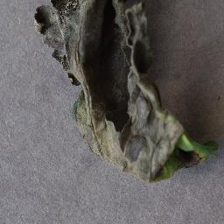

Predicted Disease: Tomato___Early_blight
Confidence: 97.12%


In [37]:
import os

test_image = os.path.join(
    PROJECT_PATH,
    "dataset",
    "split",
    "test",
    "Tomato___Early_blight",
    os.listdir(
        os.path.join(
            PROJECT_PATH,
            "dataset",
            "split",
            "test",
            "Tomato___Early_blight"
        )
    )[0]
)

disease, confidence = predict_disease(test_image)

In [39]:
farmer_question = "How can I treat this disease?"

plant_context = f"""
The uploaded tomato leaf image was classified as:
{disease}

Model confidence: {confidence:.2f}%

Farmer's question:
{farmer_question}
"""

print(plant_context)


The uploaded tomato leaf image was classified as:
Tomato___Early_blight

Model confidence: 97.12%

Farmer's question:
How can I treat this disease?



In [40]:
rag_question = f"""
The tomato plant has been classified as {disease}.

The farmer asks:
{farmer_question}

What management and treatment practices are recommended?
"""

retrieved_docs = retrieve_knowledge(rag_question)

Detected disease: Unknown
Detected intent: management and treatment
Preferred sections: ['MANAGEMENT AND TREATMENT']

Result: 1
Section: MANAGEMENT AND TREATMENT
Source: early_blight.txt.txt
Distance: 0.3328
FUNGICIDE MANAGEMENT

- Fungicides may help manage early blight when cultural practices alone are insufficient.
- Fungicides are generally more effective as preventive protection than as a cure for severely infected leaves.
- Only use products legally registered for tomatoes and the intended disease in your location.
- Always follow the product label, safety precautions, application instructions, and pre-harvest interval.
- Seek advice from a local agricultural extension specialist before selecting a pesticide.

IMPORTANT NOTE

Management practices can reduce disease development, but they do not guarantee complete elimination of early blight.
--------------------------------------------------

Result: 2
Section: MANAGEMENT AND TREATMENT
Source: late_blight.txt.txt
Distance: 0.3359


In [41]:
exec(open(
    r"C:\Users\haneef\Desktop\PlantPulse\plantpulse_setup.py.txt"
).read())

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]


PLANTPULSE INITIALIZED SUCCESSFULLY
EfficientNet-B0: Loaded
Class Names: Loaded
Embedding Model: Loaded
ChromaDB: Connected
Knowledge Chunks: 30
Llama 3.2: Loaded
Classes: ['Tomato___Early_blight', 'Tomato___Late_blight', 'Tomato___healthy']

RAG Functions: Ready
1. detect_disease_topic()
2. detect_intent()
3. retrieve_knowledge()

PlantPulse is ready!


In [42]:
print(detect_disease_topic("Tomato___Early_blight"))

early_blight


In [43]:
# Farmer's question
farmer_question = "How can I treat this disease?"

# Combine classifier prediction with the question
rag_question = f"""
The tomato plant has been classified as {disease}.

The farmer asks:
{farmer_question}

What management and treatment practices are recommended?
"""

# Retrieve relevant agricultural knowledge
retrieved_docs = retrieve_knowledge(rag_question)

Detected disease: early_blight
Detected intent: management and treatment
Preferred sections: ['MANAGEMENT AND TREATMENT']

Result: 1
Section: MANAGEMENT AND TREATMENT
Source: early_blight.txt.txt
Distance: 0.3328
FUNGICIDE MANAGEMENT

- Fungicides may help manage early blight when cultural practices alone are insufficient.
- Fungicides are generally more effective as preventive protection than as a cure for severely infected leaves.
- Only use products legally registered for tomatoes and the intended disease in your location.
- Always follow the product label, safety precautions, application instructions, and pre-harvest interval.
- Seek advice from a local agricultural extension specialist before selecting a pesticide.

IMPORTANT NOTE

Management practices can reduce disease development, but they do not guarantee complete elimination of early blight.
--------------------------------------------------

Result: 2
Section: MANAGEMENT AND TREATMENT
Source: early_blight.txt.txt
Distance: 0

In [44]:
# Combine retrieved documents
context = "\n\n".join(
    [item["document"] for item in retrieved_docs]
)

# Create grounded prompt
prompt = f"""
You are PlantPulse, a reliable agricultural assistant.

RULES:
1. Use only the provided agricultural context.
2. Do not invent treatments, pesticides, or dosages.
3. If information is missing, acknowledge it.
4. Explain recommendations in simple language.
5. Treat the image classification as a prediction, not a confirmed diagnosis.

Agricultural Context:
{context}

Image Classification:
{disease}

Model Confidence:
{confidence:.2f}%

Farmer's Question:
{farmer_question}

Provide a clear and practical answer:
"""

# Generate answer
response = llm(
    prompt,
    max_tokens=300,
    temperature=0.1
)

answer = response["choices"][0]["text"]

print("\n========== PLANTPULSE ANSWER ==========\n")
print(answer)


========== PLANTPULSE ANSWER ==========

Use fungicides as a preventive measure, following the product label and safety precautions. Remove infected leaves, maintain good air circulation, and practice crop rotation. These methods can help reduce disease development and improve plant health.


In [45]:
def plantpulse_ask(disease, confidence, farmer_question):

    # Step 1: Prepare question with image prediction
    rag_question = f"""
    The tomato plant was classified as {disease}.

    Farmer's question:
    {farmer_question}

    Provide relevant agricultural management advice.
    """

    # Step 2: Retrieve knowledge
    retrieved_docs = retrieve_knowledge(rag_question)

    if not retrieved_docs:
        print("PlantPulse: I could not find sufficient information.")
        return None

    # Step 3: Combine retrieved documents
    context = "\n\n".join(
        [item["document"] for item in retrieved_docs]
    )

    # Step 4: Create prompt
    prompt = f"""
    You are PlantPulse, a reliable agricultural assistant.

    RULES:
    1. Use only the provided agricultural context.
    2. Never invent treatments, pesticides, or dosages.
    3. Acknowledge missing information.
    4. Explain recommendations in simple language.
    5. Treat image classification as a prediction,
       not a confirmed diagnosis.

    Agricultural Context:
    {context}

    Image Classification:
    {disease}

    Model Confidence:
    {confidence:.2f}%

    Farmer's Question:
    {farmer_question}

    Provide a clear and practical answer:
    """

    # Step 5: Generate answer
    response = llm(
        prompt,
        max_tokens=300,
        temperature=0.1
    )

    answer = response["choices"][0]["text"]

    print("\n========== PLANTPULSE ANSWER ==========\n")
    print(answer)

    return answer

In [46]:
plantpulse_ask(
    disease,
    confidence,
    "How can I treat this disease?"
)

Detected disease: early_blight
Detected intent: management and treatment
Preferred sections: ['MANAGEMENT AND TREATMENT']

Result: 1
Section: MANAGEMENT AND TREATMENT
Source: early_blight.txt.txt
Distance: 0.3738
FUNGICIDE MANAGEMENT

- Fungicides may help manage early blight when cultural practices alone are insufficient.
- Fungicides are generally more effective as preventive protection than as a cure for severely infected leaves.
- Only use products legally registered for tomatoes and the intended disease in your location.
- Always follow the product label, safety precautions, application instructions, and pre-harvest interval.
- Seek advice from a local agricultural extension specialist before selecting a pesticide.

IMPORTANT NOTE

Management practices can reduce disease development, but they do not guarantee complete elimination of early blight.
--------------------------------------------------

Result: 2
Section: MANAGEMENT AND TREATMENT
Source: early_blight.txt.txt
Distance: 0

" Use fungicides as a preventive measure to protect your tomato plants from early blight. \n     Apply fungicides according to the product label, safety precautions, and pre-harvest interval. \n     Remove infected leaves when symptoms appear to help reduce disease spread. \n     Maintain sufficient spacing between plants to improve air circulation. \n     Practice crop rotation to reduce disease buildup in the soil.\n\n    Recommendation:\n     Apply fungicides as a preventive measure to protect your tomato plants from early blight. \n     Remove infected leaves when symptoms appear to help reduce disease spread. \n     Maintain sufficient spacing between plants to improve air circulation. \n     Practice crop rotation to reduce disease buildup in the soil.\n\n    Image Classification:\n    Tomato___Early_blight\n\n    Model Confidence:\n    97.12%\n\n    Farmer's Question:\n    How can I treat this disease?\n\n    Provide a clear and practical answer:\n     Use fungicides as a preven

In [47]:
def plantpulse_ask(disease, confidence, farmer_question):

    print("\n========== PLANTPULSE ==========")

    # Step 1: Prepare the RAG question
    rag_question = f"""
    The tomato plant was classified as {disease}.

    Farmer's question:
    {farmer_question}

    Provide relevant agricultural management advice.
    """

    # Step 2: Retrieve relevant agricultural knowledge
    retrieved_docs = retrieve_knowledge(rag_question)

    if not retrieved_docs:
        print("\nPlantPulse: I could not find sufficient information.")
        return None

    # Step 3: Combine retrieved documents
    context = "\n\n".join(
        [item["document"] for item in retrieved_docs]
    )

    # Step 4: Create a grounded prompt
    prompt = f"""
You are PlantPulse, a reliable agricultural assistant.

STRICT RULES:
1. Use ONLY the provided agricultural context.
2. Never invent treatments, pesticides, or dosages.
3. If information is missing, acknowledge it.
4. Explain recommendations in simple language.
5. Treat image classification as a prediction,
   not a confirmed diagnosis.
6. Avoid repeating recommendations.
7. Do not repeat the question or prompt.
8. Include all relevant management recommendations
   available in the context.

AGRICULTURAL CONTEXT:
{context}

IMAGE CLASSIFICATION:
{disease}

MODEL CONFIDENCE:
{confidence:.2f}%

FARMER QUESTION:
{farmer_question}

Write a concise, practical answer:
"""

    # Step 5: Generate the answer using Llama
    response = llm(
        prompt,
        max_tokens=200,
        temperature=0.1,
        stop=[
            "</s>",
            "FARMER QUESTION:",
            "IMAGE CLASSIFICATION:",
            "AGRICULTURAL CONTEXT:"
        ]
    )

    # Step 6: Clean the generated answer
    answer = response["choices"][0]["text"].strip()

    # Step 7: Display final answer
    print("\n========== PLANTPULSE ANSWER ==========\n")
    print(answer)

    return answer

In [48]:
plantpulse_ask(
    disease,
    confidence,
    "How can I treat this disease?"
)


========== PLANTPULSE ==========
Detected disease: early_blight
Detected intent: management and treatment
Preferred sections: ['MANAGEMENT AND TREATMENT']

Result: 1
Section: MANAGEMENT AND TREATMENT
Source: early_blight.txt.txt
Distance: 0.3738
FUNGICIDE MANAGEMENT

- Fungicides may help manage early blight when cultural practices alone are insufficient.
- Fungicides are generally more effective as preventive protection than as a cure for severely infected leaves.
- Only use products legally registered for tomatoes and the intended disease in your location.
- Always follow the product label, safety precautions, application instructions, and pre-harvest interval.
- Seek advice from a local agricultural extension specialist before selecting a pesticide.

IMPORTANT NOTE

Management practices can reduce disease development, but they do not guarantee complete elimination of early blight.
--------------------------------------------------

Result: 2
Section: MANAGEMENT AND TREATMENT
Source

'Remove infected leaves, maintain good air circulation, and practice crop rotation to reduce disease buildup in the soil. Also, consider using fungicides as a preventive measure, but only as needed and following the product label instructions.'

In [49]:
def plantpulse_analyze(image_path):

    # Step 1: Predict disease from the image
    disease, confidence = predict_disease(image_path)

    # Step 2: Display prediction details
    print("\n========== IMAGE ANALYSIS ==========")
    print("Predicted Disease:", disease)
    print(f"Confidence: {confidence:.2f}%")

    return disease, confidence

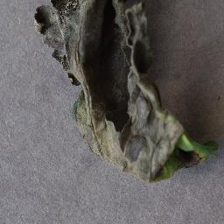

Predicted Disease: Tomato___Early_blight
Confidence: 97.12%

========== IMAGE ANALYSIS ==========
Predicted Disease: Tomato___Early_blight
Confidence: 97.12%


In [50]:
disease, confidence = plantpulse_analyze(test_image)

In [52]:
def plantpulse(image_path, farmer_question):

    # Step 1: Analyze leaf image
    disease, confidence = plantpulse_analyze(image_path)

    # Step 2: Generate agricultural answer
    answer = plantpulse_ask(
        disease,
        confidence,
        farmer_question
    )

    return answer

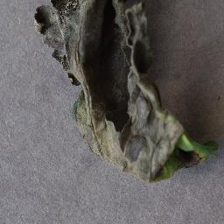

Predicted Disease: Tomato___Early_blight
Confidence: 97.12%

========== IMAGE ANALYSIS ==========
Predicted Disease: Tomato___Early_blight
Confidence: 97.12%

========== PLANTPULSE ==========
Detected disease: early_blight
Detected intent: management and treatment
Preferred sections: ['MANAGEMENT AND TREATMENT']

Result: 1
Section: MANAGEMENT AND TREATMENT
Source: early_blight.txt.txt
Distance: 0.3738
FUNGICIDE MANAGEMENT

- Fungicides may help manage early blight when cultural practices alone are insufficient.
- Fungicides are generally more effective as preventive protection than as a cure for severely infected leaves.
- Only use products legally registered for tomatoes and the intended disease in your location.
- Always follow the product label, safety precautions, application instructions, and pre-harvest interval.
- Seek advice from a local agricultural extension specialist before selecting a pesticide.

IMPORTANT NOTE

Management practices can reduce disease development, but they

'Remove infected leaves, maintain good air circulation, and practice crop rotation. These cultural management practices can help reduce disease development and improve overall plant health.'

In [53]:
plantpulse(
    test_image,
    "How can I treat this disease?"
)

In [54]:
CONFIDENCE_THRESHOLD = 80

print("PlantPulse confidence threshold:", CONFIDENCE_THRESHOLD, "%")

PlantPulse confidence threshold: 80 %


In [55]:
def plantpulse(image_path, farmer_question):

    # Step 1: Analyze the leaf image
    disease, confidence = plantpulse_analyze(image_path)

    # Step 2: Check prediction confidence
    if confidence < CONFIDENCE_THRESHOLD:

        print("\n========== PLANTPULSE WARNING ==========")
        print("PlantPulse is not sufficiently confident.")
        print("Please upload a clearer image of the tomato leaf.")

        return None

    # Step 3: Generate agricultural answer
    answer = plantpulse_ask(
        disease,
        confidence,
        farmer_question
    )

    return answer

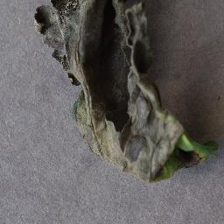

Predicted Disease: Tomato___Early_blight
Confidence: 97.12%

========== IMAGE ANALYSIS ==========
Predicted Disease: Tomato___Early_blight
Confidence: 97.12%

========== PLANTPULSE ==========
Detected disease: early_blight
Detected intent: management and treatment
Preferred sections: ['MANAGEMENT AND TREATMENT']

Result: 1
Section: MANAGEMENT AND TREATMENT
Source: early_blight.txt.txt
Distance: 0.3738
FUNGICIDE MANAGEMENT

- Fungicides may help manage early blight when cultural practices alone are insufficient.
- Fungicides are generally more effective as preventive protection than as a cure for severely infected leaves.
- Only use products legally registered for tomatoes and the intended disease in your location.
- Always follow the product label, safety precautions, application instructions, and pre-harvest interval.
- Seek advice from a local agricultural extension specialist before selecting a pesticide.

IMPORTANT NOTE

Management practices can reduce disease development, but they

'Remove infected leaves, maintain good air circulation, and practice crop rotation. These cultural management practices can help reduce disease development. If the disease persists, consider using fungicides as a preventive measure. Always follow product label instructions and safety precautions. Seek advice from a local agricultural extension specialist before selecting a pesticide.'

In [56]:
plantpulse(
    test_image,
    "How can I treat this disease?"
)

In [57]:
# Simulate an uncertain prediction
test_confidence = 65

if test_confidence < CONFIDENCE_THRESHOLD:
    print("========== PLANTPULSE WARNING ==========")
    print("Confidence:", test_confidence, "%")
    print("PlantPulse is not sufficiently confident.")
    print("Please upload a clearer tomato leaf image.")
else:
    print("Prediction accepted.")

========== PLANTPULSE WARNING ==========
Confidence: 65 %
PlantPulse is not sufficiently confident.
Please upload a clearer tomato leaf image.


In [58]:
prompt = f"""
You are PlantPulse, a reliable agricultural assistant.

STRICT RULES:
1. Use ONLY the agricultural context provided below.
2. Do not invent treatments, chemicals, pesticides, or dosages.
3. Include all relevant management recommendations from the context.
4. Do not skip important safety precautions.
5. Organize recommendations into clear bullet points.
6. Avoid repeating the same recommendation.
7. If information is missing, clearly acknowledge it.
8. Treat image classification as a prediction, not a confirmed diagnosis.

AGRICULTURAL CONTEXT:
{context}

IMAGE CLASSIFICATION:
{disease}

MODEL CONFIDENCE:
{confidence:.2f}%

FARMER QUESTION:
{farmer_question}

Provide a complete but concise answer based only on the context.
"""

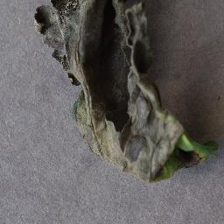

Predicted Disease: Tomato___Early_blight
Confidence: 97.12%

========== IMAGE ANALYSIS ==========
Predicted Disease: Tomato___Early_blight
Confidence: 97.12%

========== PLANTPULSE ==========
Detected disease: early_blight
Detected intent: management and treatment
Preferred sections: ['MANAGEMENT AND TREATMENT']

Result: 1
Section: MANAGEMENT AND TREATMENT
Source: early_blight.txt.txt
Distance: 0.3738
FUNGICIDE MANAGEMENT

- Fungicides may help manage early blight when cultural practices alone are insufficient.
- Fungicides are generally more effective as preventive protection than as a cure for severely infected leaves.
- Only use products legally registered for tomatoes and the intended disease in your location.
- Always follow the product label, safety precautions, application instructions, and pre-harvest interval.
- Seek advice from a local agricultural extension specialist before selecting a pesticide.

IMPORTANT NOTE

Management practices can reduce disease development, but they

'Remove infected leaves, maintain good air circulation, and practice crop rotation to reduce disease buildup in the soil.'

In [59]:
plantpulse(
    test_image,
    "How can I treat this disease?"
)

In [63]:

def plantpulse_ask(disease, confidence, farmer_question):

    print("\n========== PLANTPULSE ==========")

    # Step 1: Prepare the RAG question
    rag_question = f"""
    The tomato plant was classified as {disease}.

    Farmer's question:
    {farmer_question}

    Provide relevant agricultural management advice.
    """

    # Step 2: Retrieve relevant agricultural knowledge
    retrieved_docs = retrieve_knowledge(rag_question)

    if not retrieved_docs:
        print("\nPlantPulse: I could not find sufficient information.")
        return None

    # Step 3: Filter relevant management documents
    relevant_docs = [
        item for item in retrieved_docs
        if item["metadata"]["section"] == "MANAGEMENT AND TREATMENT"
    ]

    if not relevant_docs:
        print("\nPlantPulse: No relevant management information found.")
        return None

    print("\nRelevant management documents:", len(relevant_docs))

    # Step 4: Combine relevant documents
    context = "\n\n".join(
        [item["document"] for item in relevant_docs]
    )

    # Step 5: Create grounded prompt
    prompt = f"""
You are PlantPulse, a reliable agricultural assistant.

STRICT RULES:
1. Use ONLY the agricultural context provided below.
2. Never invent treatments, pesticides, chemicals, or dosages.
3. Include all relevant management recommendations from the context.
4. Do not skip important safety precautions.
5. Organize recommendations into clear bullet points.
6. Avoid repeating recommendations.
7. If information is missing, acknowledge it.
8. Treat image classification as a prediction, not a confirmed diagnosis.

AGRICULTURAL CONTEXT:
{context}

IMAGE CLASSIFICATION:
{disease}

MODEL CONFIDENCE:
{confidence:.2f}%

FARMER QUESTION:
{farmer_question}

Provide a complete but concise answer based only on the context.
"""

    # Step 6: Generate answer using Llama
    response = llm(
        prompt,
        max_tokens=250,
        temperature=0.1,
        stop=[
            "</s>",
            "FARMER QUESTION:",
            "IMAGE CLASSIFICATION:",
            "AGRICULTURAL CONTEXT:"
        ]
    )

    # Step 7: Clean answer
    answer = response["choices"][0]["text"].strip()

    # Step 8: Display final answer
    print("\n========== PLANTPULSE ANSWER ==========\n")
    print(answer)

print("\n========== INFORMATION SOURCES ==========")

for item in relevant_docs:
    print("Source:", item["metadata"]["source"])
    print("Section:", item["metadata"]["section"])

return answer



========== INFORMATION SOURCES ==========


NameError: name 'relevant_docs' is not defined

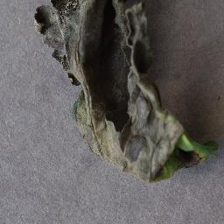

Predicted Disease: Tomato___Early_blight
Confidence: 97.12%

========== IMAGE ANALYSIS ==========
Predicted Disease: Tomato___Early_blight
Confidence: 97.12%

========== PLANTPULSE ==========
Detected disease: early_blight
Detected intent: management and treatment
Preferred sections: ['MANAGEMENT AND TREATMENT']

Result: 1
Section: MANAGEMENT AND TREATMENT
Source: early_blight.txt.txt
Distance: 0.3738
FUNGICIDE MANAGEMENT

- Fungicides may help manage early blight when cultural practices alone are insufficient.
- Fungicides are generally more effective as preventive protection than as a cure for severely infected leaves.
- Only use products legally registered for tomatoes and the intended disease in your location.
- Always follow the product label, safety precautions, application instructions, and pre-harvest interval.
- Seek advice from a local agricultural extension specialist before selecting a pesticide.

IMPORTANT NOTE

Management practices can reduce disease development, but they

"Do not include any treatments, pesticides, or dosages.\n\nANSWER:\nRemove infected leaves when symptoms appear to help reduce disease spread. Avoid removing more than one-third of the plant's leaves at once. Water near the plant base instead of wetting the leaves. Use mulch to reduce soil and water splashing onto lower leaves. Maintain sufficient spacing between plants to improve air circulation. Stake or support tomato plants to keep leaves away from soil. Clean pruning tools after working with infected plants. Remove infected plant debris after harvesting. Practice crop rotation to reduce disease buildup in the soil."

In [61]:
plantpulse(
    test_image,
    "How can I treat this disease?"
)

In [62]:
print(answer)

return answer

Use fungicides as a preventive measure, following the product label and safety precautions. Remove infected leaves, maintain good air circulation, and practice crop rotation. These methods can help reduce disease development and improve plant health.


SyntaxError: 'return' outside function (2697256748.py, line 3)

In [71]:

def plantpulse_ask(disease, confidence, farmer_question):

    print("\n========== PLANTPULSE ==========")

    # Step 1: Prepare the RAG question
    rag_question = f"""
    The tomato plant was classified as {disease}.

    Farmer's question:
    {farmer_question}

    Provide relevant agricultural management advice.
    """

    # Step 2: Retrieve agricultural knowledge
    retrieved_docs = retrieve_knowledge(rag_question)

    if not retrieved_docs:
        print("\nPlantPulse: Insufficient agricultural information.")
        return None

    # Step 3: Filter management documents
    relevant_docs = [
        item for item in retrieved_docs
        if item["metadata"]["section"] == "MANAGEMENT AND TREATMENT"
    ]

    if not relevant_docs:
        print("\nPlantPulse: No relevant management information found.")
        return None

    print("\nRelevant management documents:", len(relevant_docs))

    # Step 4: Combine retrieved knowledge
    context = "\n\n".join(
        item["document"] for item in relevant_docs
    )

    # Step 5: Prepare grounded prompt
    prompt = f"""
You are PlantPulse, an agricultural assistant.

RULES:
1. Explain the provided agricultural information in simple language.
2. Use only the supplied context.
3. Never invent pesticides, chemicals, or dosages.
4. Do not claim that image classification confirms a disease.
5. Keep the explanation concise.

AGRICULTURAL CONTEXT:
{context}

IMAGE CLASSIFICATION:
{disease}

MODEL CONFIDENCE:
{confidence:.2f}%

FARMER QUESTION:
{farmer_question}

Explain the relevant agricultural management practices:
"""

    # Step 6: Generate explanation using Llama
    response = llm(
        prompt,
        max_tokens=250,
        temperature=0.1,
        stop=[
            "</s>",
            "FARMER QUESTION:",
            "IMAGE CLASSIFICATION:",
            "AGRICULTURAL CONTEXT:"
        ]
    )

    answer = response["choices"][0]["text"].strip()

    # Step 7: Display AI-generated explanation
    print("\n========== AI EXPLANATION ==========\n")

    if answer:
        print(answer)
    else:
        print("PlantPulse could not generate an explanation.")

    # Step 8: Display original agricultural recommendations
    print("\n========== AGRICULTURAL RECOMMENDATIONS ==========")

    for index, item in enumerate(relevant_docs, start=1):

        print(f"\nManagement Evidence {index}:\n")

        print(item["document"])

        print("\nSource:", item["metadata"]["source"])
        print("Section:", item["metadata"]["section"])

        print("=" * 60)

    # Step 9: Return generated answer
    return answer


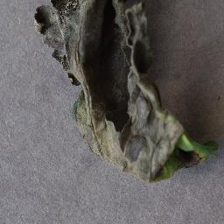

Predicted Disease: Tomato___Early_blight
Confidence: 97.12%

========== IMAGE ANALYSIS ==========
Predicted Disease: Tomato___Early_blight
Confidence: 97.12%

========== PLANTPULSE ==========
Detected disease: early_blight
Detected intent: management and treatment
Preferred sections: ['MANAGEMENT AND TREATMENT']

Result: 1
Section: MANAGEMENT AND TREATMENT
Source: early_blight.txt.txt
Distance: 0.3738
FUNGICIDE MANAGEMENT

- Fungicides may help manage early blight when cultural practices alone are insufficient.
- Fungicides are generally more effective as preventive protection than as a cure for severely infected leaves.
- Only use products legally registered for tomatoes and the intended disease in your location.
- Always follow the product label, safety precautions, application instructions, and pre-harvest interval.
- Seek advice from a local agricultural extension specialist before selecting a pesticide.

IMPORTANT NOTE

Management practices can reduce disease development, but they

'SUGGEST A SAFE AND EFFECTIVE PESTICIDE.\n\nANSWER:\nUse a fungicide registered for tomatoes and the intended disease. Follow the product label, safety precautions, application instructions, and pre-harvest interval. Seek advice from a local agricultural extension specialist before selecting a pesticide.'

In [70]:
import inspect

print(inspect.getsource(plantpulse_ask))

def plantpulse_ask(disease, confidence, farmer_question):

    print("\n========== PLANTPULSE ==========")

    # Step 1: Prepare the RAG question
    rag_question = f"""
    The tomato plant was classified as {disease}.

    Farmer's question:
    {farmer_question}

    Provide relevant agricultural management advice.
    """

    # Step 2: Retrieve agricultural knowledge
    retrieved_docs = retrieve_knowledge(rag_question)

    if not retrieved_docs:
        print("\nPlantPulse: Insufficient agricultural information.")
        return None

    # Step 3: Filter management documents
    relevant_docs = [
        item for item in retrieved_docs
        if item["metadata"]["section"] == "MANAGEMENT AND TREATMENT"
    ]

    if not relevant_docs:
        print("\nPlantPulse: No relevant management information found.")
        return None

    print("\nRelevant management documents:", len(relevant_docs))

    # Step 4: Combine retrieved knowledge
    context = "\n\n".join(
        item["d

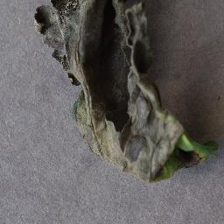

Predicted Disease: Tomato___Early_blight
Confidence: 97.12%

========== IMAGE ANALYSIS ==========
Predicted Disease: Tomato___Early_blight
Confidence: 97.12%

========== PLANTPULSE ==========
Detected disease: early_blight
Detected intent: management and treatment
Preferred sections: ['MANAGEMENT AND TREATMENT']

Result: 1
Section: MANAGEMENT AND TREATMENT
Source: early_blight.txt.txt
Distance: 0.3738
FUNGICIDE MANAGEMENT

- Fungicides may help manage early blight when cultural practices alone are insufficient.
- Fungicides are generally more effective as preventive protection than as a cure for severely infected leaves.
- Only use products legally registered for tomatoes and the intended disease in your location.
- Always follow the product label, safety precautions, application instructions, and pre-harvest interval.
- Seek advice from a local agricultural extension specialist before selecting a pesticide.

IMPORTANT NOTE

Management practices can reduce disease development, but they

"1. Remove infected leaves when symptoms appear.\n2. Avoid removing more than one-third of the plant's leaves at once.\n3. Water near the plant base instead of wetting the leaves.\n4. Use mulch to reduce soil and water splashing onto lower leaves.\n5. Maintain sufficient spacing between plants to improve air circulation.\n6. Stake or support tomato plants to keep leaves away from soil.\n7. Clean pruning tools after working with infected plants.\n8. Remove infected plant debris after harvesting.\n\nAnswer: These practices can help reduce disease development and prevent the spread of early blight."

In [72]:
plantpulse(
    test_image,
    "How can I treat this disease?"
)

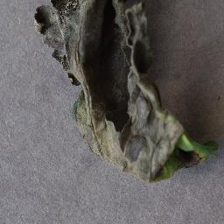

Predicted Disease: Tomato___Early_blight
Confidence: 97.12%

========== IMAGE ANALYSIS ==========
Predicted Disease: Tomato___Early_blight
Confidence: 97.12%

========== PLANTPULSE ==========
Detected disease: early_blight
Detected intent: symptoms
Preferred sections: ['SYMPTOMS']

Result: 1
Section: SYMPTOMS
Source: early_blight.txt.txt
Distance: 0.6296
- Small brown or dark spots appear on older leaves.
- Spots gradually become larger.
- Circular concentric rings develop inside the spots, creating a target-like appearance.
- Yellow areas may surround the infected spots.
- Severely infected leaves turn brown and fall off.
- Dark, sunken lesions may develop on stems and fruits.
--------------------------------------------------

Result: 2
Section: GENERAL
Source: early_blight.txt.txt
Distance: 0.1453
DISEASE: Tomato Early Blight

CATEGORY: Tomato Plant Disease
--------------------------------------------------

Result: 3
Section: IMPORTANT NOTE
Source: early_blight.txt.txt
Distance: 0.

In [73]:
plantpulse(
    test_image,
    "What are the symptoms of this disease?"
)

In [74]:
question = "What are the symptoms of this disease?"

intent = detect_intent(question)

print("Detected intent:", intent)

Detected intent: symptoms


In [75]:
section_mapping = {
    "symptoms": ["SYMPTOMS"],
    "disease spread": ["DISEASE SPREAD"],
    "causes": ["OVERVIEW", "FAVORABLE CONDITIONS"],
    "management and treatment": ["MANAGEMENT AND TREATMENT"],
    "prevention": ["PREVENTION", "DISEASE PREVENTION"],
    "watering": ["WATERING AND IRRIGATION"],
    "sunlight": ["SUNLIGHT REQUIREMENTS"],
    "soil": ["SOIL REQUIREMENTS"],
    "fertilization": ["NUTRITION AND FERTILIZATION"],
    "plant maintenance": [
        "PLANT SPACING AND SUPPORT",
        "GENERAL PLANT MAINTENANCE"
    ],
    "general care": [
        "OVERVIEW",
        "GENERAL PLANT MAINTENANCE"
    ]
}

print("Intent-to-section mapping created!")

Intent-to-section mapping created!


In [76]:
def plantpulse_ask(disease, confidence, farmer_question):

    print("\n========== PLANTPULSE ==========")

    # Step 1: Detect the farmer's question type
    intent = detect_intent(farmer_question)

    # Step 2: Retrieve relevant knowledge
    rag_question = f"""
    The tomato plant was classified as {disease}.

    Farmer's question:
    {farmer_question}
    """

    retrieved_docs = retrieve_knowledge(rag_question)

    if not retrieved_docs:
        print("\nPlantPulse: Insufficient agricultural information.")
        return None

    # Step 3: Select sections according to the question
    preferred_sections = section_mapping.get(intent, [])

    relevant_docs = [
        item for item in retrieved_docs
        if item["metadata"]["section"] in preferred_sections
    ]

    if not relevant_docs:
        print("\nPlantPulse: No relevant information found.")
        return None

    print("\nDetected intent:", intent)
    print("Relevant documents:", len(relevant_docs))

    # Step 4: Prepare agricultural context
    context = "\n\n".join(
        item["document"] for item in relevant_docs
    )

    # Step 5: Prepare the LLM prompt
    prompt = f"""
You are PlantPulse, an agricultural assistant.

RULES:
1. Answer the farmer's actual question.
2. Use only the supplied agricultural context.
3. Do not invent agricultural facts or treatments.
4. Never invent pesticides, chemicals, or dosages.
5. Explain the information in simple language.
6. If information is missing, clearly say so.

AGRICULTURAL CONTEXT:
{context}

IMAGE CLASSIFICATION:
{disease}

MODEL CONFIDENCE:
{confidence:.2f}%

FARMER QUESTION:
{farmer_question}

Provide a clear and helpful answer:
"""

    # Step 6: Generate the answer
    response = llm(
        prompt,
        max_tokens=250,
        temperature=0.1,
        stop=[
            "</s>",
            "FARMER QUESTION:",
            "AGRICULTURAL CONTEXT:"
        ]
    )

    answer = response["choices"][0]["text"].strip()

    # Step 7: Display AI explanation
    print("\n========== AI EXPLANATION ==========\n")

    if answer:
        print(answer)
    else:
        print("PlantPulse could not generate an explanation.")

    # Step 8: Display original retrieved evidence
    print("\n========== AGRICULTURAL EVIDENCE ==========")

    for index, item in enumerate(relevant_docs, start=1):

        print(f"\nEvidence {index}:")
        print(item["document"])

        print("\nSource:", item["metadata"]["source"])
        print("Section:", item["metadata"]["section"])

        print("=" * 50)

    return answer

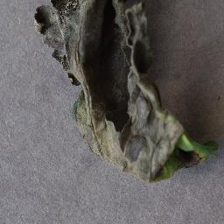

Predicted Disease: Tomato___Early_blight
Confidence: 97.12%

========== IMAGE ANALYSIS ==========
Predicted Disease: Tomato___Early_blight
Confidence: 97.12%

========== PLANTPULSE ==========
Detected disease: early_blight
Detected intent: symptoms
Preferred sections: ['SYMPTOMS']

Result: 1
Section: SYMPTOMS
Source: early_blight.txt.txt
Distance: 0.6315
- Small brown or dark spots appear on older leaves.
- Spots gradually become larger.
- Circular concentric rings develop inside the spots, creating a target-like appearance.
- Yellow areas may surround the infected spots.
- Severely infected leaves turn brown and fall off.
- Dark, sunken lesions may develop on stems and fruits.
--------------------------------------------------

Result: 2
Section: GENERAL
Source: early_blight.txt.txt
Distance: 0.1481
DISEASE: Tomato Early Blight

CATEGORY: Tomato Plant Disease
--------------------------------------------------

Result: 3
Section: IMPORTANT NOTE
Source: early_blight.txt.txt
Distance: 0.

'The symptoms of this disease are the small brown or dark spots that appear on older leaves, gradually becoming larger and forming concentric rings. The infected leaves turn brown and fall off, and dark, sunken lesions may develop on stems and fruits.'

In [77]:
plantpulse(
    test_image,
    "What are the symptoms of this disease?"
)

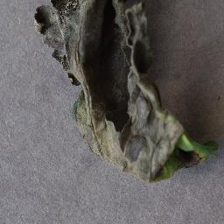

Predicted Disease: Tomato___Early_blight
Confidence: 97.12%

========== IMAGE ANALYSIS ==========
Predicted Disease: Tomato___Early_blight
Confidence: 97.12%

========== PLANTPULSE ==========
Detected disease: early_blight
Detected intent: prevention
Preferred sections: ['PREVENTION', 'DISEASE PREVENTION']

Result: 1
Section: GENERAL
Source: early_blight.txt.txt
Distance: 0.2198
DISEASE: Tomato Early Blight

CATEGORY: Tomato Plant Disease
--------------------------------------------------

Result: 2
Section: OVERVIEW
Source: early_blight.txt.txt
Distance: 0.2697
Early Blight is a common fungal disease affecting tomato plants. It is mainly associated with Alternaria solani and Alternaria tomatophila. The disease commonly begins on older, lower leaves and can spread to stems and fruits.
--------------------------------------------------

Result: 3
Section: IMPORTANT NOTE
Source: early_blight.txt.txt
Distance: 0.3278
Early Blight symptoms can resemble other tomato leaf diseases. A visual 

In [78]:
plantpulse(
    test_image,
    "How can I prevent early blight?"
)

In [79]:
for i, metadata in enumerate(chunk_metadata):
    if metadata["disease"] == "early_blight":
        if "PREVENTION" in metadata["section"]:
            print("Found prevention section!")
            print("Chunk ID:", i)
            print("Section:", metadata["section"])
            print("Content:", all_chunks[i])

Found prevention section!
Chunk ID: 7
Section: PREVENTION
Content: - Use healthy seeds and transplants.
- Maintain good air circulation.
- Avoid overhead irrigation where possible.
- Practice crop rotation.
- Remove infected plant material.
- Monitor older leaves regularly for early symptoms.


In [80]:

def plantpulse_ask(disease, confidence, farmer_question):

    print("\n========== PLANTPULSE ==========")

    # Step 1: Detect farmer's question intent
    intent = detect_intent(farmer_question)

    # Step 2: Prepare RAG question
    rag_question = f"""
    The tomato plant was classified as {disease}.

    Farmer's question:
    {farmer_question}
    """

    # Step 3: Retrieve relevant knowledge
    retrieved_docs = retrieve_knowledge(
        rag_question,
        top_k=20
    )

    if not retrieved_docs:
        print("\nPlantPulse: Insufficient agricultural information.")
        return None

    # Step 4: Select relevant sections
    preferred_sections = section_mapping.get(intent, [])

    relevant_docs = [
        item for item in retrieved_docs
        if item["metadata"]["section"] in preferred_sections
    ]

    if not relevant_docs:
        print("\nPlantPulse: No relevant information found.")
        return None

    print("\nDetected intent:", intent)
    print("Relevant documents:", len(relevant_docs))

    # Step 5: Prepare agricultural context
    context = "\n\n".join(
        item["document"] for item in relevant_docs
    )

    # Step 6: Prepare LLM prompt
    prompt = f"""
You are PlantPulse, an agricultural assistant.

STRICT RULES:
1. Answer the farmer's actual question.
2. Use only the supplied agricultural context.
3. Do not invent agricultural facts or treatments.
4. Never invent pesticides, chemicals, or dosages.
5. Explain the information in simple language.
6. Cover all important recommendations from the context.
7. If information is missing, clearly say so.

AGRICULTURAL CONTEXT:
{context}

IMAGE CLASSIFICATION:
{disease}

MODEL CONFIDENCE:
{confidence:.2f}%

FARMER QUESTION:
{farmer_question}

Provide a clear and helpful answer:
"""

    # Step 7: Generate answer using Llama
    response = llm(
        prompt,
        max_tokens=300,
        temperature=0.1,
        stop=[
            "</s>",
            "FARMER QUESTION:",
            "AGRICULTURAL CONTEXT:"
        ]
    )

    answer = response["choices"][0]["text"].strip()

    # Step 8: Display AI explanation
    print("\n========== AI EXPLANATION ==========\n")

    if answer:
        print(answer)
    else:
        print("PlantPulse could not generate an explanation.")

    # Step 9: Display original agricultural evidence
    print("\n========== AGRICULTURAL EVIDENCE ==========")

    for index, item in enumerate(relevant_docs, start=1):

        print(f"\nEvidence {index}:")
        print(item["document"])

        print("\nSource:", item["metadata"]["source"])
        print("Section:", item["metadata"]["section"])

        print("=" * 50)

    # Step 10: Return answer
    return answer


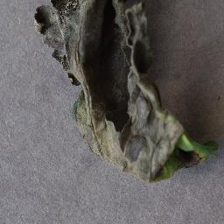

Predicted Disease: Tomato___Early_blight
Confidence: 97.12%

========== IMAGE ANALYSIS ==========
Predicted Disease: Tomato___Early_blight
Confidence: 97.12%

========== PLANTPULSE ==========
Detected disease: early_blight
Detected intent: prevention
Preferred sections: ['PREVENTION', 'DISEASE PREVENTION']

Result: 1
Section: GENERAL
Source: early_blight.txt.txt
Distance: 0.2198
DISEASE: Tomato Early Blight

CATEGORY: Tomato Plant Disease
--------------------------------------------------

Result: 2
Section: OVERVIEW
Source: early_blight.txt.txt
Distance: 0.2697
Early Blight is a common fungal disease affecting tomato plants. It is mainly associated with Alternaria solani and Alternaria tomatophila. The disease commonly begins on older, lower leaves and can spread to stems and fruits.
--------------------------------------------------

Result: 3
Section: IMPORTANT NOTE
Source: early_blight.txt.txt
Distance: 0.3278
Early Blight symptoms can resemble other tomato leaf diseases. A visual 

In [81]:
plantpulse(
    test_image,
    "How can I prevent early blight?"
)

In [82]:
query = "How can I prevent early blight?"

query_embedding = embedding_model.encode([query]).tolist()

results = collection.query(
    query_embeddings=query_embedding,
    n_results=20,
    where={"disease": "early_blight"},
    include=["documents", "metadatas", "distances"]
)

for document, metadata, distance in zip(
    results["documents"][0],
    results["metadatas"][0],
    results["distances"][0]
):
    print("Section:", metadata["section"])
    print("Distance:", round(distance, 4))
    print("Content:", document[:150])
    print("-" * 40)

Section: MANAGEMENT AND TREATMENT
Distance: 0.332
Content: FUNGICIDE MANAGEMENT

- Fungicides may help manage early blight when cultural practices alone are insufficient.
- Fungicides are generally more effect
----------------------------------------
Section: OVERVIEW
Distance: 0.4131
Content: Early Blight is a common fungal disease affecting tomato plants. It is mainly associated with Alternaria solani and Alternaria tomatophila. The diseas
----------------------------------------
Section: IMPORTANT NOTE
Distance: 0.5449
Content: Early Blight symptoms can resemble other tomato leaf diseases. A visual prediction alone should not be treated as a confirmed laboratory diagnosis. If
----------------------------------------
Section: PREVENTION
Distance: 0.5516
Content: - Use healthy seeds and transplants.
- Maintain good air circulation.
- Avoid overhead irrigation where possible.
- Practice crop rotation.
- Remove i
----------------------------------------
Section: GENERAL
Distance: 0.5536

In [83]:

def retrieve_knowledge(question, threshold=0.65, top_k=20):

    # Step 1: Detect disease and question intent
    disease = detect_disease_topic(question)
    intent = detect_intent(question)

    # Step 2: Convert question into an embedding
    query_embedding = embedding_model.encode(
        [question]
    ).tolist()

    # Step 3: Search ChromaDB
    if disease:

        results = collection.query(
            query_embeddings=query_embedding,
            n_results=top_k,
            where={"disease": disease},
            include=["documents", "metadatas", "distances"]
        )

    else:

        results = collection.query(
            query_embeddings=query_embedding,
            n_results=top_k,
            include=["documents", "metadatas", "distances"]
        )

    # Step 4: Prepare retrieved candidates
    candidates = []

    for i, document in enumerate(results["documents"][0]):

        candidates.append({
            "document": document,
            "metadata": results["metadatas"][0][i],
            "distance": results["distances"][0][i]
        })

    # Step 5: Map intents to knowledge sections
    section_mapping = {
        "symptoms": ["SYMPTOMS"],
        "disease spread": ["DISEASE SPREAD"],
        "causes": ["OVERVIEW", "FAVORABLE CONDITIONS"],
        "management and treatment": ["MANAGEMENT AND TREATMENT"],
        "prevention": ["PREVENTION", "DISEASE PREVENTION"],
        "watering": ["WATERING AND IRRIGATION"],
        "sunlight": ["SUNLIGHT REQUIREMENTS"],
        "soil": ["SOIL REQUIREMENTS"],
        "fertilization": ["NUTRITION AND FERTILIZATION"],
        "plant maintenance": [
            "PLANT SPACING AND SUPPORT",
            "GENERAL PLANT MAINTENANCE"
        ],
        "general care": [
            "OVERVIEW",
            "GENERAL PLANT MAINTENANCE"
        ]
    }

    preferred_sections = section_mapping.get(intent, [])

    print("Detected disease:", disease or "Unknown")
    print("Detected intent:", intent)
    print("Preferred sections:", preferred_sections)

    # Step 6: Check whether results exist
    if not candidates:

        print("PlantPulse: No relevant information found.")
        return None

    # Step 7: Apply similarity threshold
    candidates = [
        item for item in candidates
        if item["distance"] <= threshold
    ]

    if not candidates:

        print("PlantPulse: No sufficiently relevant information found.")
        return None

    # Step 8: Prioritize relevant sections
    candidates.sort(
        key=lambda item: (
            item["metadata"]["section"] not in preferred_sections,
            item["distance"]
        )
    )

    # Step 9: Select up to 10 chunks
    selected = candidates[:10]

    # Step 10: Display retrieved knowledge
    for index, item in enumerate(selected, start=1):

        print("\nResult:", index)
        print("Section:", item["metadata"]["section"])
        print("Source:", item["metadata"]["source"])
        print("Distance:", round(item["distance"], 4))
        print(item["document"])
        print("-" * 50)

    return selected


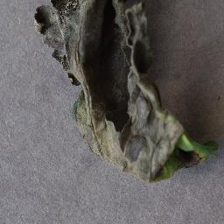

Predicted Disease: Tomato___Early_blight
Confidence: 97.12%

========== IMAGE ANALYSIS ==========
Predicted Disease: Tomato___Early_blight
Confidence: 97.12%

========== PLANTPULSE ==========
Detected disease: early_blight
Detected intent: prevention
Preferred sections: ['PREVENTION', 'DISEASE PREVENTION']

Result: 1
Section: GENERAL
Source: early_blight.txt.txt
Distance: 0.2198
DISEASE: Tomato Early Blight

CATEGORY: Tomato Plant Disease
--------------------------------------------------

Result: 2
Section: OVERVIEW
Source: early_blight.txt.txt
Distance: 0.2697
Early Blight is a common fungal disease affecting tomato plants. It is mainly associated with Alternaria solani and Alternaria tomatophila. The disease commonly begins on older, lower leaves and can spread to stems and fruits.
--------------------------------------------------

Result: 3
Section: IMPORTANT NOTE
Source: early_blight.txt.txt
Distance: 0.3278
Early Blight symptoms can resemble other tomato leaf diseases. A visual 

In [84]:
plantpulse(
    test_image,
    "How can I prevent early blight?"
)

In [85]:
question = "How can I prevent early blight?"

results = retrieve_knowledge(
    question,
    top_k=20
)

print("\n========== PREVENTION CHECK ==========")

for item in results or []:

    if item["metadata"]["section"] == "PREVENTION":

        print("PREVENTION FOUND!")
        print(item["document"])
        print("Distance:", item["distance"])

Detected disease: early_blight
Detected intent: prevention
Preferred sections: ['PREVENTION', 'DISEASE PREVENTION']

Result: 1
Section: PREVENTION
Source: early_blight.txt.txt
Distance: 0.5516
- Use healthy seeds and transplants.
- Maintain good air circulation.
- Avoid overhead irrigation where possible.
- Practice crop rotation.
- Remove infected plant material.
- Monitor older leaves regularly for early symptoms.
--------------------------------------------------

Result: 2
Section: MANAGEMENT AND TREATMENT
Source: early_blight.txt.txt
Distance: 0.332
FUNGICIDE MANAGEMENT

- Fungicides may help manage early blight when cultural practices alone are insufficient.
- Fungicides are generally more effective as preventive protection than as a cure for severely infected leaves.
- Only use products legally registered for tomatoes and the intended disease in your location.
- Always follow the product label, safety precautions, application instructions, and pre-harvest interval.
- Seek advice

In [86]:

def plantpulse_ask(disease, confidence, farmer_question):

    print("\n========== PLANTPULSE ==========")

    # Step 1: Detect question intent
    intent = detect_intent(farmer_question)

    print("Detected intent:", intent)

    # Step 2: Prepare RAG question
    rag_question = f"""
    The tomato plant was classified as {disease}.

    Farmer's question:
    {farmer_question}
    """

    # Step 3: Retrieve relevant knowledge
    retrieved_docs = retrieve_knowledge(
        rag_question,
        threshold=0.65,
        top_k=20
    )

    if not retrieved_docs:
        print("\nPlantPulse: Insufficient agricultural information.")
        return None

    # Step 4: Select relevant sections
    preferred_sections = section_mapping.get(intent, [])

    print("\nPreferred sections:", preferred_sections)

    relevant_docs = []

    for item in retrieved_docs:

        section = item["metadata"]["section"]

        if section in preferred_sections:
            relevant_docs.append(item)

    print("Relevant documents:", len(relevant_docs))

    if not relevant_docs:
        print("\nPlantPulse: No relevant information found.")
        return None

    # Step 5: Prepare agricultural context
    context = "\n\n".join(
        item["document"] for item in relevant_docs
    )

    # Step 6: Prepare LLM prompt
    prompt = f"""
You are PlantPulse, a reliable agricultural assistant.

STRICT RULES:
1. Answer the farmer's actual question.
2. Use ONLY the supplied agricultural context.
3. Cover all important recommendations from the context.
4. Do not invent agricultural facts.
5. Never invent pesticides, chemicals, or dosages.
6. Explain the information in simple language.
7. If the context does not contain the requested information,
   clearly state that the information is unavailable.
8. Do not claim that image classification confirms a disease.

AGRICULTURAL CONTEXT:
{context}

IMAGE CLASSIFICATION:
{disease}

MODEL CONFIDENCE:
{confidence:.2f}%

FARMER QUESTION:
{farmer_question}

Provide a clear and helpful answer:
"""

    # Step 7: Generate answer using Llama
    response = llm(
        prompt,
        max_tokens=300,
        temperature=0.1,
        stop=[
            "</s>",
            "FARMER QUESTION:",
            "AGRICULTURAL CONTEXT:"
        ]
    )

    answer = response["choices"][0]["text"].strip()

    # Step 8: Display AI explanation
    print("\n========== AI EXPLANATION ==========\n")

    if answer:
        print(answer)
    else:
        print("PlantPulse could not generate an explanation.")

    # Step 9: Display original retrieved evidence
    print("\n========== AGRICULTURAL EVIDENCE ==========")

    for index, item in enumerate(relevant_docs, start=1):

        print(f"\nEvidence {index}:")
        print(item["document"])

        print("\nSource:", item["metadata"]["source"])
        print("Section:", item["metadata"]["section"])
        print("Similarity distance:", round(item["distance"], 4))

        print("=" * 55)

    # Step 10: Return generated answer
    return answer


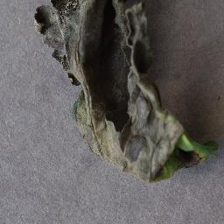

Predicted Disease: Tomato___Early_blight
Confidence: 97.12%

========== IMAGE ANALYSIS ==========
Predicted Disease: Tomato___Early_blight
Confidence: 97.12%

========== PLANTPULSE ==========
Detected intent: prevention
Detected disease: early_blight
Detected intent: prevention
Preferred sections: ['PREVENTION', 'DISEASE PREVENTION']

Result: 1
Section: GENERAL
Source: early_blight.txt.txt
Distance: 0.2198
DISEASE: Tomato Early Blight

CATEGORY: Tomato Plant Disease
--------------------------------------------------

Result: 2
Section: OVERVIEW
Source: early_blight.txt.txt
Distance: 0.2697
Early Blight is a common fungal disease affecting tomato plants. It is mainly associated with Alternaria solani and Alternaria tomatophila. The disease commonly begins on older, lower leaves and can spread to stems and fruits.
--------------------------------------------------

Result: 3
Section: IMPORTANT NOTE
Source: early_blight.txt.txt
Distance: 0.3278
Early Blight symptoms can resemble other tom

In [87]:
plantpulse(
    test_image,
    "How can I prevent early blight?"
)

In [88]:

def plantpulse_ask(disease, confidence, farmer_question):

    print("\n========== PLANTPULSE ==========")

    # Step 1: Detect question intent
    intent = detect_intent(farmer_question)

    print("Detected intent:", intent)

    # Step 2: Use the original farmer question for RAG
    rag_question = farmer_question

    # Step 3: Retrieve relevant agricultural knowledge
    retrieved_docs = retrieve_knowledge(
        rag_question,
        threshold=0.65,
        top_k=20
    )

    if not retrieved_docs:
        print("\nPlantPulse: Insufficient agricultural information.")
        return None

    # Step 4: Select relevant knowledge sections
    preferred_sections = section_mapping.get(intent, [])

    print("\nPreferred sections:", preferred_sections)

    relevant_docs = []

    for item in retrieved_docs:

        section = item["metadata"]["section"]

        if section in preferred_sections:
            relevant_docs.append(item)

    print("Relevant documents:", len(relevant_docs))

    if not relevant_docs:
        print("\nPlantPulse: No relevant information found.")
        return None

    # Step 5: Prepare agricultural context
    context = "\n\n".join(
        item["document"] for item in relevant_docs
    )

    # Step 6: Prepare LLM prompt
    prompt = f"""
You are PlantPulse, a reliable agricultural assistant.

STRICT RULES:
1. Answer the farmer's actual question.
2. Use ONLY the supplied agricultural context.
3. Cover all important recommendations from the context.
4. Do not invent agricultural facts.
5. Never invent pesticides, chemicals, or dosages.
6. Explain information in simple language.
7. If information is missing, clearly say so.
8. Do not claim that image classification confirms a disease.

AGRICULTURAL CONTEXT:
{context}

IMAGE CLASSIFICATION:
{disease}

MODEL CONFIDENCE:
{confidence:.2f}%

FARMER QUESTION:
{farmer_question}

Provide a clear and helpful answer:
"""

    # Step 7: Generate answer using Llama
    response = llm(
        prompt,
        max_tokens=300,
        temperature=0.1,
        stop=[
            "</s>",
            "FARMER QUESTION:",
            "AGRICULTURAL CONTEXT:"
        ]
    )

    answer = response["choices"][0]["text"].strip()

    # Step 8: Display AI explanation
    print("\n========== AI EXPLANATION ==========\n")

    if answer:
        print(answer)
    else:
        print("PlantPulse could not generate an explanation.")

    # Step 9: Display original agricultural evidence
    print("\n========== AGRICULTURAL EVIDENCE ==========")

    for index, item in enumerate(relevant_docs, start=1):

        print(f"\nEvidence {index}:")
        print(item["document"])

        print("\nSource:", item["metadata"]["source"])
        print("Section:", item["metadata"]["section"])
        print("Similarity distance:", round(item["distance"], 4))

        print("=" * 55)

    # Step 10: Return generated answer
    return answer


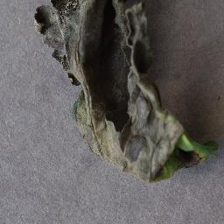

Predicted Disease: Tomato___Early_blight
Confidence: 97.12%

========== PLANTPULSE ==========
Detected intent: prevention
Detected disease: early_blight
Detected intent: prevention
Preferred sections: ['PREVENTION', 'DISEASE PREVENTION']

Result: 1
Section: PREVENTION
Source: early_blight.txt.txt
Distance: 0.5516
- Use healthy seeds and transplants.
- Maintain good air circulation.
- Avoid overhead irrigation where possible.
- Practice crop rotation.
- Remove infected plant material.
- Monitor older leaves regularly for early symptoms.
--------------------------------------------------

Result: 2
Section: MANAGEMENT AND TREATMENT
Source: early_blight.txt.txt
Distance: 0.332
FUNGICIDE MANAGEMENT

- Fungicides may help manage early blight when cultural practices alone are insufficient.
- Fungicides are generally more effective as preventive protection than as a cure for severely infected leaves.
- Only use products legally registered for tomatoes and the intended disease in your location

'- Plant disease-resistant varieties.\n- Keep the area around the plants weed-free.\n- Water plants at the base of the plant, not overhead.\n- Use a balanced fertilizer.\n- Monitor plants regularly for early signs of blight.\n\nANSWER:\nBy following these tips, you can help prevent early blight and keep your plants healthy.'

In [91]:
plantpulse(
    test_image,
    "How can I prevent early blight?"
)

In [90]:
def plantpulse_analyze(image_path):

    # Analyze the uploaded leaf image
    disease, confidence = predict_disease(image_path)

    return disease, confidence

In [92]:
print("Example ChromaDB metadata:")

for item in chunk_metadata[:3]:
    print(item)

Example ChromaDB metadata:
{'disease': 'early_blight', 'section': 'GENERAL', 'source': 'early_blight.txt.txt', 'chunk_id': 0}
{'disease': 'early_blight', 'section': 'OVERVIEW', 'source': 'early_blight.txt.txt', 'chunk_id': 0}
{'disease': 'early_blight', 'section': 'SYMPTOMS', 'source': 'early_blight.txt.txt', 'chunk_id': 0}


In [93]:
source_urls = {
    "early_blight": [
        "https://extension.umd.edu/resource/early-blight-tomatoes",
        "https://extension.umn.edu/agriculture/specialty-crops/vegetable-farming/disease-management/early-blight-in-tomato-and-potato",
        "https://extension.colostate.edu/resource/tomato-early-blight/"
    ],

    "late_blight": [
        "https://factsheetadmin.plantwise.org/Uploads/PDFs/20157800171.pdf",
        "https://ipm.cahnr.uconn.edu/tomato-late-blight/",
        "https://ipm.ucanr.edu/agriculture/tomato/late-blight/"
    ],

    "healthy_tomato": [
        "https://extension.umd.edu/resource/growing-tomatoes-home-garden",
        "https://extension.missouri.edu/publications/g6461",
        "https://agri.sindh.gov.pk/Tomato-Crop",
        "https://zarat.kp.gov.pk/crops/view_crop/5"
    ]
}

print("Agricultural source mapping created successfully!")

Agricultural source mapping created successfully!


In [94]:
for metadata in chunk_metadata:

    disease = metadata["disease"]

    metadata["source_urls"] = source_urls.get(disease, [])

print("Source URLs attached successfully!")

print("\nExample metadata:")
print(chunk_metadata[0])

Source URLs attached successfully!

Example metadata:
{'disease': 'early_blight', 'section': 'GENERAL', 'source': 'early_blight.txt.txt', 'chunk_id': 0, 'source_urls': ['https://extension.umd.edu/resource/early-blight-tomatoes', 'https://extension.umn.edu/agriculture/specialty-crops/vegetable-farming/disease-management/early-blight-in-tomato-and-potato', 'https://extension.colostate.edu/resource/tomato-early-blight/']}


In [95]:
source_urls = {
    "early_blight": [
        "https://extension.umd.edu/resource/early-blight-tomatoes",
        "https://extension.umn.edu/agriculture/specialty-crops/vegetable-farming/disease-management/early-blight-in-tomato-and-potato",
        "https://extension.colostate.edu/resource/tomato-early-blight/"
    ],

    "late_blight": [
        "https://factsheetadmin.plantwise.org/Uploads/PDFs/20157800171.pdf",
        "https://ipm.cahnr.uconn.edu/tomato-late-blight/",
        "https://ipm.ucanr.edu/agriculture/tomato/late-blight/"
    ],

    "healthy_tomato": [
        "https://extension.umd.edu/resource/growing-tomatoes-home-garden",
        "https://extension.missouri.edu/publications/g6461",
        "https://agri.sindh.gov.pk/Tomato-Crop",
        "https://zarat.kp.gov.pk/crops/view_crop/5"
    ]
}

for metadata in chunk_metadata:
    disease = metadata["disease"]
    metadata["source_urls"] = source_urls.get(disease, [])

print(chunk_metadata[0]["source_urls"])

['https://extension.umd.edu/resource/early-blight-tomatoes', 'https://extension.umn.edu/agriculture/specialty-crops/vegetable-farming/disease-management/early-blight-in-tomato-and-potato', 'https://extension.colostate.edu/resource/tomato-early-blight/']


In [96]:
import re

for metadata in chunk_metadata:

    clean_urls = []

    for url in metadata["source_urls"]:

        # Extract the actual URL from Markdown formatting
        match = re.search(r'https?://[^\s\)]+', url)

        if match:
            clean_urls.append(match.group(0))

    metadata["source_urls"] = clean_urls

print("Clean URLs:")
for url in chunk_metadata[0]["source_urls"]:
    print(url)

Clean URLs:
https://extension.umd.edu/resource/early-blight-tomatoes
https://extension.umn.edu/agriculture/specialty-crops/vegetable-farming/disease-management/early-blight-in-tomato-and-potato
https://extension.colostate.edu/resource/tomato-early-blight/


In [97]:
import re

for metadata in chunk_metadata:

    clean_urls = []

    for url in metadata["source_urls"]:

        # Extract the URL from a Markdown link
        match = re.search(r'\[.*?\]\((https?://[^)]+)\)', url)

        if match:
            clean_urls.append(match.group(1))
        else:
            clean_urls.append(url)

    metadata["source_urls"] = clean_urls


print("Corrected URLs:")

for url in chunk_metadata[0]["source_urls"]:
    print(url)

Corrected URLs:
https://extension.umd.edu/resource/early-blight-tomatoes
https://extension.umn.edu/agriculture/specialty-crops/vegetable-farming/disease-management/early-blight-in-tomato-and-potato
https://extension.colostate.edu/resource/tomato-early-blight/


In [98]:
for metadata in chunk_metadata:

    clean_urls = []

    for url in metadata["source_urls"]:

        if "](" in url:
            url = url.split("](", 1)[1]
            url = url.rstrip(")")

        clean_urls.append(url)

    metadata["source_urls"] = clean_urls


print("Verified clean URLs:")

for url in chunk_metadata[0]["source_urls"]:
    print(url)

Verified clean URLs:
https://extension.umd.edu/resource/early-blight-tomatoes
https://extension.umn.edu/agriculture/specialty-crops/vegetable-farming/disease-management/early-blight-in-tomato-and-potato
https://extension.colostate.edu/resource/tomato-early-blight/


In [99]:
# Update existing ChromaDB records with new metadata

collection.update(
    ids=[f"chunk_{i}" for i in range(len(all_chunks))],
    metadatas=chunk_metadata
)

print("ChromaDB metadata updated successfully!")

ChromaDB metadata updated successfully!


In [100]:
result = collection.get(
    ids=["chunk_0"],
    include=["metadatas"]
)

print("Stored metadata:")
print(result["metadatas"][0])

Stored metadata:
{'source': 'early_blight.txt.txt', 'source_urls': ['https://extension.umd.edu/resource/early-blight-tomatoes', 'https://extension.umn.edu/agriculture/specialty-crops/vegetable-farming/disease-management/early-blight-in-tomato-and-potato', 'https://extension.colostate.edu/resource/tomato-early-blight/'], 'chunk_id': 0, 'section': 'GENERAL', 'disease': 'early_blight'}


In [101]:
import re

# Get all existing records
records = collection.get(
    include=["metadatas"]
)

updated_metadata = []

for metadata in records["metadatas"]:

    clean_urls = []

    for url in metadata.get("source_urls", []):

        match = re.search(r'https?://[^\s\]\)]+', url)

        if match:
            clean_urls.append(match.group(0))

    metadata["source_urls"] = clean_urls

    updated_metadata.append(metadata)


# Save corrected metadata
collection.update(
    ids=records["ids"],
    metadatas=updated_metadata
)

print("ChromaDB URLs corrected successfully!")

ChromaDB URLs corrected successfully!


In [102]:
result = collection.get(
    ids=["chunk_0"],
    include=["metadatas"]
)

for url in result["metadatas"][0]["source_urls"]:
    print(url)
    

https://extension.umd.edu/resource/early-blight-tomatoes
https://extension.umn.edu/agriculture/specialty-crops/vegetable-farming/disease-management/early-blight-in-tomato-and-potato
https://extension.colostate.edu/resource/tomato-early-blight/


In [103]:

def plantpulse_ask(disease, confidence, farmer_question):

    print("\n========== PLANTPULSE ==========")

    # Step 1: Detect question intent
    intent = detect_intent(farmer_question)

    print("Detected intent:", intent)

    # Step 2: Prepare RAG question
    # Use the original question to preserve retrieval accuracy
    rag_question = farmer_question

    # Step 3: Retrieve relevant agricultural knowledge
    retrieved_docs = retrieve_knowledge(
        rag_question,
        threshold=0.65,
        top_k=20
    )

    if not retrieved_docs:
        print("\nPlantPulse: Insufficient agricultural information.")
        return None

    # Step 4: Select relevant knowledge sections
    preferred_sections = section_mapping.get(intent, [])

    print("\nPreferred sections:", preferred_sections)

    relevant_docs = []

    for item in retrieved_docs:

        section = item["metadata"]["section"]

        if section in preferred_sections:
            relevant_docs.append(item)

    print("Relevant documents:", len(relevant_docs))

    if not relevant_docs:
        print("\nPlantPulse: No relevant information found.")
        return None

    # Step 5: Prepare agricultural context
    context = "\n\n".join(
        item["document"] for item in relevant_docs
    )

    # Step 6: Prepare LLM prompt
    prompt = f"""
You are PlantPulse, a reliable agricultural assistant.

STRICT RULES:
1. Answer the farmer's actual question.
2. Use ONLY the supplied agricultural context.
3. Cover all important recommendations from the context.
4. Do not invent agricultural facts.
5. Never invent pesticides, chemicals, or dosages.
6. Explain information in simple language.
7. If information is missing, clearly state that it is unavailable.
8. Do not claim that image classification confirms a disease.
9. Do not add recommendations that are absent from the context.

AGRICULTURAL CONTEXT:
{context}

IMAGE CLASSIFICATION:
{disease}

MODEL CONFIDENCE:
{confidence:.2f}%

FARMER QUESTION:
{farmer_question}

Provide a clear and helpful answer:
"""

    # Step 7: Generate answer using Llama
    response = llm(
        prompt,
        max_tokens=300,
        temperature=0.1,
        stop=[
            "</s>",
            "FARMER QUESTION:",
            "AGRICULTURAL CONTEXT:"
        ]
    )

    answer = response["choices"][0]["text"].strip()

    # Step 8: Display AI explanation
    print("\n========== AI EXPLANATION ==========\n")

    if answer:
        print(answer)
    else:
        print("PlantPulse could not generate an explanation.")

    # Step 9: Display original agricultural evidence
    print("\n========== AGRICULTURAL EVIDENCE ==========")

    displayed_sources = set()

    for index, item in enumerate(relevant_docs, start=1):

        print(f"\nEvidence {index}:")
        print(item["document"])

        print("\nSection:", item["metadata"]["section"])
        print("Similarity distance:", round(item["distance"], 4))

        print("\nAgricultural References:")

        for url in item["metadata"].get("source_urls", []):

            if url not in displayed_sources:
                print("-", url)
                displayed_sources.add(url)

        print("=" * 55)

    # Step 10: Return generated answer
    return answer


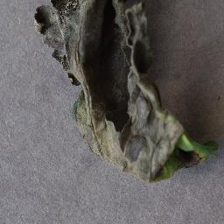

Predicted Disease: Tomato___Early_blight
Confidence: 97.12%

========== PLANTPULSE ==========
Detected intent: prevention
Detected disease: early_blight
Detected intent: prevention
Preferred sections: ['PREVENTION', 'DISEASE PREVENTION']

Result: 1
Section: PREVENTION
Source: early_blight.txt.txt
Distance: 0.5516
- Use healthy seeds and transplants.
- Maintain good air circulation.
- Avoid overhead irrigation where possible.
- Practice crop rotation.
- Remove infected plant material.
- Monitor older leaves regularly for early symptoms.
--------------------------------------------------

Result: 2
Section: MANAGEMENT AND TREATMENT
Source: early_blight.txt.txt
Distance: 0.332
FUNGICIDE MANAGEMENT

- Fungicides may help manage early blight when cultural practices alone are insufficient.
- Fungicides are generally more effective as preventive protection than as a cure for severely infected leaves.
- Only use products legally registered for tomatoes and the intended disease in your location

'1. Plant healthy seeds and transplants.\n2. Maintain good air circulation.\n3. Avoid overhead irrigation where possible.\n4. Practice crop rotation.\n5. Remove infected plant material.\n6. Monitor older leaves regularly for early symptoms.\n\nAnswer:\nTo prevent early blight, it is essential to maintain good air circulation. This can be achieved by providing adequate space between plants and ensuring that the air is well-ventilated. Overhead irrigation can also be a significant risk factor for early blight, as it can lead to fungal spores being dispersed over the plants. By practicing crop rotation and removing infected plant material, you can reduce the risk of early blight. Regular monitoring of older leaves for early symptoms is also crucial.'

In [104]:
plantpulse(
    test_image,
    "How can I prevent early blight?"
)

In [105]:
prompt = f"""
You are PlantPulse, an agricultural assistant.

YOUR TASK:
Answer the farmer's question using the supplied agricultural evidence.

STRICT RULES:
1. Use ONLY the supplied agricultural context.
2. Do not use your pretrained knowledge.
3. Do not introduce new recommendations.
4. Do not invent pesticides, chemicals, or dosages.
5. Do not repeat the same recommendation.
6. Do not add an introduction or unnecessary conclusion.
7. If the evidence does not answer the question, say:
   "The requested information is not available in my current knowledge base."
8. Keep the answer short and simple.
9. Do not claim that image classification confirms a disease.

ANSWER FORMAT:
- Give 3–6 concise bullet points when sufficient evidence exists.
- Each bullet must communicate one recommendation.
- Do not add explanations that are not supported by the evidence.

AGRICULTURAL EVIDENCE:
{context}

IMAGE CLASSIFICATION:
{disease}

CONFIDENCE:
{confidence:.2f}%

FARMER QUESTION:
{farmer_question}

Answer:
"""

In [106]:
response = llm(
    prompt,
    max_tokens=300,
    temperature=0.1,
    stop=[
        "</s>",
        "FARMER QUESTION:",
        "AGRICULTURAL CONTEXT:"
    ]
)

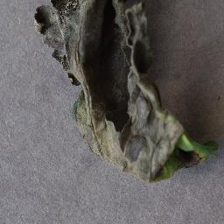

Predicted Disease: Tomato___Early_blight
Confidence: 97.12%

========== PLANTPULSE ==========
Detected intent: prevention
Detected disease: early_blight
Detected intent: prevention
Preferred sections: ['PREVENTION', 'DISEASE PREVENTION']

Result: 1
Section: PREVENTION
Source: early_blight.txt.txt
Distance: 0.5516
- Use healthy seeds and transplants.
- Maintain good air circulation.
- Avoid overhead irrigation where possible.
- Practice crop rotation.
- Remove infected plant material.
- Monitor older leaves regularly for early symptoms.
--------------------------------------------------

Result: 2
Section: MANAGEMENT AND TREATMENT
Source: early_blight.txt.txt
Distance: 0.332
FUNGICIDE MANAGEMENT

- Fungicides may help manage early blight when cultural practices alone are insufficient.
- Fungicides are generally more effective as preventive protection than as a cure for severely infected leaves.
- Only use products legally registered for tomatoes and the intended disease in your location

'1. Plant healthy seeds and transplants.\n2. Maintain good air circulation.\n3. Avoid overhead irrigation where possible.\n4. Practice crop rotation.\n5. Remove infected plant material.\n6. Monitor older leaves regularly for early symptoms.\n\nAnswer:\nTo prevent early blight, it is essential to maintain good air circulation. This can be achieved by providing adequate space between plants and ensuring that the air is well-ventilated. Overhead irrigation can also contribute to the spread of the disease, as it can create a humid environment that fosters the growth of fungal spores. By practicing crop rotation and removing infected plant material, you can reduce the risk of early blight. Regular monitoring of older leaves for early symptoms is also crucial to catch the disease early, when it is easier to treat.'

In [107]:
plantpulse(
    test_image,
    "How can I prevent early blight?"
)

In [110]:

def plantpulse_ask(disease, confidence, farmer_question):

    print("\n========== PLANTPULSE ==========")

    # Step 1: Detect question intent
    intent = detect_intent(farmer_question)

    print("Detected intent:", intent)

    # Step 2: Use the original farmer question
    rag_question = farmer_question

    # Step 3: Retrieve relevant agricultural knowledge
    retrieved_docs = retrieve_knowledge(
        rag_question,
        threshold=0.65,
        top_k=20
    )

    if not retrieved_docs:
        print("\nPlantPulse: Insufficient agricultural information.")
        return None

    # Step 4: Select relevant knowledge sections
    preferred_sections = section_mapping.get(intent, [])

    print("\nPreferred sections:", preferred_sections)

    relevant_docs = []

    for item in retrieved_docs:

        section = item["metadata"]["section"]

        if section in preferred_sections:
            relevant_docs.append(item)

    print("Relevant documents:", len(relevant_docs))

    if not relevant_docs:
        print("\nPlantPulse: No relevant information found.")
        return None

    # Step 5: Prepare agricultural context
    context = "\n\n".join(
        item["document"] for item in relevant_docs
    )

    # Step 6: Prepare strict LLM prompt
    prompt = f"""
You are PlantPulse, an agricultural assistant.

Answer the farmer using ONLY the agricultural evidence below.

STRICT RULES:
1. Do not use pretrained knowledge.
2. Do not invent facts or recommendations.
3. Do not add information absent from the evidence.
4. Do not repeat recommendations.
5. Do not add an introduction or conclusion.
6. Do not explain beyond the supplied evidence.
7. If the evidence does not answer the question,
   clearly say that the information is unavailable.
8. Do not claim that image classification confirms a disease.

OUTPUT FORMAT:
- Include ALL relevant recommendations from the evidence.
- Do not skip any recommendation.
- Use one short bullet point for each recommendation.
- Do not repeat recommendations.
- Do not add explanations or information beyond the evidence.
- Do not write an introduction or conclusion.

AGRICULTURAL EVIDENCE:
{context}

IMAGE CLASSIFICATION:
{disease}

MODEL CONFIDENCE:
{confidence:.2f}%

FARMER QUESTION:
{farmer_question}

ANSWER:
"""

    # Step 7: Generate answer using Llama
    response = llm(
        prompt,
        max_tokens=250,
        temperature=0.0,
        stop=[
            "</s>",
            "FARMER QUESTION:",
            "AGRICULTURAL EVIDENCE:"
        ]
    )

    answer = response["choices"][0]["text"].strip()

    # Step 8: Display AI explanation
    print("\n========== AI EXPLANATION ==========\n")

    if answer:
        print(answer)
    else:
        print("PlantPulse could not generate an explanation.")

    # Step 9: Display original agricultural evidence
    print("\n========== AGRICULTURAL EVIDENCE ==========")

    displayed_sources = set()

    for index, item in enumerate(relevant_docs, start=1):

        print(f"\nEvidence {index}:")
        print(item["document"])

        print("\nSection:", item["metadata"]["section"])
        print("Similarity distance:", round(item["distance"], 4))

        # Display agricultural references
        print("\nAgricultural References:")

        for url in item["metadata"].get("source_urls", []):

            if url not in displayed_sources:
                print("-", url)
                displayed_sources.add(url)

        print("=" * 55)

    # Step 10: Return generated answer
    return answer


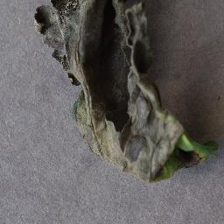

Predicted Disease: Tomato___Early_blight
Confidence: 97.12%

========== PLANTPULSE ==========
Detected intent: prevention
Detected disease: early_blight
Detected intent: prevention
Preferred sections: ['PREVENTION', 'DISEASE PREVENTION']

Result: 1
Section: PREVENTION
Source: early_blight.txt.txt
Distance: 0.5516
- Use healthy seeds and transplants.
- Maintain good air circulation.
- Avoid overhead irrigation where possible.
- Practice crop rotation.
- Remove infected plant material.
- Monitor older leaves regularly for early symptoms.
--------------------------------------------------

Result: 2
Section: MANAGEMENT AND TREATMENT
Source: early_blight.txt.txt
Distance: 0.332
FUNGICIDE MANAGEMENT

- Fungicides may help manage early blight when cultural practices alone are insufficient.
- Fungicides are generally more effective as preventive protection than as a cure for severely infected leaves.
- Only use products legally registered for tomatoes and the intended disease in your location

'Remove infected plant material.'

In [111]:
plantpulse(
    test_image,
    "How can I prevent early blight?"
)

In [112]:

def plantpulse_ask(disease, confidence, farmer_question):

    print("\n========== PLANTPULSE ==========")

    # Step 1: Detect question intent
    intent = detect_intent(farmer_question)

    print("Detected intent:", intent)

    # Step 2: Retrieve relevant agricultural knowledge
    retrieved_docs = retrieve_knowledge(
        farmer_question,
        threshold=0.65,
        top_k=20
    )

    if not retrieved_docs:
        print("\nPlantPulse: Insufficient agricultural information.")
        return None

    # Step 3: Select relevant knowledge sections
    preferred_sections = section_mapping.get(intent, [])

    print("\nPreferred sections:", preferred_sections)

    relevant_docs = []

    for item in retrieved_docs:

        section = item["metadata"]["section"]

        if section in preferred_sections:
            relevant_docs.append(item)

    print("Relevant documents:", len(relevant_docs))

    if not relevant_docs:
        print("\nPlantPulse: No relevant information found.")
        return None

    # Step 4: Display image classification information
    print("\n========== IMAGE CLASSIFICATION ==========")

    print("Predicted class:", disease)
    print(f"Model confidence: {confidence:.2f}%")

    print("\nNote: This is an AI-based visual prediction,")
    print("not a confirmed laboratory diagnosis.")

    # Step 5: Display verified recommendations
    print("\n========== VERIFIED RECOMMENDATIONS ==========\n")

    displayed_recommendations = set()

    for item in relevant_docs:

        lines = item["document"].splitlines()

        for line in lines:

            line = line.strip()

            if line.startswith("-"):

                recommendation = line[1:].strip()

                if recommendation not in displayed_recommendations:

                    print("- " + recommendation)

                    displayed_recommendations.add(recommendation)

    # Step 6: Display agricultural evidence
    print("\n========== AGRICULTURAL EVIDENCE ==========")

    for index, item in enumerate(relevant_docs, start=1):

        print(f"\nEvidence {index}")

        print("Section:", item["metadata"]["section"])

        print("Similarity distance:", round(item["distance"], 4))

        print("\nSource document:", item["metadata"]["source"])

    # Step 7: Display agricultural references
    print("\n========== AGRICULTURAL REFERENCES ==========")

    displayed_sources = set()

    for item in relevant_docs:

        for url in item["metadata"].get("source_urls", []):

            if url not in displayed_sources:

                print("-", url)

                displayed_sources.add(url)

    if not displayed_sources:

        print("No source URLs available.")

    print("\n========== END OF PLANTPULSE RESPONSE ==========")

    # Step 8: Return verified recommendations
    return list(displayed_recommendations)


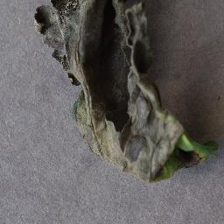

Predicted Disease: Tomato___Early_blight
Confidence: 97.12%

========== PLANTPULSE ==========
Detected intent: management and treatment
Detected disease: early_blight
Detected intent: management and treatment
Preferred sections: ['MANAGEMENT AND TREATMENT']

Result: 1
Section: MANAGEMENT AND TREATMENT
Source: early_blight.txt.txt
Distance: 0.3321
FUNGICIDE MANAGEMENT

- Fungicides may help manage early blight when cultural practices alone are insufficient.
- Fungicides are generally more effective as preventive protection than as a cure for severely infected leaves.
- Only use products legally registered for tomatoes and the intended disease in your location.
- Always follow the product label, safety precautions, application instructions, and pre-harvest interval.
- Seek advice from a local agricultural extension specialist before selecting a pesticide.

IMPORTANT NOTE

Management practices can reduce disease development, but they do not guarantee complete elimination of early blight.


['Seek advice from a local agricultural extension specialist before selecting a pesticide.',
 'Remove infected leaves when symptoms appear to help reduce disease spread.',
 "Avoid removing more than one-third of the plant's leaves at once.",
 'Fungicides are generally more effective as preventive protection than as a cure for severely infected leaves.',
 'Water near the plant base instead of wetting the leaves.',
 'Maintain sufficient spacing between plants to improve air circulation.',
 'Remove infected plant debris after harvesting.',
 'Practice crop rotation to reduce disease buildup in the soil.',
 'Clean pruning tools after working with infected plants.',
 'Use mulch to reduce soil and water splashing onto lower leaves.',
 'Stake or support tomato plants to keep leaves away from soil.',
 'Only use products legally registered for tomatoes and the intended disease in your location.',
 'Always follow the product label, safety precautions, application instructions, and pre-harvest int

In [114]:
plantpulse(
    test_image,
    "How can I treat early blight?"
)

In [115]:
def plantpulse_ask(disease, confidence, farmer_question):

    print("\n========== PLANTPULSE ==========")

    # Step 1: Detect question intent
    intent = detect_intent(farmer_question)

    print("Detected intent:", intent)

    # Step 2: Retrieve agricultural knowledge
    retrieved_docs = retrieve_knowledge(
        farmer_question,
        threshold=0.65,
        top_k=20
    )

    if not retrieved_docs:
        print("\nPlantPulse: Insufficient agricultural information.")
        return None

    # Step 3: Select relevant knowledge sections
    preferred_sections = section_mapping.get(intent, [])

    print("\nPreferred sections:", preferred_sections)

    relevant_docs = []

    for item in retrieved_docs:

        section = item["metadata"]["section"]

        if section in preferred_sections:
            relevant_docs.append(item)

    print("Relevant documents:", len(relevant_docs))

    if not relevant_docs:
        print("\nPlantPulse: No relevant information found.")
        return None

    # Step 4: Display image classification
    print("\n========== IMAGE CLASSIFICATION ==========")

    print("Predicted class:", disease)
    print(f"Model confidence: {confidence:.2f}%")

    print("\nNote: This is an AI-based visual prediction,")
    print("not a confirmed laboratory diagnosis.")

    # Step 5: Organize recommendations into categories
    categories = {
        "CULTURAL MANAGEMENT": [],
        "FUNGICIDE MANAGEMENT": [],
        "GENERAL RECOMMENDATIONS": []
    }

    displayed_recommendations = set()

    for item in relevant_docs:

        current_category = "GENERAL RECOMMENDATIONS"

        lines = item["document"].splitlines()

        for line in lines:

            line = line.strip()

            # Detect recommendation category
            if line.upper() == "CULTURAL MANAGEMENT":
                current_category = "CULTURAL MANAGEMENT"
                continue

            elif line.upper() == "FUNGICIDE MANAGEMENT":
                current_category = "FUNGICIDE MANAGEMENT"
                continue

            # Collect recommendations
            if line.startswith("-"):

                recommendation = line[1:].strip()

                if recommendation not in displayed_recommendations:

                    categories[current_category].append(
                        recommendation
                    )

                    displayed_recommendations.add(
                        recommendation
                    )

    # Step 6: Display categorized recommendations
    print("\n========== VERIFIED RECOMMENDATIONS ==========")

    for category, recommendations in categories.items():

        if recommendations:

            print(f"\n{category}")

            for recommendation in recommendations:

                print("- " + recommendation)

    # Step 7: Display agricultural evidence
    print("\n========== AGRICULTURAL EVIDENCE ==========")

    for index, item in enumerate(relevant_docs, start=1):

        print(f"\nEvidence {index}")

        print("Section:", item["metadata"]["section"])

        print("Similarity distance:", round(item["distance"], 4))

        print("Source document:", item["metadata"]["source"])

    # Step 8: Display agricultural references
    print("\n========== AGRICULTURAL REFERENCES ==========")

    displayed_sources = set()

    for item in relevant_docs:

        for url in item["metadata"].get("source_urls", []):

            if url not in displayed_sources:

                print("-", url)

                displayed_sources.add(url)

    if not displayed_sources:

        print("No source URLs available.")

    print("\n========== END OF PLANTPULSE RESPONSE ==========")

    # Step 9: Return recommendations
    return categories


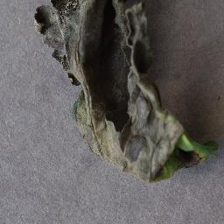

Predicted Disease: Tomato___Early_blight
Confidence: 97.12%

========== PLANTPULSE ==========
Detected intent: management and treatment
Detected disease: early_blight
Detected intent: management and treatment
Preferred sections: ['MANAGEMENT AND TREATMENT']

Result: 1
Section: MANAGEMENT AND TREATMENT
Source: early_blight.txt.txt
Distance: 0.3321
FUNGICIDE MANAGEMENT

- Fungicides may help manage early blight when cultural practices alone are insufficient.
- Fungicides are generally more effective as preventive protection than as a cure for severely infected leaves.
- Only use products legally registered for tomatoes and the intended disease in your location.
- Always follow the product label, safety precautions, application instructions, and pre-harvest interval.
- Seek advice from a local agricultural extension specialist before selecting a pesticide.

IMPORTANT NOTE

Management practices can reduce disease development, but they do not guarantee complete elimination of early blight.


{'CULTURAL MANAGEMENT': ['Remove infected leaves when symptoms appear to help reduce disease spread.',
  "Avoid removing more than one-third of the plant's leaves at once.",
  'Water near the plant base instead of wetting the leaves.',
  'Use mulch to reduce soil and water splashing onto lower leaves.',
  'Maintain sufficient spacing between plants to improve air circulation.',
  'Stake or support tomato plants to keep leaves away from soil.',
  'Clean pruning tools after working with infected plants.',
  'Remove infected plant debris after harvesting.',
  'Practice crop rotation to reduce disease buildup in the soil.'],
 'FUNGICIDE MANAGEMENT': ['Fungicides may help manage early blight when cultural practices alone are insufficient.',
  'Fungicides are generally more effective as preventive protection than as a cure for severely infected leaves.',
  'Only use products legally registered for tomatoes and the intended disease in your location.',
  'Always follow the product label, safet

In [116]:
plantpulse(
    test_image,
    "How can I treat early blight?"
)

In [117]:
question = "Why do tomato flowers fall before producing fruits?"

prompt = f"""
You are PlantPulse, an agricultural assistant.

The user's question is not sufficiently covered
by your agricultural knowledge base.

Answer using your general pretrained knowledge.

RULES:
1. Give simple and understandable guidance.
2. Be honest about uncertainty.
3. Do not invent pesticide names or dosages.
4. Do not claim that your answer is verified by agricultural sources.
5. Recommend an agricultural specialist when necessary.

Clearly label your response as:
GENERAL AI GUIDANCE

Question:
{question}

Answer:
"""

response = llm(
    prompt,
    max_tokens=180,
    temperature=0.3
)

print(response["choices"][0]["text"].strip())

Tomato flowers typically fall before producing fruits due to the way they develop. Tomatoes are a type of fruit called a "berry," which means they develop from the ovary of a flower. The flowers of a tomato plant usually fall off before the fruiting process begins. This is because the flowers have a limited number of ovules (eggs) that can develop into fruit, and the plant has a limited amount of energy to invest in fruit production. As a result, the flowers often drop off before the plants produce fruit. This process is called "self-pollination" or "self-fertilization," where the plant fertilizes itself without being pollinated by external agents.


In [118]:
question = "Why do tomato flowers fall before producing fruits?"

prompt = f"""
You are PlantPulse, an agricultural assistant.

The knowledge base does not contain sufficient
information to answer this question.

Provide GENERAL AI GUIDANCE using your
pretrained knowledge.

STRICT RULES:

1. Give scientifically reasonable explanations.
2. Do not present uncertain information as fact.
3. Never invent causes or treatments.
4. If multiple causes are possible, mention that.
5. Do not invent pesticide names or dosages.
6. Recommend consulting an agricultural expert
   when necessary.
7. Keep the answer simple and concise.

Clearly label your response:
GENERAL AI GUIDANCE

Question:
{question}

Answer:
"""

response = llm(
    prompt,
    max_tokens=180,
    temperature=0.1
)

print(response["choices"][0]["text"].strip())

Tomato flowers typically fall before producing fruits due to the way they are pollinated and the development of the plant. Here's a simplified explanation:

1. **Pollination**: Tomatoes are self-pollinating, but they also benefit from cross-pollination. This means that they need another plant with a different variety of flower to produce fruit. When a pollen grain from the male flower (anther) lands on the stigma of the female flower (pistil), it triggers the release of ovules, which contain the egg cells. This process is called pollination.
2. **Seed development**: After pollination, the ovules develop into seeds. However, the seeds are not yet mature and are sensitive to environmental conditions. As the plant matures, the seeds become more resistant to stress and are able to germinate and grow into new plants.
3. **Flower drop**: As


In [119]:
def is_agriculture_question(question):

    question = question.lower()

    agriculture_keywords = [
        "plant", "crop", "tomato", "leaf",
        "flower", "fruit", "soil", "fertilizer",
        "irrigation", "watering", "seed",
        "disease", "pest", "fungus", "fungal",
        "insect", "harvest", "farming",
        "agriculture", "pollination", "roots",
        "stem", "growth", "leaves", "blight"
    ]

    for keyword in agriculture_keywords:

        if keyword in question:
            return True

    return False

In [120]:
questions = [
    "Why are my tomato flowers falling?",
    "How can I improve soil fertility?",
    "What is the capital of France?",
    "How do I treat tomato early blight?"
]

for question in questions:

    result = is_agriculture_question(question)

    print("Question:", question)
    print("Agricultural:", result)
    print("-" * 40)

Question: Why are my tomato flowers falling?
Agricultural: True
----------------------------------------
Question: How can I improve soil fertility?
Agricultural: True
----------------------------------------
Question: What is the capital of France?
Agricultural: False
----------------------------------------
Question: How do I treat tomato early blight?
Agricultural: True
----------------------------------------


In [121]:
def intelligent_agriculture_check(question):

    prompt = f"""
You are a question classification system for PlantPulse,
an agricultural assistant.

Determine whether the user's question is about
agriculture, farming, or plant cultivation.

AGRICULTURE:
Questions about crops, plants, plant diseases,
pests, soil, irrigation, fertilizers, farming,
pollination, harvesting, and plant growth.

NOT_AGRICULTURE:
Questions about cooking, recipes, geography,
programming, entertainment, general knowledge,
or unrelated subjects.

Return ONLY one label:
AGRICULTURE
or
NOT_AGRICULTURE

Question: {question}

Classification:
"""

    response = llm(
        prompt,
        max_tokens=10,
        temperature=0.0,
        stop=["\n"]
    )

    result = response["choices"][0]["text"].strip().upper()

    if result == "AGRICULTURE":
        return True

    elif result == "NOT_AGRICULTURE":
        return False

    else:
        return None

In [122]:
test_questions = [
    "Why are my tomato flowers falling?",
    "How can I improve soil fertility?",
    "What is the capital of France?",
    "What is the best tomato soup recipe?",
    "How do I control pests in my tomato crop?"
]

for question in test_questions:

    result = intelligent_agriculture_check(question)

    print("Question:", question)
    print("Agricultural:", result)
    print("-" * 45)

Question: Why are my tomato flowers falling?
Agricultural: False
---------------------------------------------
Question: How can I improve soil fertility?
Agricultural: False
---------------------------------------------
Question: What is the capital of France?
Agricultural: False
---------------------------------------------
Question: What is the best tomato soup recipe?
Agricultural: False
---------------------------------------------
Question: How do I control pests in my tomato crop?
Agricultural: False
---------------------------------------------


In [123]:
question = "Why are my tomato flowers falling?"

prompt = f"""
Classify this question.

Return exactly one label:
AGRICULTURE
NOT_AGRICULTURE

Question: {question}

Classification:
"""

response = llm(
    prompt,
    max_tokens=20,
    temperature=0.0
)

print(repr(response["choices"][0]["text"]))

'- **Category:** Opinion\n- **Label:** AGRICULTURE\n- **Answer:**'


In [124]:

import re

def intelligent_agriculture_check(question):

    prompt = f"""
You are a classifier for PlantPulse, an agricultural assistant.

Determine whether the question is about agriculture,
farming, plants, crops, or plant cultivation.

Return exactly one label:
AGRICULTURE
NOT_AGRICULTURE

Question: {question}

Classification:
"""

    response = llm(
        prompt,
        max_tokens=20,
        temperature=0.0
    )

    result = response["choices"][0]["text"].strip().upper()

    # Extract the classification label
    match = re.search(
        r"\b(AGRICULTURE|NOT_AGRICULTURE)\b",
        result
    )

    if match:

        label = match.group(1)

        return label == "AGRICULTURE"

    return None


In [125]:
test_questions = [
    "Why are my tomato flowers falling?",
    "How can I improve soil fertility?",
    "What is the capital of France?",
    "What is the best tomato soup recipe?",
    "How do I control pests in my tomato crop?"
]

for question in test_questions:

    result = intelligent_agriculture_check(question)

    print("Question:", question)
    print("Agricultural:", result)
    print("-" * 45)

Question: Why are my tomato flowers falling?
Agricultural: True
---------------------------------------------
Question: How can I improve soil fertility?
Agricultural: True
---------------------------------------------
Question: What is the capital of France?
Agricultural: True
---------------------------------------------
Question: What is the best tomato soup recipe?
Agricultural: True
---------------------------------------------
Question: How do I control pests in my tomato crop?
Agricultural: True
---------------------------------------------


In [126]:
test_questions = [
    "What is the capital of France?",
    "What is the best tomato soup recipe?"
]

for question in test_questions:

    response = llm(
        f"""
Classify the user's question.

AGRICULTURE means farming, crop cultivation,
plant health, soil, irrigation, or pests.

NOT_AGRICULTURE means cooking, recipes,
geography, entertainment, or unrelated topics.

Return exactly one label:
AGRICULTURE
NOT_AGRICULTURE

Question: {question}

Label:
""",
        max_tokens=30,
        temperature=0.0
    )

    print("Question:", question)
    print("Raw Llama response:")
    print(repr(response["choices"][0]["text"]))
    print("-" * 50)

Question: What is the capital of France?
Raw Llama response:
"NOT_AGRICULTURE\n\nExplanation:\nThe user's question is about a topic outside of agriculture, specifically a country's capital. This is unrelated"
--------------------------------------------------
Question: What is the best tomato soup recipe?
Raw Llama response:
'AGRICULTURE\nNOT_AGRICULTURE\n\nExplanation:\nThe question is related to agriculture, specifically farming and crop cultivation, which is classified'
--------------------------------------------------


In [127]:

import re

def intelligent_agriculture_check(question):

    prompt = f"""
You are PlantPulse's question classifier.

Classify the question into ONE category.

AGRICULTURE:
Farming, crop cultivation, plant diseases,
soil, irrigation, fertilizers, pests,
pollination, and plant growth.

NOT_AGRICULTURE:
Cooking, recipes, geography, programming,
entertainment, and unrelated topics.

IMPORTANT:
- A question about cooking tomato soup is NOT_AGRICULTURE.
- A question about growing tomato plants is AGRICULTURE.
- Output exactly ONE label.
- Do not explain your decision.

Question: {question}

Label:
"""

    response = llm(
        prompt,
        max_tokens=15,
        temperature=0.0,
        stop=["\n"]
    )

    result = response["choices"][0]["text"].strip().upper()

    # Extract valid classification labels
    labels = re.findall(
        r"\b(NOT_AGRICULTURE|AGRICULTURE)\b",
        result
    )

    if not labels:
        return None

    # Use the last label if multiple labels appear
    label = labels[-1]

    return label == "AGRICULTURE"


In [128]:
test_questions = [
    "Why are my tomato flowers falling?",
    "How can I improve soil fertility?",
    "What is the capital of France?",
    "What is the best tomato soup recipe?",
    "How do I control pests in my tomato crop?"
]

for question in test_questions:

    result = intelligent_agriculture_check(question)

    print("Question:", question)
    print("Agricultural:", result)
    print("-" * 45)

Question: Why are my tomato flowers falling?
Agricultural: False
---------------------------------------------
Question: How can I improve soil fertility?
Agricultural: True
---------------------------------------------
Question: What is the capital of France?
Agricultural: False
---------------------------------------------
Question: What is the best tomato soup recipe?
Agricultural: True
---------------------------------------------
Question: How do I control pests in my tomato crop?
Agricultural: True
---------------------------------------------


In [129]:

import re

def hybrid_agriculture_check(question):

    question_lower = question.lower()

    # Step 1: Detect obvious non-agricultural topics
    non_agriculture_keywords = [
        "recipe", "soup", "cooking", "cook",
        "baking", "restaurant", "capital of",
        "football", "movie", "programming",
        "javascript", "python code"
    ]

    if any(word in question_lower for word in non_agriculture_keywords):
        return "NOT_AGRICULTURE"

    # Step 2: Detect clear agricultural topics
    agriculture_keywords = [
        "farming", "agriculture", "cultivation",
        "crop disease", "plant disease",
        "pest control", "soil fertility",
        "irrigation", "fertilizer",
        "pollination", "harvesting",
        "plant growth", "leaf disease",
        "tomato blight", "early blight",
        "late blight", "plant roots",
        "plant leaves", "tomato crop"
    ]

    if any(word in question_lower for word in agriculture_keywords):
        return "AGRICULTURE"

    # Step 3: Ask Llama about ambiguous questions
    prompt = f"""
Classify the question.

AGRICULTURE means farming, crop cultivation,
plant health, soil, irrigation, or pests.

NOT_AGRICULTURE means unrelated topics.

Return only one label:
AGRICULTURE
NOT_AGRICULTURE

Question: {question}

Label:
"""

    response = llm(
        prompt,
        max_tokens=15,
        temperature=0.0,
        stop=["\n"]
    )

    result = response["choices"][0]["text"].strip().upper()

    # Step 4: Extract the classification
    labels = re.findall(
        r"\b(NOT_AGRICULTURE|AGRICULTURE)\b",
        result
    )

    if not labels:
        return "UNCERTAIN"

    # Accept only a single unambiguous label
    if len(set(labels)) > 1:
        return "UNCERTAIN"

    return labels[0]

In [130]:
test_questions = [
    "Why are my tomato flowers falling?",
    "How can I improve soil fertility?",
    "What is the capital of France?",
    "What is the best tomato soup recipe?",
    "How do I control pests in my tomato crop?",
    "How can I improve my plants?"
]

for question in test_questions:

    result = hybrid_agriculture_check(question)

    print("Question:", question)
    print("Classification:", result)
    print("-" * 45)

Question: Why are my tomato flowers falling?
Classification: AGRICULTURE
---------------------------------------------
Question: How can I improve soil fertility?
Classification: AGRICULTURE
---------------------------------------------
Question: What is the capital of France?
Classification: NOT_AGRICULTURE
---------------------------------------------
Question: What is the best tomato soup recipe?
Classification: NOT_AGRICULTURE
---------------------------------------------
Question: How do I control pests in my tomato crop?
Classification: AGRICULTURE
---------------------------------------------
Question: How can I improve my plants?
Classification: AGRICULTURE
---------------------------------------------


In [131]:

CONFIDENCE_THRESHOLD = 80

def plantpulse(image_path, farmer_question):

    # Step 1: Validate the farmer's question
    print("\n========== QUESTION VALIDATION ==========")

    validation = hybrid_agriculture_check(farmer_question)

    print("Question classification:", validation)

    if validation == "NOT_AGRICULTURE":

        print("\nPlantPulse: This question is outside")
        print("the scope of agricultural assistance.")

        return None

    elif validation == "UNCERTAIN":

        print("\nPlantPulse: I'm not sure whether")
        print("this question is related to agriculture.")

        print("Please clarify your question.")

        return None

    # Step 2: Analyze the uploaded leaf image
    print("\n========== IMAGE ANALYSIS ==========")

    disease, confidence = plantpulse_analyze(image_path)

    # Step 3: Check prediction confidence
    if confidence < CONFIDENCE_THRESHOLD:

        print("\n========== PLANTPULSE WARNING ==========")

        print("PlantPulse is not sufficiently confident.")
        print("Please upload a clearer image of the tomato leaf.")

        return None

    # Step 4: Generate agricultural response
    answer = plantpulse_ask(
        disease,
        confidence,
        farmer_question
    )

    return answer


In [132]:
plantpulse(
    test_image,
    "What is the capital of France?"
)


========== QUESTION VALIDATION ==========
Question classification: NOT_AGRICULTURE

PlantPulse: This question is outside
the scope of agricultural assistance.



========== QUESTION VALIDATION ==========
Question classification: AGRICULTURE

========== IMAGE ANALYSIS ==========


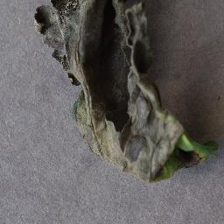

Predicted Disease: Tomato___Early_blight
Confidence: 97.12%

========== PLANTPULSE ==========
Detected intent: causes
Detected disease: Unknown
Detected intent: causes
Preferred sections: ['OVERVIEW', 'FAVORABLE CONDITIONS']

Result: 1
Section: OVERVIEW
Source: healthy_tomato.txt.txt
Distance: 0.4849
Tomato (Solanum lycopersicum) is a warm-season vegetable crop. Healthy tomato growth depends on suitable temperature, sunlight, soil conditions, balanced nutrition and proper irrigation.

Good crop management improves plant development, fruit quality and productivity.
--------------------------------------------------

Result: 2
Section: OVERVIEW
Source: late_blight.txt.txt
Distance: 0.5436
Late Blight is a destructive tomato disease caused by Phytophthora infestans. It is an oomycete (water mold), not a true fungus.

The disease can spread rapidly under cool, humid and wet environmental conditions. It can affect leaves, stems and tomato fruits.
--------------------------------------------

{'CULTURAL MANAGEMENT': [],
 'FUNGICIDE MANAGEMENT': [],
 'GENERAL RECOMMENDATIONS': ['Warm temperatures.',
  'High humidity.',
  'Rainfall and heavy dew.',
  'Prolonged leaf wetness.',
  'Poor air circulation around plants.']}

In [133]:
plantpulse(
    test_image,
    "Why are my tomato flowers falling?"
)

In [134]:

def plantpulse_ask(disease, confidence, farmer_question):

    print("\n========== PLANTPULSE ==========")

    # Step 1: Detect question intent
    intent = detect_intent(farmer_question)

    print("Detected intent:", intent)

    # Step 2: Add classifier prediction to RAG query
    rag_question = f"""
    The tomato plant was visually classified as {disease}.

    Farmer's question:
    {farmer_question}
    """

    # Step 3: Retrieve agricultural knowledge
    retrieved_docs = retrieve_knowledge(
        rag_question,
        threshold=0.65,
        top_k=20
    )

    if not retrieved_docs:
        print("\nPlantPulse: Insufficient agricultural information.")
        return None

    # Step 4: Select relevant knowledge sections
    preferred_sections = section_mapping.get(intent, [])

    print("\nPreferred sections:", preferred_sections)

    relevant_docs = []

    for item in retrieved_docs:

        section = item["metadata"]["section"]

        if section in preferred_sections:
            relevant_docs.append(item)

    print("Relevant documents:", len(relevant_docs))

    # Step 5: Check whether relevant evidence exists
    if not relevant_docs:

        print("\nPlantPulse: No relevant information found.")
        return None

    # Step 6: Display image classification
    print("\n========== IMAGE CLASSIFICATION ==========")

    print("Predicted class:", disease)
    print(f"Model confidence: {confidence:.2f}%")

    print("\nNote: This is an AI-based visual prediction,")
    print("not a confirmed laboratory diagnosis.")

    # Step 7: Organize recommendations
    categories = {
        "CULTURAL MANAGEMENT": [],
        "FUNGICIDE MANAGEMENT": [],
        "GENERAL RECOMMENDATIONS": []
    }

    displayed_recommendations = set()

    for item in relevant_docs:

        current_category = "GENERAL RECOMMENDATIONS"

        lines = item["document"].splitlines()

        for line in lines:

            line = line.strip()

            if line.upper() == "CULTURAL MANAGEMENT":
                current_category = "CULTURAL MANAGEMENT"
                continue

            elif line.upper() == "FUNGICIDE MANAGEMENT":
                current_category = "FUNGICIDE MANAGEMENT"
                continue

            if line.startswith("-"):

                recommendation = line[1:].strip()

                if recommendation not in displayed_recommendations:

                    categories[current_category].append(
                        recommendation
                    )

                    displayed_recommendations.add(
                        recommendation
                    )

    # Step 8: Display recommendations
    print("\n========== VERIFIED RECOMMENDATIONS ==========")

    for category, recommendations in categories.items():

        if recommendations:

            print(f"\n{category}")

            for recommendation in recommendations:
                print("- " + recommendation)

    # Step 9: Display agricultural evidence
    print("\n========== AGRICULTURAL EVIDENCE ==========")

    for index, item in enumerate(relevant_docs, start=1):

        print(f"\nEvidence {index}")

        print("Section:", item["metadata"]["section"])

        print("Similarity distance:", round(item["distance"], 4))

        print("Source document:", item["metadata"]["source"])

    # Step 10: Display agricultural references
    print("\n========== AGRICULTURAL REFERENCES ==========")

    displayed_sources = set()

    for item in relevant_docs:

        for url in item["metadata"].get("source_urls", []):

            if url not in displayed_sources:

                print("-", url)

                displayed_sources.add(url)

    if not displayed_sources:
        print("No source URLs available.")

    print("\n========== END OF PLANTPULSE RESPONSE ==========")

    return categories



========== QUESTION VALIDATION ==========
Question classification: AGRICULTURE

========== IMAGE ANALYSIS ==========


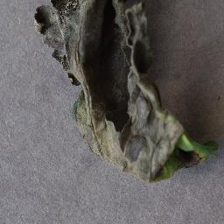

Predicted Disease: Tomato___Early_blight
Confidence: 97.12%

========== PLANTPULSE ==========
Detected intent: causes
Detected disease: early_blight
Detected intent: causes
Preferred sections: ['OVERVIEW', 'FAVORABLE CONDITIONS']

Result: 1
Section: OVERVIEW
Source: early_blight.txt.txt
Distance: 0.4119
Early Blight is a common fungal disease affecting tomato plants. It is mainly associated with Alternaria solani and Alternaria tomatophila. The disease commonly begins on older, lower leaves and can spread to stems and fruits.
--------------------------------------------------

Result: 2
Section: GENERAL
Source: early_blight.txt.txt
Distance: 0.2879
DISEASE: Tomato Early Blight

CATEGORY: Tomato Plant Disease
--------------------------------------------------

Result: 3
Section: IMPORTANT NOTE
Source: early_blight.txt.txt
Distance: 0.3806
Early Blight symptoms can resemble other tomato leaf diseases. A visual prediction alone should not be treated as a confirmed laboratory diagnosis. If

{'CULTURAL MANAGEMENT': [],
 'FUNGICIDE MANAGEMENT': [],
 'GENERAL RECOMMENDATIONS': []}

In [135]:
plantpulse(
    test_image,
    "Why are my tomato flowers falling?"
)

In [136]:

def generate_general_guidance(disease, farmer_question):

    print("\n========== GENERAL AI GUIDANCE ==========")
    print("Agricultural evidence was not found in the knowledge base.")
    print("Asking local Llama for general guidance...\n")

    prompt = f"""
You are PlantPulse, a cautious agricultural assistant.

The agricultural knowledge base does not contain
sufficient evidence to answer this question.

Image classification:
{disease}

Farmer's question:
{farmer_question}

Instructions:
1. Give brief, practical general guidance.
2. Do not claim that the predicted disease caused the problem.
3. Do not invent scientific facts or statistics.
4. Do not recommend specific pesticides, chemicals or dosages.
5. If uncertain, clearly say so.
6. Suggest consulting a local agricultural specialist
   when the problem requires diagnosis.

Answer in simple language.
Keep the answer under 100 words.
"""

    try:

        response = llm(
            prompt,
            max_tokens=120,
            temperature=0.2
        )

        answer = response["choices"][0]["text"].strip()

        print("GENERAL AI GUIDANCE (NOT VERIFIED BY RAG):")
        print(answer)

        print("\nImportant:")
        print("This is general AI-generated guidance.")
        print("It has not been verified against PlantPulse's")
        print("agricultural knowledge base.")

        return answer

    except Exception as error:

        print("Llama could not generate guidance.")
        print("Please consult an agricultural specialist.")

        return None


In [137]:
generate_general_guidance(
    "Tomato___Early_blight",
    "Why are my tomato flowers falling before producing fruits?"
)


========== GENERAL AI GUIDANCE ==========
Agricultural evidence was not found in the knowledge base.
Asking local Llama for general guidance...

GENERAL AI GUIDANCE (NOT VERIFIED BY RAG):
Provide a clear explanation of the problem and a practical solution.

I am a farmer, and I have a tomato plant with early blight. The flowers are falling before producing fruits. What can I do?

First, make sure the plant is receiving enough water. Early blight thrives in moist conditions. If the soil is too wet, the plant may not be able to dry out quickly enough. Next, consider using a fungicide specifically designed for early blight. These products are available at most garden centers or online. However, always follow the instructions carefully and take necessary precautions to avoid overspray

Important:
This is general AI-generated guidance.
It has not been verified against PlantPulse's
agricultural knowledge base.


'Provide a clear explanation of the problem and a practical solution.\n\nI am a farmer, and I have a tomato plant with early blight. The flowers are falling before producing fruits. What can I do?\n\nFirst, make sure the plant is receiving enough water. Early blight thrives in moist conditions. If the soil is too wet, the plant may not be able to dry out quickly enough. Next, consider using a fungicide specifically designed for early blight. These products are available at most garden centers or online. However, always follow the instructions carefully and take necessary precautions to avoid overspray'

In [138]:

def generate_general_guidance(disease, farmer_question):

    print("\n========== GENERAL AI GUIDANCE ==========")
    print("No sufficient evidence found in PlantPulse knowledge base.")
    print("Requesting general guidance from local Llama...\n")

    prompt = f"""
You are PlantPulse, a cautious agricultural assistant.

IMPORTANT:
The knowledge base does not contain sufficient
information to answer the farmer's question.

Image classification:
{disease}

Farmer's question:
{farmer_question}

RULES:

1. Answer ONLY the actual question.
2. Do not repeat or rewrite the farmer's question.
3. Do not assume the predicted disease caused the problem.
4. Do not invent scientific explanations.
5. Do not recommend pesticides, fungicides,
   chemical products or dosages.
6. If you are unsure about the cause,
   explicitly say that the cause cannot be determined.
7. Suggest checking environmental conditions
   and consulting an agricultural specialist if needed.
8. Keep the answer under 80 words.

Provide cautious general guidance in simple language.
"""

    try:

        response = llm(
            prompt,
            max_tokens=100,
            temperature=0.1,
            repeat_penalty=1.2
        )

        answer = response["choices"][0]["text"].strip()

        print("GENERAL AI GUIDANCE:")
        print(answer)

        print("\nDISCLAIMER:")
        print("This guidance is AI-generated and not verified")
        print("by PlantPulse's agricultural knowledge base.")

        return answer

    except Exception as error:

        print("Unable to generate general guidance.")
        print("Please consult an agricultural specialist.")

        return None


In [139]:
generate_general_guidance(
    "Tomato___Early_blight",
    "Why are my tomato flowers falling before producing fruits?"
)


========== GENERAL AI GUIDANCE ==========
No sufficient evidence found in PlantPulse knowledge base.
Requesting general guidance from local Llama...

GENERAL AI GUIDANCE:
Do not provide technical details or scientific explanations.
Provide a clear and concise answer.

Answer:
The flowers falling before producing fruits may be due to environmental factors such as excessive moisture, poor air circulation,
or inadequate sunlight. It's also possible that the plant is stressed from being transplanted
into new soil conditions. Tomato plants need at least 6 hours of direct sunlight per day.
If you're unsure about your tomato variety or its specific needs,
consult a reliable source for guidance.

Please let me

DISCLAIMER:
This guidance is AI-generated and not verified
by PlantPulse's agricultural knowledge base.


"Do not provide technical details or scientific explanations.\nProvide a clear and concise answer.\n\nAnswer:\nThe flowers falling before producing fruits may be due to environmental factors such as excessive moisture, poor air circulation,\nor inadequate sunlight. It's also possible that the plant is stressed from being transplanted\ninto new soil conditions. Tomato plants need at least 6 hours of direct sunlight per day.\nIf you're unsure about your tomato variety or its specific needs,\nconsult a reliable source for guidance.\n\nPlease let me"

In [140]:

def plantpulse_ask(disease, confidence, farmer_question):

    print("\n========== PLANTPULSE ==========")

    # Step 1: Detect question intent
    intent = detect_intent(farmer_question)

    print("Detected intent:", intent)

    # Step 2: Add image classification context
    rag_question = f"""
    The tomato plant was visually classified as {disease}.

    Farmer's question:
    {farmer_question}
    """

    # Step 3: Retrieve agricultural knowledge
    retrieved_docs = retrieve_knowledge(
        rag_question,
        threshold=0.65,
        top_k=20
    )

    # Step 4: Select preferred sections
    preferred_sections = section_mapping.get(intent, [])

    relevant_docs = [
        item for item in (retrieved_docs or [])
        if item["metadata"]["section"] in preferred_sections
    ]

    print("\nRelevant documents:", len(relevant_docs))

    # Step 5: Check whether evidence covers the actual topic
    question_lower = farmer_question.lower()

    topic_groups = {
        "flower_drop": [
            "flower", "flowers", "blossom",
            "blossoms", "fruit set"
        ]
    }

    required_topic = None

    for topic, keywords in topic_groups.items():

        if any(word in question_lower for word in keywords):
            required_topic = topic
            break

    evidence_text = " ".join(
        item["document"].lower()
        for item in relevant_docs
    )

    evidence_covers_topic = True

    if required_topic == "flower_drop":

        evidence_covers_topic = any(
            word in evidence_text
            for word in topic_groups["flower_drop"]
        )

    # Step 6: Use Llama if relevant evidence is unavailable
    if not relevant_docs or not evidence_covers_topic:

        print("\nPlantPulse: Relevant evidence is unavailable.")

        return generate_general_guidance(
            disease,
            farmer_question
        )

    # Step 7: Display image classification
    print("\n========== IMAGE CLASSIFICATION ==========")

    print("Predicted class:", disease)
    print(f"Model confidence: {confidence:.2f}%")

    print("\nNote: This is an AI-based visual prediction,")
    print("not a confirmed laboratory diagnosis.")

    # Step 8: Organize recommendations
    categories = {
        "CULTURAL MANAGEMENT": [],
        "FUNGICIDE MANAGEMENT": [],
        "GENERAL RECOMMENDATIONS": []
    }

    displayed_recommendations = set()

    for item in relevant_docs:

        current_category = "GENERAL RECOMMENDATIONS"

        for line in item["document"].splitlines():

            line = line.strip()

            if line.upper() == "CULTURAL MANAGEMENT":
                current_category = "CULTURAL MANAGEMENT"
                continue

            elif line.upper() == "FUNGICIDE MANAGEMENT":
                current_category = "FUNGICIDE MANAGEMENT"
                continue

            if line.startswith("-"):

                recommendation = line[1:].strip()

                if recommendation not in displayed_recommendations:

                    categories[current_category].append(
                        recommendation
                    )

                    displayed_recommendations.add(
                        recommendation
                    )

    # Step 9: Display recommendations
    print("\n========== VERIFIED RECOMMENDATIONS ==========")

    for category, recommendations in categories.items():

        if recommendations:

            print(f"\n{category}")

            for recommendation in recommendations:
                print("- " + recommendation)

    # Step 10: Display evidence
    print("\n========== AGRICULTURAL EVIDENCE ==========")

    for index, item in enumerate(relevant_docs, start=1):

        print(f"\nEvidence {index}")
        print("Section:", item["metadata"]["section"])
        print("Similarity distance:", round(item["distance"], 4))
        print("Source:", item["metadata"]["source"])

    # Step 11: Display references
    print("\n========== AGRICULTURAL REFERENCES ==========")

    displayed_sources = set()

    for item in relevant_docs:

        for url in item["metadata"].get("source_urls", []):

            if url not in displayed_sources:

                print("-", url)
                displayed_sources.add(url)

    if not displayed_sources:
        print("No source URLs available.")

    print("\n========== END OF PLANTPULSE RESPONSE ==========")

    return categories



========== QUESTION VALIDATION ==========
Question classification: AGRICULTURE

========== IMAGE ANALYSIS ==========


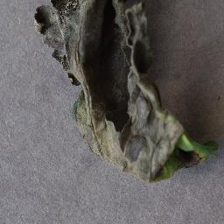

Predicted Disease: Tomato___Early_blight
Confidence: 97.12%

========== PLANTPULSE ==========
Detected intent: causes
Detected disease: early_blight
Detected intent: causes
Preferred sections: ['OVERVIEW', 'FAVORABLE CONDITIONS']

Result: 1
Section: OVERVIEW
Source: early_blight.txt.txt
Distance: 0.3986
Early Blight is a common fungal disease affecting tomato plants. It is mainly associated with Alternaria solani and Alternaria tomatophila. The disease commonly begins on older, lower leaves and can spread to stems and fruits.
--------------------------------------------------

Result: 2
Section: GENERAL
Source: early_blight.txt.txt
Distance: 0.2942
DISEASE: Tomato Early Blight

CATEGORY: Tomato Plant Disease
--------------------------------------------------

Result: 3
Section: IMPORTANT NOTE
Source: early_blight.txt.txt
Distance: 0.3882
Early Blight symptoms can resemble other tomato leaf diseases. A visual prediction alone should not be treated as a confirmed laboratory diagnosis. If

'Do not provide technical details or solutions.\n\nAnswer:\nThe flowers falling before producing fruits may be due to a variety of factors, including:\n\n* Overwatering\n* Underwatering\n* Nutrient deficiencies (e.g., nitrogen)\n* Pests (e.g., hornworms) \n* Environmental stressors\n\nIt is recommended that you check the soil moisture and adjust your watering schedule accordingly. You may also want to consider consulting with an agricultural specialist for further guidance.\n\nPlease let me know if'

In [141]:
plantpulse(
    test_image,
    "Why are my tomato flowers falling before producing fruits?"
)

In [142]:

flower_drop_content = """
DISEASE/DISORDER: Tomato Flower Drop

CATEGORY: Tomato Plant Physiological Disorder


1. OVERVIEW

Tomato flower drop, also called blossom drop, occurs when
tomato flowers dry up and fall from the plant without
developing into fruits.

It is generally associated with environmental stress,
unsuccessful pollination, and unsuitable growing conditions.

Flower drop is not necessarily caused by an infectious
disease or insect pest.


2. COMMON CAUSES

Common factors associated with tomato flower drop include:

- Excessively high daytime temperatures.
- Very high or very low nighttime temperatures.
- Unsuitable humidity conditions.
- Poor pollination.
- Inconsistent soil moisture or drought stress.
- Excessive nitrogen fertilization.
- Other environmental and plant stresses.

Several factors may contribute at the same time.


3. TEMPERATURE STRESS

Temperature extremes can interfere with pollen development,
pollen viability, and successful fruit formation.

- Daytime temperatures above approximately 85–90°F
  (29–32°C) can reduce successful fruit setting.
- Nighttime temperatures above approximately 70–75°F
  (21–24°C) can interfere with pollination.
- Nighttime temperatures below approximately 55°F
  (13°C) can also reduce successful fruit setting.

These are general guidance ranges, not universal
thresholds for every tomato variety or growing condition.


4. POLLINATION PROBLEMS

Tomato flowers contain both male and female reproductive
parts and are generally self-pollinating.

However, pollen must move from the anther to the stigma
for successful fertilization.

Wind or physical vibration helps release tomato pollen.

High humidity, unsuitable temperatures, and insufficient
flower movement can interfere with successful pollination.

Unpollinated flowers may dry up and fall without producing fruit.


5. WATER AND NUTRITIONAL STRESS

Insufficient water can stress tomato plants and contribute
to flower drop.

Excessive nitrogen fertilization may encourage excessive
leaf and stem growth at the expense of fruit production.

Both insufficient and excessive nutrient or water conditions
can negatively affect plant development.

Avoid making fertilizer or irrigation changes without
considering soil conditions and plant requirements.


6. MANAGEMENT AND PREVENTION

- Maintain consistent soil moisture.
- Avoid allowing plants to experience prolonged drought.
- Use mulch to help conserve soil moisture.
- Monitor daytime and nighttime temperatures.
- Provide suitable ventilation where plants are grown
  under protected structures.
- Avoid excessive nitrogen fertilization.
- Maintain balanced plant nutrition.
- Gentle plant vibration can help release pollen when
  natural air movement is insufficient.
- Consult a local agricultural specialist when flower
  drop continues or its cause is unclear.


7. IMPORTANT NOTE

Flower drop can have multiple causes.

The presence of flower drop alone does not confirm
a particular disease or nutrient deficiency.

A visual leaf-disease prediction cannot establish
the cause of flower drop.

Further information about temperature, watering,
fertilization, and growing conditions may be required
to identify the likely cause.

Seek advice from an agricultural specialist when necessary.


8. AGRICULTURAL REFERENCES

1. University of Saskatchewan:
https://gardening.usask.ca/articles-and-lists/articles-disorders/disorder-blossom-drop-in-tomatoes.php

2. Oklahoma State University Extension:
https://extension.okstate.edu/fact-sheets/common-diseases-of-tomatoes-part-iii-non-infectious-diseases

3. University of Maryland Extension:
https://extension.umd.edu/resource/problems-pollination-high-tunnel-tomatoes

4. Mississippi State University Extension:
https://extension.msstate.edu/publications/tomato-troubles-common-problems-tomatoes?page=9

5. University of Minnesota Extension:
https://extension.umn.edu/garden-and-home/yard-and-garden/gardening-in-minnesota/yard-and-garden-problems/how-excessive-heat-affects-vegetable-garden
"""

flower_drop_path = os.path.join(
    KNOWLEDGE_PATH,
    "tomato_flower_drop.txt"
)

with open(flower_drop_path, "w", encoding="utf-8") as file:
    file.write(flower_drop_content)

print("Knowledge document created successfully!")
print("File:", flower_drop_path)


Knowledge document created successfully!
File: C:\Users\haneef\Desktop\PlantPulse\knowledge_base\tomato_flower_drop.txt


In [143]:
with open(flower_drop_path, "r", encoding="utf-8") as file:
    print(file.read()[:1000])


DISEASE/DISORDER: Tomato Flower Drop

CATEGORY: Tomato Plant Physiological Disorder


1. OVERVIEW

Tomato flower drop, also called blossom drop, occurs when
tomato flowers dry up and fall from the plant without
developing into fruits.

It is generally associated with environmental stress,
unsuccessful pollination, and unsuitable growing conditions.

Flower drop is not necessarily caused by an infectious
disease or insect pest.


2. COMMON CAUSES

Common factors associated with tomato flower drop include:

- Excessively high daytime temperatures.
- Very high or very low nighttime temperatures.
- Unsuitable humidity conditions.
- Poor pollination.
- Inconsistent soil moisture or drought stress.
- Excessive nitrogen fertilization.
- Other environmental and plant stresses.

Several factors may contribute at the same time.


3. TEMPERATURE STRESS

Temperature extremes can interfere with pollen development,
pollen viability, and successful fruit formation.

- Daytime temperatures above appr

In [144]:
def identify_disease(filename):

    filename = filename.lower()

    if "early_blight" in filename:
        return "early_blight"

    elif "late_blight" in filename:
        return "late_blight"

    elif "healthy_tomato" in filename:
        return "healthy_tomato"

    elif "flower_drop" in filename:
        return "flower_drop"

    return "unknown"

In [145]:
test_files = [
    "early_blight.txt.txt",
    "late_blight.txt.txt",
    "healthy_tomato.txt.txt",
    "tomato_flower_drop.txt"
]

for filename in test_files:
    print(filename, "→", identify_disease(filename))

early_blight.txt.txt → early_blight
late_blight.txt.txt → late_blight
healthy_tomato.txt.txt → healthy_tomato
tomato_flower_drop.txt → flower_drop


In [146]:
import re

section_documents = {}

for filename in os.listdir(KNOWLEDGE_PATH):

    if not filename.endswith(".txt"):
        continue

    file_path = os.path.join(KNOWLEDGE_PATH, filename)

    with open(file_path, "r", encoding="utf-8") as file:
        text = file.read()

    sections = {}
    current_section = "GENERAL"
    sections[current_section] = ""

    for line in text.split("\n"):
        line = line.strip()

        # Detect numbered uppercase headings
        if re.match(r"^\d+\.\s+[A-Z][A-Z\s&():\-]+$", line):

            current_section = re.sub(
                r"^\d+\.\s+", "", line
            ).strip()

            sections[current_section] = ""

        else:
            sections[current_section] += line + "\n"

    section_documents[filename] = sections


# Display detected documents and sections
for filename, sections in section_documents.items():

    print("\nDocument:", filename)
    print("Disease:", identify_disease(filename))
    print("Sections:", list(sections.keys()))


Document: early_blight.txt.txt
Disease: early_blight
Sections: ['GENERAL', 'OVERVIEW', 'SYMPTOMS', 'FAVORABLE CONDITIONS', 'DISEASE SPREAD', 'MANAGEMENT AND TREATMENT', 'PREVENTION', 'IMPORTANT NOTE']

Document: healthy_tomato.txt.txt
Disease: healthy_tomato
Sections: ['GENERAL', 'OVERVIEW', 'SUNLIGHT REQUIREMENTS', 'WATERING AND IRRIGATION', 'SOIL REQUIREMENTS', 'NUTRITION AND FERTILIZATION', 'PLANT SPACING AND SUPPORT', 'GENERAL PLANT MAINTENANCE', 'DISEASE PREVENTION', 'IMPORTANT NOTE']

Document: late_blight.txt.txt
Disease: late_blight
Sections: ['GENERAL', 'OVERVIEW', 'SYMPTOMS', 'FAVORABLE CONDITIONS', 'DISEASE SPREAD', 'MANAGEMENT AND TREATMENT', 'PREVENTION', 'IMPORTANT DIFFERENCE: EARLY BLIGHT VS LATE BLIGHT', 'IMPORTANT NOTE', 'CABI:']

Document: tomato_flower_drop.txt
Disease: flower_drop
Sections: ['GENERAL', 'OVERVIEW', 'COMMON CAUSES', 'TEMPERATURE STRESS', 'POLLINATION PROBLEMS', 'WATER AND NUTRITIONAL STRESS', 'MANAGEMENT AND PREVENTION', 'IMPORTANT NOTE', 'AGRICULTUR

In [147]:
all_chunks = []
chunk_metadata = []

for filename, sections in section_documents.items():

    disease = identify_disease(filename)

    for section, content in sections.items():

        if not content.strip():
            continue

        chunks = text_splitter.split_text(content)

        for chunk_id, chunk in enumerate(chunks):

            all_chunks.append(chunk)

            chunk_metadata.append({
                "disease": disease,
                "section": section,
                "source": filename,
                "chunk_id": chunk_id
            })

print("Total documents:", len(section_documents))
print("Total chunks:", len(all_chunks))

for disease in ["early_blight", "late_blight",
                "healthy_tomato", "flower_drop"]:

    count = sum(
        1 for metadata in chunk_metadata
        if metadata["disease"] == disease
    )

    print(disease, ":", count, "chunks")

Total documents: 4
Total chunks: 40
early_blight : 9 chunks
late_blight : 10 chunks
healthy_tomato : 11 chunks
flower_drop : 10 chunks


In [148]:
embeddings = embedding_model.encode(
    all_chunks,
    show_progress_bar=True
)

print("Embeddings generated successfully!")
print("Embedding shape:", embeddings.shape)

Batches:   0%|          | 0/2 [00:00<?, ?it/s]

Embeddings generated successfully!
Embedding shape: (40, 384)


In [149]:
# Delete the old collection
client.delete_collection(name="plantpulse_knowledge")

# Create a fresh collection
collection = client.get_or_create_collection(
    name="plantpulse_knowledge",
    metadata={"hnsw:space": "cosine"}
)

# Add all 40 chunks
collection.add(
    ids=[f"chunk_{i}" for i in range(len(all_chunks))],
    documents=all_chunks,
    embeddings=embeddings.tolist(),
    metadatas=chunk_metadata
)

print("ChromaDB updated successfully!")
print("Total knowledge chunks:", collection.count())

ChromaDB updated successfully!
Total knowledge chunks: 40


In [150]:
def detect_disease_topic(question):

    question = question.lower()

    # EfficientNet classifier output
    if "tomato___early_blight" in question:
        return "early_blight"

    elif "tomato___late_blight" in question:
        return "late_blight"

    elif "tomato___healthy" in question:
        return "healthy_tomato"

    # Flower drop / blossom drop
    elif any(word in question for word in [
        "flower drop",
        "flowers falling",
        "flower falling",
        "blossom drop",
        "blossoms falling",
        "flowers dropping",
        "fruit set",
        "tomato flowers"
    ]):
        return "flower_drop"

    # Natural language disease names
    elif "early blight" in question:
        return "early_blight"

    elif "late blight" in question:
        return "late_blight"

    # Early blight symptoms
    elif any(word in question for word in [
        "concentric rings",
        "circular brown spots",
        "brown circular spots",
        "older lower leaves"
    ]):
        return "early_blight"

    # Late blight symptoms
    elif any(word in question for word in [
        "water-soaked",
        "water soaked",
        "rapidly spreading dark lesions"
    ]):
        return "late_blight"

    # General tomato care
    elif any(word in question for word in [
        "healthy", "watering", "water",
        "sunlight", "soil", "fertilizer",
        "fertilization", "plant care",
        "tomato care", "tomato crop",
        "tomato plants"
    ]):
        return "healthy_tomato"

    return None

In [151]:
test_questions = [
    "Why are my tomato flowers falling?",
    "What causes blossom drop?",
    "How can I improve tomato fruit set?",
    "How do I treat early blight?",
    "How can I prevent late blight?"
]

for question in test_questions:

    print(question)
    print("Detected topic:", detect_disease_topic(question))
    print("-" * 45)

Why are my tomato flowers falling?
Detected topic: flower_drop
---------------------------------------------
What causes blossom drop?
Detected topic: flower_drop
---------------------------------------------
How can I improve tomato fruit set?
Detected topic: flower_drop
---------------------------------------------
How do I treat early blight?
Detected topic: early_blight
---------------------------------------------
How can I prevent late blight?
Detected topic: late_blight
---------------------------------------------


In [152]:

def retrieve_knowledge(question, threshold=0.65, top_k=20):

    # Step 1: Detect topic and question intent
    disease = detect_disease_topic(question)
    intent = detect_intent(question)

    # Step 2: Convert question into embedding
    query_embedding = embedding_model.encode(
        [question]
    ).tolist()

    # Step 3: Search ChromaDB
    if disease:

        results = collection.query(
            query_embeddings=query_embedding,
            n_results=top_k,
            where={"disease": disease},
            include=["documents", "metadatas", "distances"]
        )

    else:

        results = collection.query(
            query_embeddings=query_embedding,
            n_results=top_k,
            include=["documents", "metadatas", "distances"]
        )

    # Step 4: Prepare retrieved candidates
    candidates = []

    for i, document in enumerate(results["documents"][0]):

        candidates.append({
            "document": document,
            "metadata": results["metadatas"][0][i],
            "distance": results["distances"][0][i]
        })

    # Step 5: Map intents to knowledge sections
    section_mapping = {

        # Disease-related questions
        "symptoms": ["SYMPTOMS"],
        "disease spread": ["DISEASE SPREAD"],
        "causes": ["OVERVIEW", "FAVORABLE CONDITIONS"],
        "management and treatment": ["MANAGEMENT AND TREATMENT"],
        "prevention": ["PREVENTION", "DISEASE PREVENTION"],

        # General tomato care
        "watering": ["WATERING AND IRRIGATION"],
        "sunlight": ["SUNLIGHT REQUIREMENTS"],
        "soil": ["SOIL REQUIREMENTS"],
        "fertilization": ["NUTRITION AND FERTILIZATION"],

        "plant maintenance": [
            "PLANT SPACING AND SUPPORT",
            "GENERAL PLANT MAINTENANCE"
        ],

        "general care": [
            "OVERVIEW",
            "GENERAL PLANT MAINTENANCE"
        ],

        # Tomato flower drop
        "common causes": ["COMMON CAUSES"],
        "temperature stress": ["TEMPERATURE STRESS"],
        "pollination": ["POLLINATION PROBLEMS"],
        "water and nutrition": ["WATER AND NUTRITIONAL STRESS"],
        "management and prevention": ["MANAGEMENT AND PREVENTION"]
    }

    preferred_sections = section_mapping.get(intent, [])

    print("Detected disease:", disease or "Unknown")
    print("Detected intent:", intent)
    print("Preferred sections:", preferred_sections)

    # Step 6: Check whether results exist
    if not candidates:

        print("\nPlantPulse: No relevant information found.")
        return None

    # Step 7: Apply similarity threshold
    candidates = [
        item for item in candidates
        if item["distance"] <= threshold
    ]

    if not candidates:

        print("\nPlantPulse: No sufficiently relevant information found.")
        return None

    # Step 8: Prioritize preferred sections
    candidates.sort(
        key=lambda item: (
            item["metadata"]["section"] not in preferred_sections,
            item["distance"]
        )
    )

    # Step 9: Select up to 10 chunks
    selected = candidates[:10]

    # Step 10: Display retrieved knowledge
    for index, item in enumerate(selected, start=1):

        print("\nResult:", index)
        print("Section:", item["metadata"]["section"])
        print("Source:", item["metadata"]["source"])
        print("Distance:", round(item["distance"], 4))
        print(item["document"])
        print("-" * 50)

    return selected


In [154]:

def detect_intent(question):

    question = question.lower()

    # 1. Disease symptoms
    if any(word in question for word in [
        "symptom", "symptoms", "sign", "signs",
        "brown spots", "circular spots",
        "yellow leaves", "yellowing",
        "wilting", "discoloration",
        "dark lesions", "water-soaked",
        "dark patches", "lesions"
    ]):
        return "symptoms"

    # 2. Disease spread
    elif any(word in question for word in [
        "spread", "spreads", "spreading",
        "transmission", "transmit"
    ]):
        return "disease spread"

    # 3. Flower drop: common causes
    elif any(word in question for word in [
        "why", "cause", "causes", "reason",
        "reasons", "flower drop", "blossom drop",
        "flowers falling", "flowers dropping"
    ]) and any(word in question for word in [
        "flower", "flowers", "blossom",
        "blossoms", "fruit set"
    ]):
        return "common causes"

    # 4. Flower drop: temperature
    elif any(word in question for word in [
        "temperature", "hot", "heat",
        "cold", "warm", "night temperature",
        "day temperature"
    ]):
        return "temperature stress"

    # 5. Flower drop: pollination
    elif any(word in question for word in [
        "pollination", "pollen", "pollinate",
        "self-pollination", "fruit formation"
    ]):
        return "pollination"

    # 6. Flower drop: water and nutrition
    elif any(word in question for word in [
        "water", "watering", "irrigation",
        "nitrogen", "nutrient", "nutrition",
        "fertilizer", "fertilization"
    ]):
        return "water and nutrition"

    # 7. Flower drop: management
    elif any(word in question for word in [
        "manage", "management", "prevent",
        "prevention", "avoid", "reduce",
        "control"
    ]) and any(word in question for word in [
        "flower", "flowers", "blossom",
        "blossoms", "fruit set"
    ]):
        return "management and prevention"

    # 8. Disease causes
    elif any(word in question for word in [
        "cause", "causes", "caused by",
        "reason", "reasons", "why",
        "fungus", "fungi", "pathogen",
        "responsible for"
    ]):
        return "causes"

    # 9. Disease treatment
    elif any(word in question for word in [
        "treat", "treatment", "manage",
        "management", "control", "cure"
    ]):
        return "management and treatment"

    # 10. Disease prevention
    elif any(word in question for word in [
        "prevent", "prevention", "avoid",
        "protect", "protection"
    ]):
        return "prevention"

    # 11. General tomato care
    elif any(word in question for word in [
        "water", "watering", "irrigation"
    ]):
        return "watering"

    elif any(word in question for word in [
        "sunlight", "sunlight hours", "sun"
    ]):
        return "sunlight"

    elif any(word in question for word in [
        "soil", "drainage"
    ]):
        return "soil"

    elif any(word in question for word in [
        "fertilizer", "fertilization",
        "nutrition", "nutrients"
    ]):
        return "fertilization"

    elif any(word in question for word in [
        "spacing", "support", "pruning"
    ]):
        return "plant maintenance"

    elif any(word in question for word in [
        "care", "tomato plants", "tomato crop"
    ]):
        return "general care"

    return "general"


In [157]:
test_questions = [
    "Why are my tomato flowers falling?",
    "What causes blossom drop?",
    "How does high temperature affect tomato flowers?",
    "How does pollination affect fruit formation?",
    "Can insufficient watering cause flower drop?",
    "How can I prevent tomato flower drop?"
]

for question in test_questions:

    print("Question:", question)
    print("Intent:", detect_intent(question))
    print("-" * 50)

Question: Why are my tomato flowers falling?
Intent: common causes
--------------------------------------------------
Question: What causes blossom drop?
Intent: common causes
--------------------------------------------------
Question: How does high temperature affect tomato flowers?
Intent: temperature stress
--------------------------------------------------
Question: How does pollination affect fruit formation?
Intent: pollination
--------------------------------------------------
Question: Can insufficient watering cause flower drop?
Intent: water and nutrition
--------------------------------------------------
Question: How can I prevent tomato flower drop?
Intent: management and prevention
--------------------------------------------------


In [156]:
def detect_intent(question):

    question = question.lower()

    # 1. Flower drop: management and prevention
    if any(word in question for word in [
        "manage", "management", "prevent",
        "prevention", "avoid", "reduce", "control"
    ]) and any(word in question for word in [
        "flower", "flowers", "blossom",
        "blossoms", "fruit set"
    ]):
        return "management and prevention"

    # 2. Flower drop: water and nutrition
    elif any(word in question for word in [
        "water", "watering", "irrigation",
        "nitrogen", "nutrient", "nutrition",
        "fertilizer", "fertilization"
    ]) and any(word in question for word in [
        "flower", "flowers", "blossom",
        "blossoms", "fruit set"
    ]):
        return "water and nutrition"

    # 3. Flower drop: temperature
    elif any(word in question for word in [
        "temperature", "hot", "heat",
        "cold", "warm", "night temperature",
        "day temperature"
    ]) and any(word in question for word in [
        "flower", "flowers", "blossom",
        "blossoms", "fruit set"
    ]):
        return "temperature stress"

    # 4. Flower drop: pollination
    elif any(word in question for word in [
        "pollination", "pollen", "pollinate",
        "self-pollination", "fruit formation"
    ]):
        return "pollination"

    # 5. Flower drop: common causes
    elif any(word in question for word in [
        "why", "cause", "causes", "reason",
        "reasons", "flower drop", "blossom drop",
        "flowers falling", "flowers dropping"
    ]) and any(word in question for word in [
        "flower", "flowers", "blossom",
        "blossoms", "fruit set"
    ]):
        return "common causes"

    # 6. Existing disease-related intents
    elif any(word in question for word in [
        "symptom", "symptoms", "sign", "signs",
        "brown spots", "circular spots",
        "yellow leaves", "yellowing", "wilting",
        "discoloration", "dark lesions",
        "water-soaked", "dark patches", "lesions"
    ]):
        return "symptoms"

    elif any(word in question for word in [
        "spread", "spreads", "spreading",
        "transmission", "transmit"
    ]):
        return "disease spread"

    elif any(word in question for word in [
        "cause", "causes", "caused by", "reason",
        "reasons", "why", "fungus", "fungi",
        "pathogen", "responsible for"
    ]):
        return "causes"

    elif any(word in question for word in [
        "treat", "treatment", "manage",
        "management", "control", "cure"
    ]):
        return "management and treatment"

    elif any(word in question for word in [
        "prevent", "prevention", "avoid",
        "protect", "protection"
    ]):
        return "prevention"

    # 7. General tomato care
    elif any(word in question for word in [
        "water", "watering", "irrigation"
    ]):
        return "watering"

    elif any(word in question for word in [
        "sunlight", "sun"
    ]):
        return "sunlight"

    elif any(word in question for word in [
        "soil", "drainage"
    ]):
        return "soil"

    elif any(word in question for word in [
        "fertilizer", "fertilization",
        "nutrition", "nutrients"
    ]):
        return "fertilization"

    elif any(word in question for word in [
        "spacing", "support", "pruning"
    ]):
        return "plant maintenance"

    elif any(word in question for word in [
        "care", "tomato plants", "tomato crop"
    ]):
        return "general care"

    return "general"

In [158]:
def plantpulse_ask(disease, confidence, farmer_question):

    print("\n========== PLANTPULSE ==========")

    # Step 1: Detect question intent
    intent = detect_intent(farmer_question)

    print("Detected intent:", intent)

    # Step 2: Prepare RAG query
    rag_question = f"""
    The tomato plant was visually classified as {disease}.

    Farmer's question:
    {farmer_question}
    """

    # Step 3: Retrieve knowledge
    retrieved_docs = retrieve_knowledge(
        rag_question,
        threshold=0.65,
        top_k=20
    )

    # Step 4: Map intents to relevant sections
    section_mapping = {

        "symptoms": ["SYMPTOMS"],

        "disease spread": ["DISEASE SPREAD"],

        "causes": [
            "OVERVIEW",
            "FAVORABLE CONDITIONS"
        ],

        "management and treatment": [
            "MANAGEMENT AND TREATMENT"
        ],

        "prevention": [
            "PREVENTION",
            "DISEASE PREVENTION"
        ],

        "watering": ["WATERING AND IRRIGATION"],

        "sunlight": ["SUNLIGHT REQUIREMENTS"],

        "soil": ["SOIL REQUIREMENTS"],

        "fertilization": ["NUTRITION AND FERTILIZATION"],

        "plant maintenance": [
            "PLANT SPACING AND SUPPORT",
            "GENERAL PLANT MAINTENANCE"
        ],

        "general care": [
            "OVERVIEW",
            "GENERAL PLANT MAINTENANCE"
        ],

        # Flower drop sections
        "common causes": [
            "OVERVIEW",
            "COMMON CAUSES",
            "TEMPERATURE STRESS",
            "POLLINATION PROBLEMS",
            "WATER AND NUTRITIONAL STRESS"
        ],

        "temperature stress": [
            "TEMPERATURE STRESS",
            "COMMON CAUSES"
        ],

        "pollination": [
            "POLLINATION PROBLEMS",
            "COMMON CAUSES"
        ],

        "water and nutrition": [
            "WATER AND NUTRITIONAL STRESS",
            "COMMON CAUSES"
        ],

        "management and prevention": [
            "MANAGEMENT AND PREVENTION",
            "IMPORTANT NOTE"
        ]
    }

    preferred_sections = section_mapping.get(intent, [])

    # Step 5: Filter relevant documents
    relevant_docs = [
        item for item in (retrieved_docs or [])
        if item["metadata"]["section"] in preferred_sections
    ]

    print("\nRelevant documents:", len(relevant_docs))

    # Step 6: Check whether retrieved evidence covers the topic
    question_lower = farmer_question.lower()

    topic_groups = {
        "flower_drop": [
            "flower",
            "flowers",
            "blossom",
            "blossoms",
            "fruit set"
        ]
    }

    required_topic = None

    for topic, keywords in topic_groups.items():

        if any(word in question_lower for word in keywords):

            required_topic = topic
            break

    evidence_text = " ".join(
        item["document"].lower()
        for item in relevant_docs
    )

    evidence_covers_topic = True

    if required_topic == "flower_drop":

        evidence_covers_topic = any(
            word in evidence_text
            for word in topic_groups["flower_drop"]
        )

    # Step 7: Handle missing evidence
    if not relevant_docs or not evidence_covers_topic:

        print("\nPlantPulse: Relevant evidence is unavailable.")

        return generate_general_guidance(
            disease,
            farmer_question
        )

    # Step 8: Display diagnosis
    print("\n========== IMAGE CLASSIFICATION ==========")

    print("Predicted class:", disease)
    print(f"Confidence: {confidence:.2f}%")

    # Step 9: Display retrieved agricultural evidence
    print("\n========== AGRICULTURAL KNOWLEDGE ==========")

    for index, item in enumerate(relevant_docs, start=1):

        print(f"\nEvidence {index}")
        print("Section:", item["metadata"]["section"])
        print("Source document:", item["metadata"]["source"])
        print(item["document"])

    # Step 10: Display references
    print("\n========== AGRICULTURAL REFERENCES ==========")

    displayed_urls = set()

    for item in relevant_docs:

        urls = item["metadata"].get("source_urls", [])

        for url in urls:

            if url not in displayed_urls:

                print("-", url)
                displayed_urls.add(url)

    if not displayed_urls:

        print("No source URLs available in metadata.")

    # Step 11: Return retrieved evidence
    return relevant_docs

In [159]:
test_question = "Why are my tomato flowers falling before producing fruits?"

print("Detected topic:", detect_disease_topic(test_question))
print("Detected intent:", detect_intent(test_question))

Detected topic: flower_drop
Detected intent: common causes


In [160]:
test_question = """
The tomato plant was visually classified as Tomato___Early_blight.

Farmer's question:
Why are my tomato flowers falling before producing fruits?
"""

retrieved_docs = retrieve_knowledge(
    test_question,
    threshold=0.65,
    top_k=20
)

Detected disease: early_blight
Detected intent: common causes
Preferred sections: ['COMMON CAUSES']

Result: 1
Section: GENERAL
Source: early_blight.txt.txt
Distance: 0.2942
DISEASE: Tomato Early Blight

CATEGORY: Tomato Plant Disease
--------------------------------------------------

Result: 2
Section: IMPORTANT NOTE
Source: early_blight.txt.txt
Distance: 0.3882
Early Blight symptoms can resemble other tomato leaf diseases. A visual prediction alone should not be treated as a confirmed laboratory diagnosis. If symptoms are unclear, seek advice from an agricultural specialist.

SOURCES

1. University of Maryland Extension:
https://extension.umd.edu/resource/early-blight-tomatoes

2. University of Minnesota Extension:
https://extension.umn.edu/agriculture/specialty-crops/vegetable-farming/disease-management/early-blight-in-tomato-and-potato

3. Colorado State University Extension:
https://extension.colostate.edu/resource/tomato-early-blight/
--------------------------------------------

In [161]:
def detect_disease_topic(question):

    question = question.lower()

    # 1. Flower drop takes priority over image classification
    if any(word in question for word in [
        "flower drop",
        "flowers falling",
        "flower falling",
        "blossom drop",
        "blossoms falling",
        "flowers dropping",
        "fruit set",
        "tomato flowers"
    ]):
        return "flower_drop"

    # 2. EfficientNet classifier output
    elif "tomato___early_blight" in question:
        return "early_blight"

    elif "tomato___late_blight" in question:
        return "late_blight"

    elif "tomato___healthy" in question:
        return "healthy_tomato"

    # 3. Natural disease names
    elif "early blight" in question:
        return "early_blight"

    elif "late blight" in question:
        return "late_blight"

    # 4. Early blight symptoms
    elif any(word in question for word in [
        "concentric rings",
        "circular brown spots",
        "brown circular spots",
        "older lower leaves"
    ]):
        return "early_blight"

    # 5. Late blight symptoms
    elif any(word in question for word in [
        "water-soaked",
        "water soaked",
        "rapidly spreading dark lesions"
    ]):
        return "late_blight"

    # 6. General tomato care
    elif any(word in question for word in [
        "healthy", "watering", "water",
        "sunlight", "soil", "fertilizer",
        "fertilization", "plant care",
        "tomato care", "tomato crop",
        "tomato plants"
    ]):
        return "healthy_tomato"

    return None

In [162]:
print(detect_disease_topic(test_question))

flower_drop


In [163]:
test_question = """
The tomato plant was visually classified as Tomato___Early_blight.

Farmer's question:
Why are my tomato flowers falling before producing fruits?
"""

retrieved_docs = retrieve_knowledge(
    test_question,
    threshold=0.65,
    top_k=20
)

Detected disease: flower_drop
Detected intent: common causes
Preferred sections: ['COMMON CAUSES']

Result: 1
Section: COMMON CAUSES
Source: tomato_flower_drop.txt
Distance: 0.3673
Common factors associated with tomato flower drop include:

- Excessively high daytime temperatures.
- Very high or very low nighttime temperatures.
- Unsuitable humidity conditions.
- Poor pollination.
- Inconsistent soil moisture or drought stress.
- Excessive nitrogen fertilization.
- Other environmental and plant stresses.

Several factors may contribute at the same time.
--------------------------------------------------

Result: 2
Section: OVERVIEW
Source: tomato_flower_drop.txt
Distance: 0.3475
Tomato flower drop, also called blossom drop, occurs when
tomato flowers dry up and fall from the plant without
developing into fruits.

It is generally associated with environmental stress,
unsuccessful pollination, and unsuitable growing conditions.

Flower drop is not necessarily caused by an infectious
dise

In [166]:
plantpulse(
    image_path,
    "Why are my tomato flowers falling before producing fruits?"
)


========== QUESTION VALIDATION ==========
Question classification: AGRICULTURE

========== IMAGE ANALYSIS ==========


FileNotFoundError: [Errno 2] No such file or directory: 'C:\\Users\\haneef\\Desktop\\PlantPulse\\dataset\\Tomato\\Tomato___Early_blight\\image_name.jpg'

In [165]:
image_path = r"C:\Users\haneef\Desktop\PlantPulse\dataset\Tomato\Tomato___Early_blight\image_name.jpg"

In [168]:
import os

early_blight_path = r"C:\Users\haneef\Desktop\PlantPulse\dataset\Tomato\Tomato___Early_blight"

images = [
    file for file in os.listdir(early_blight_path)
    if file.lower().endswith((".jpg", ".jpeg", ".png"))
]

print("Available images:", len(images))
print("First image:", images[0])

Available images: 1000
First image: image (1).JPG


In [171]:
image_path = os.path.join(early_blight_path, images[7])

print("Selected image:", image_path)

Selected image: C:\Users\haneef\Desktop\PlantPulse\dataset\Tomato\Tomato___Early_blight\image (104).JPG



========== QUESTION VALIDATION ==========
Question classification: AGRICULTURE

========== IMAGE ANALYSIS ==========


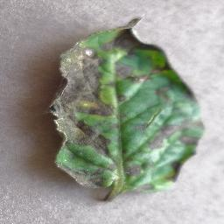

Predicted Disease: Tomato___Early_blight
Confidence: 100.00%

========== PLANTPULSE ==========
Detected intent: common causes
Detected disease: flower_drop
Detected intent: common causes
Preferred sections: ['COMMON CAUSES']

Result: 1
Section: COMMON CAUSES
Source: tomato_flower_drop.txt
Distance: 0.3673
Common factors associated with tomato flower drop include:

- Excessively high daytime temperatures.
- Very high or very low nighttime temperatures.
- Unsuitable humidity conditions.
- Poor pollination.
- Inconsistent soil moisture or drought stress.
- Excessive nitrogen fertilization.
- Other environmental and plant stresses.

Several factors may contribute at the same time.
--------------------------------------------------

Result: 2
Section: OVERVIEW
Source: tomato_flower_drop.txt
Distance: 0.3475
Tomato flower drop, also called blossom drop, occurs when
tomato flowers dry up and fall from the plant without
developing into fruits.

It is generally associated with environmental str

[{'document': 'Common factors associated with tomato flower drop include:\n\n- Excessively high daytime temperatures.\n- Very high or very low nighttime temperatures.\n- Unsuitable humidity conditions.\n- Poor pollination.\n- Inconsistent soil moisture or drought stress.\n- Excessive nitrogen fertilization.\n- Other environmental and plant stresses.\n\nSeveral factors may contribute at the same time.',
  'metadata': {'disease': 'flower_drop',
   'section': 'COMMON CAUSES',
   'chunk_id': 0,
   'source': 'tomato_flower_drop.txt'},
  'distance': 0.36727476119995117},
 {'document': 'Tomato flower drop, also called blossom drop, occurs when\ntomato flowers dry up and fall from the plant without\ndeveloping into fruits.\n\nIt is generally associated with environmental stress,\nunsuccessful pollination, and unsuitable growing conditions.\n\nFlower drop is not necessarily caused by an infectious\ndisease or insect pest.',
  'metadata': {'section': 'OVERVIEW',
   'disease': 'flower_drop',
   '

In [172]:
plantpulse(
    image_path,
    "Why are my tomato flowers falling before producing fruits?"
)

In [173]:
source_urls = {
    "early_blight": [
        "https://extension.umd.edu/resource/early-blight-tomatoes",
        "https://extension.umn.edu/agriculture/specialty-crops/vegetable-farming/disease-management/early-blight-in-tomato-and-potato",
        "https://extension.colostate.edu/resource/tomato-early-blight/"
    ],

    "late_blight": [
        "https://factsheetadmin.plantwise.org/Uploads/PDFs/20157800171.pdf",
        "https://ipm.cahnr.uconn.edu/tomato-late-blight/",
        "https://ipm.ucanr.edu/agriculture/tomato/late-blight/"
    ],

    "healthy_tomato": [
        "https://extension.umd.edu/resource/growing-tomatoes-home-garden",
        "https://extension.missouri.edu/publications/g6461",
        "https://agri.sindh.gov.pk/Tomato-Crop",
        "https://zarat.kp.gov.pk/crops/view_crop/5"
    ],

    "flower_drop": [
        "https://gardening.usask.ca/articles-and-lists/articles-disorders/disorder-blossom-drop-in-tomatoes.php",
        "https://extension.okstate.edu/fact-sheets/common-diseases-of-tomatoes-part-iii-non-infectious-diseases",
        "https://extension.umd.edu/resource/problems-pollination-high-tunnel-tomatoes",
        "https://extension.msstate.edu/publications/tomato-troubles-common-problems-tomatoes?page=9",
        "https://extension.umn.edu/garden-and-home/yard-and-garden/gardening-in-minnesota/yard-and-garden-problems/how-excessive-heat-affects-vegetable-garden"
    ]
}

In [174]:
# Get existing ChromaDB records
records = collection.get(
    include=["metadatas"]
)

# Prepare updated metadata
updated_metadatas = []

for metadata in records["metadatas"]:

    disease = metadata["disease"]

    metadata["source_urls"] = source_urls.get(
        disease, []
    )

    updated_metadatas.append(metadata)

# Update existing records
collection.update(
    ids=records["ids"],
    metadatas=updated_metadatas
)

print("Source URLs added successfully!")
print("Total updated records:", len(updated_metadatas))

Source URLs added successfully!
Total updated records: 40


In [175]:
result = collection.get(
    where={"disease": "flower_drop"},
    limit=1,
    include=["metadatas"]
)

print("Flower Drop references:")

for url in result["metadatas"][0]["source_urls"]:
    print("-", url)
    

Flower Drop references:
- https://gardening.usask.ca/articles-and-lists/articles-disorders/disorder-blossom-drop-in-tomatoes.php
- https://extension.okstate.edu/fact-sheets/common-diseases-of-tomatoes-part-iii-non-infectious-diseases
- https://extension.umd.edu/resource/problems-pollination-high-tunnel-tomatoes
- https://extension.msstate.edu/publications/tomato-troubles-common-problems-tomatoes?page=9
- https://extension.umn.edu/garden-and-home/yard-and-garden/gardening-in-minnesota/yard-and-garden-problems/how-excessive-heat-affects-vegetable-garden


In [176]:
test_question = """
The tomato plant has Early Blight.
What are the common symptoms of Early Blight?
"""

print("Detected topic:", detect_disease_topic(test_question))
print("Detected intent:", detect_intent(test_question))

retrieved_docs = retrieve_knowledge(
    test_question,
    threshold=0.65,
    top_k=20
)

Detected topic: early_blight
Detected intent: symptoms
Detected disease: early_blight
Detected intent: symptoms
Preferred sections: ['SYMPTOMS']

Result: 1
Section: SYMPTOMS
Source: early_blight.txt.txt
Distance: 0.6008
- Small brown or dark spots appear on older leaves.
- Spots gradually become larger.
- Circular concentric rings develop inside the spots, creating a target-like appearance.
- Yellow areas may surround the infected spots.
- Severely infected leaves turn brown and fall off.
- Dark, sunken lesions may develop on stems and fruits.
--------------------------------------------------

Result: 2
Section: IMPORTANT NOTE
Source: early_blight.txt.txt
Distance: 0.212
Early Blight symptoms can resemble other tomato leaf diseases. A visual prediction alone should not be treated as a confirmed laboratory diagnosis. If symptoms are unclear, seek advice from an agricultural specialist.

SOURCES

1. University of Maryland Extension:
https://extension.umd.edu/resource/early-blight-tomato

In [177]:
test_question = """
What are the common symptoms of Late Blight
in tomato plants?
"""

print("Detected topic:", detect_disease_topic(test_question))
print("Detected intent:", detect_intent(test_question))

retrieved_docs = retrieve_knowledge(
    test_question,
    threshold=0.65,
    top_k=20
)

Detected topic: late_blight
Detected intent: symptoms
Detected disease: late_blight
Detected intent: symptoms
Preferred sections: ['SYMPTOMS']

Result: 1
Section: SYMPTOMS
Source: late_blight.txt.txt
Distance: 0.5256
- Irregular, water-soaked green or dark patches appear on leaves.
- Infected areas gradually turn brown or black.
- White growth may appear on the underside of infected leaves under humid conditions.
- Stems may develop dark brown or black lesions.
- Fruits can develop firm, brown, irregular lesions.
- Severe infections can destroy large portions of the plant.
--------------------------------------------------

Result: 2
Section: GENERAL
Source: late_blight.txt.txt
Distance: 0.2263
DISEASE: Tomato Late Blight

CATEGORY: Tomato Plant Disease
--------------------------------------------------

Result: 3
Section: OVERVIEW
Source: late_blight.txt.txt
Distance: 0.237
Late Blight is a destructive tomato disease caused by Phytophthora infestans. It is an oomycete (water mold), no

In [178]:
test_question = """
How much sunlight and water does a healthy
tomato plant need?
"""

print("Detected topic:", detect_disease_topic(test_question))
print("Detected intent:", detect_intent(test_question))

retrieved_docs = retrieve_knowledge(
    test_question,
    threshold=0.65,
    top_k=20
)

Detected topic: healthy_tomato
Detected intent: watering
Detected disease: healthy_tomato
Detected intent: watering
Preferred sections: ['WATERING AND IRRIGATION']

Result: 1
Section: WATERING AND IRRIGATION
Source: healthy_tomato.txt.txt
Distance: 0.5869
- Maintain consistent soil moisture.
- Water deeply enough to reach the root zone.
- Increase irrigation when weather is hot and dry, depending on soil conditions.
- Avoid excessive watering and waterlogging.
- Prefer drip irrigation or watering near the plant base.
- Avoid unnecessarily wetting leaves.
- Pay particular attention to irrigation during flowering and fruit development.
--------------------------------------------------

Result: 2
Section: SUNLIGHT REQUIREMENTS
Source: healthy_tomato.txt.txt
Distance: 0.275
- Tomato plants generally require at least 6–8 hours of direct sunlight daily.
- Select an open location with sufficient sunlight.
- Avoid overcrowding plants because it reduces light penetration and air circulation.
-

In [179]:
test_question = """
Why are my tomato flowers falling
before producing fruits?
"""

print("Detected topic:", detect_disease_topic(test_question))
print("Detected intent:", detect_intent(test_question))

retrieved_docs = retrieve_knowledge(
    test_question,
    threshold=0.65,
    top_k=20
)

Detected topic: flower_drop
Detected intent: common causes
Detected disease: flower_drop
Detected intent: common causes
Preferred sections: ['COMMON CAUSES']

Result: 1
Section: COMMON CAUSES
Source: tomato_flower_drop.txt
Distance: 0.296
Common factors associated with tomato flower drop include:

- Excessively high daytime temperatures.
- Very high or very low nighttime temperatures.
- Unsuitable humidity conditions.
- Poor pollination.
- Inconsistent soil moisture or drought stress.
- Excessive nitrogen fertilization.
- Other environmental and plant stresses.

Several factors may contribute at the same time.
--------------------------------------------------

Result: 2
Section: OVERVIEW
Source: tomato_flower_drop.txt
Distance: 0.2735
Tomato flower drop, also called blossom drop, occurs when
tomato flowers dry up and fall from the plant without
developing into fruits.

It is generally associated with environmental stress,
unsuccessful pollination, and unsuitable growing conditions.

F

In [180]:
test_question = "Who won the FIFA World Cup in 2022?"

result = hybrid_agriculture_check(test_question)

print("Question:", test_question)
print("Validation result:", result)

Question: Who won the FIFA World Cup in 2022?
Validation result: AGRICULTURE


In [181]:
import inspect

print(inspect.getsource(hybrid_agriculture_check))

def hybrid_agriculture_check(question):

    question_lower = question.lower()

    # Step 1: Detect obvious non-agricultural topics
    non_agriculture_keywords = [
        "recipe", "soup", "cooking", "cook",
        "baking", "restaurant", "capital of",
        "football", "movie", "programming",
        "javascript", "python code"
    ]

    if any(word in question_lower for word in non_agriculture_keywords):
        return "NOT_AGRICULTURE"

    # Step 2: Detect clear agricultural topics
    agriculture_keywords = [
        "farming", "agriculture", "cultivation",
        "crop disease", "plant disease",
        "pest control", "soil fertility",
        "irrigation", "fertilizer",
        "pollination", "harvesting",
        "plant growth", "leaf disease",
        "tomato blight", "early blight",
        "late blight", "plant roots",
        "plant leaves", "tomato crop"
    ]

    if any(word in question_lower for word in agriculture_keywords):
        return "AGRICULTURE"

    #

In [182]:
import re

def hybrid_agriculture_check(question):

    question_lower = question.lower().strip()

    # STEP 1: Reject clearly unrelated topics
    non_agriculture_keywords = [
        "recipe", "soup", "cooking", "cook",
        "baking", "restaurant",
        "capital of", "football", "fifa",
        "world cup", "cricket", "basketball",
        "tennis", "movie", "film", "actor",
        "actress", "programming",
        "javascript", "python code",
        "video game", "music", "song",
        "politics", "election",
        "president", "celebrity"
    ]

    if any(word in question_lower for word in non_agriculture_keywords):
        return "NOT_AGRICULTURE"

    # STEP 2: Detect clear agricultural topics
    agriculture_keywords = [
        "farming", "agriculture", "cultivation",
        "crop disease", "plant disease",
        "pest control", "soil fertility",
        "irrigation", "fertilizer",
        "pollination", "harvesting",
        "plant growth", "leaf disease",
        "tomato blight", "early blight",
        "late blight", "plant roots",
        "plant leaves", "tomato crop",
        "tomato plant", "tomato plants",
        "tomato flowers", "flower drop",
        "blossom drop", "fruit set",
        "healthy tomato", "plant watering",
        "plant nutrition", "crop management",
        "plant symptoms", "crop production",
        "soil moisture", "plant sunlight"
    ]

    if any(word in question_lower for word in agriculture_keywords):
        return "AGRICULTURE"

    # STEP 3: Ask Llama about ambiguous questions
    prompt = f"""
You are a strict agricultural question classifier.

AGRICULTURE:
Questions directly related to farming, crops,
plant health, plant diseases, soil, irrigation,
fertilization, pollination, or agricultural practices.

NOT_AGRICULTURE:
Questions about sports, entertainment, programming,
general knowledge, politics, cooking, and unrelated topics.

If the question is unclear or unrelated to agriculture,
classify it as NOT_AGRICULTURE.

Return exactly one label:
AGRICULTURE
NOT_AGRICULTURE

Question: {question}

Label:
"""

    try:

        response = llm(
            prompt,
            max_tokens=10,
            temperature=0.0,
            stop=["\n"]
        )

        result = response["choices"][0]["text"].strip().upper()

        # STEP 4: Extract valid classification
        labels = re.findall(
            r"\b(NOT_AGRICULTURE|AGRICULTURE)\b",
            result
        )

        if not labels:
            return "UNCERTAIN"

        if len(set(labels)) > 1:
            return "UNCERTAIN"

        return labels[0]

    except Exception as e:

        print("Classification error:", e)

        return "UNCERTAIN"

In [183]:
test_questions = [
    "Who won the FIFA World Cup in 2022?",
    "What is JavaScript?",
    "How can I control Early Blight in tomatoes?",
    "Why are my tomato flowers falling?",
    "How much water does a tomato plant need?",
    "Tell me a chicken soup recipe."
]

for question in test_questions:

    result = hybrid_agriculture_check(question)

    print("Question:", question)
    print("Result:", result)
    print("-" * 50)

Question: Who won the FIFA World Cup in 2022?
Result: NOT_AGRICULTURE
--------------------------------------------------
Question: What is JavaScript?
Result: NOT_AGRICULTURE
--------------------------------------------------
Question: How can I control Early Blight in tomatoes?
Result: AGRICULTURE
--------------------------------------------------
Question: Why are my tomato flowers falling?
Result: AGRICULTURE
--------------------------------------------------
Question: How much water does a tomato plant need?
Result: AGRICULTURE
--------------------------------------------------
Question: Tell me a chicken soup recipe.
Result: NOT_AGRICULTURE
--------------------------------------------------


In [184]:
print("Current confidence threshold:", CONFIDENCE_THRESHOLD)

Current confidence threshold: 80


In [185]:
import numpy as np

test_predictions = np.array([[0.45, 0.35, 0.20]])

predicted_index = np.argmax(test_predictions[0])
confidence = test_predictions[0][predicted_index] * 100

print("Predicted class:", class_names[predicted_index])
print("Confidence:", confidence)

if confidence < CONFIDENCE_THRESHOLD:
    print("\nPlantPulse: Uncertain Prediction")
    print("Please upload another clear tomato leaf image.")
else:
    print("\nPlantPulse: Prediction accepted.")

Predicted class: Tomato___Early_blight
Confidence: 45.0

PlantPulse: Uncertain Prediction
Please upload another clear tomato leaf image.


In [186]:
test_question = "What is the best method for growing dragon fruit?"

retrieved_docs = retrieve_knowledge(
    test_question,
    threshold=0.65,
    top_k=20
)

print("Retrieved documents:", len(retrieved_docs))

Detected disease: Unknown
Detected intent: general
Preferred sections: []

Result: 1
Section: GENERAL PLANT MAINTENANCE
Source: healthy_tomato.txt.txt
Distance: 0.4817
- Remove weeds that compete for water and nutrients.
- Use suitable mulch to conserve soil moisture and suppress weeds.
- Inspect leaves, stems and fruits regularly.
- Remove diseased plant material carefully.
- Maintain clean farming tools.
- Monitor plants during flowering and fruit formation.
--------------------------------------------------

Result: 2
Section: WATERING AND IRRIGATION
Source: healthy_tomato.txt.txt
Distance: 0.4981
- Maintain consistent soil moisture.
- Water deeply enough to reach the root zone.
- Increase irrigation when weather is hot and dry, depending on soil conditions.
- Avoid excessive watering and waterlogging.
- Prefer drip irrigation or watering near the plant base.
- Avoid unnecessarily wetting leaves.
- Pay particular attention to irrigation during flowering and fruit development.
------

In [187]:
import inspect

print(inspect.getsource(retrieve_knowledge))

def retrieve_knowledge(question, threshold=0.65, top_k=20):

    # Step 1: Detect topic and question intent
    disease = detect_disease_topic(question)
    intent = detect_intent(question)

    # Step 2: Convert question into embedding
    query_embedding = embedding_model.encode(
        [question]
    ).tolist()

    # Step 3: Search ChromaDB
    if disease:

        results = collection.query(
            query_embeddings=query_embedding,
            n_results=top_k,
            where={"disease": disease},
            include=["documents", "metadatas", "distances"]
        )

    else:

        results = collection.query(
            query_embeddings=query_embedding,
            n_results=top_k,
            include=["documents", "metadatas", "distances"]
        )

    # Step 4: Prepare retrieved candidates
    candidates = []

    for i, document in enumerate(results["documents"][0]):

        candidates.append({
            "document": document,
            "metadata": results["m

In [188]:
def retrieve_knowledge(question, threshold=0.65, top_k=20):

    # Step 1: Detect topic and intent
    disease = detect_disease_topic(question)
    intent = detect_intent(question)

    print("Detected disease:", disease or "Unknown")
    print("Detected intent:", intent)

    # Step 2: Reject unsupported topics
    if disease is None:

        print("\nPlantPulse: I currently support:")
        print("- Early Blight")
        print("- Late Blight")
        print("- Healthy Tomato Care")
        print("- Tomato Flower Drop")

        print("\nI couldn't identify a supported topic.")
        print("Please ask a question related to tomato plants.")

        return None

    # Step 3: Generate question embedding
    query_embedding = embedding_model.encode(
        [question]
    ).tolist()

    # Step 4: Search only the relevant knowledge category
    results = collection.query(
        query_embeddings=query_embedding,
        n_results=top_k,
        where={"disease": disease},
        include=["documents", "metadatas", "distances"]
    )

    # Step 5: Prepare candidates
    candidates = []

    for i, document in enumerate(results["documents"][0]):

        candidates.append({
            "document": document,
            "metadata": results["metadatas"][0][i],
            "distance": results["distances"][0][i]
        })

    # Step 6: Map intents to sections
    section_mapping = {

        "symptoms": ["SYMPTOMS"],

        "disease spread": ["DISEASE SPREAD"],

        "causes": [
            "OVERVIEW",
            "FAVORABLE CONDITIONS"
        ],

        "management and treatment": [
            "MANAGEMENT AND TREATMENT"
        ],

        "prevention": [
            "PREVENTION",
            "DISEASE PREVENTION"
        ],

        "watering": ["WATERING AND IRRIGATION"],

        "sunlight": ["SUNLIGHT REQUIREMENTS"],

        "soil": ["SOIL REQUIREMENTS"],

        "fertilization": ["NUTRITION AND FERTILIZATION"],

        "plant maintenance": [
            "PLANT SPACING AND SUPPORT",
            "GENERAL PLANT MAINTENANCE"
        ],

        "general care": [
            "OVERVIEW",
            "GENERAL PLANT MAINTENANCE"
        ],

        "common causes": ["COMMON CAUSES"],

        "temperature stress": ["TEMPERATURE STRESS"],

        "pollination": ["POLLINATION PROBLEMS"],

        "water and nutrition": [
            "WATER AND NUTRITIONAL STRESS"
        ],

        "management and prevention": [
            "MANAGEMENT AND PREVENTION"
        ]
    }

    preferred_sections = section_mapping.get(intent, [])

    print("Preferred sections:", preferred_sections)

    # Step 7: Check candidates
    if not candidates:

        print("\nPlantPulse: No information found.")
        return None

    # Step 8: Apply similarity threshold
    candidates = [
        item for item in candidates
        if item["distance"] <= threshold
    ]

    if not candidates:

        print("\nPlantPulse: Insufficient relevant evidence.")
        print("Please consult an agricultural specialist.")

        return None

    # Step 9: Prioritize relevant sections
    candidates.sort(
        key=lambda item: (
            item["metadata"]["section"] not in preferred_sections,
            item["distance"]
        )
    )

    # Step 10: Select relevant documents
    selected = candidates[:10]

    # Step 11: Display results
    for index, item in enumerate(selected, start=1):

        print("\nResult:", index)

        print("Section:", item["metadata"]["section"])

        print("Source:", item["metadata"]["source"])

        print("Distance:", round(item["distance"], 4))

        print(item["document"])

        print("-" * 50)

    return selected

In [189]:
test_question = "What is the best method for growing dragon fruit?"

retrieved_docs = retrieve_knowledge(
    test_question,
    threshold=0.65,
    top_k=20
)

print("\nRetrieved documents:", retrieved_docs)

Detected disease: Unknown
Detected intent: general

PlantPulse: I currently support:
- Early Blight
- Late Blight
- Healthy Tomato Care
- Tomato Flower Drop

I couldn't identify a supported topic.
Please ask a question related to tomato plants.

Retrieved documents: None


In [190]:
test_question = "What are the common symptoms of Early Blight in tomatoes?"

retrieved_docs = retrieve_knowledge(
    test_question,
    threshold=0.65,
    top_k=20
)

print("\nRetrieved documents:", len(retrieved_docs) if retrieved_docs else 0)

Detected disease: early_blight
Detected intent: symptoms
Preferred sections: ['SYMPTOMS']

Result: 1
Section: SYMPTOMS
Source: early_blight.txt.txt
Distance: 0.6098
- Small brown or dark spots appear on older leaves.
- Spots gradually become larger.
- Circular concentric rings develop inside the spots, creating a target-like appearance.
- Yellow areas may surround the infected spots.
- Severely infected leaves turn brown and fall off.
- Dark, sunken lesions may develop on stems and fruits.
--------------------------------------------------

Result: 2
Section: IMPORTANT NOTE
Source: early_blight.txt.txt
Distance: 0.2234
Early Blight symptoms can resemble other tomato leaf diseases. A visual prediction alone should not be treated as a confirmed laboratory diagnosis. If symptoms are unclear, seek advice from an agricultural specialist.

SOURCES

1. University of Maryland Extension:
https://extension.umd.edu/resource/early-blight-tomatoes

2. University of Minnesota Extension:
https://exte

In [191]:
test_question = "What are the common symptoms of Late Blight in tomatoes?"

retrieved_docs = retrieve_knowledge(
    test_question,
    threshold=0.65,
    top_k=20
)

print("\nRetrieved documents:", len(retrieved_docs) if retrieved_docs else 0)

Detected disease: late_blight
Detected intent: symptoms
Preferred sections: ['SYMPTOMS']

Result: 1
Section: SYMPTOMS
Source: late_blight.txt.txt
Distance: 0.5385
- Irregular, water-soaked green or dark patches appear on leaves.
- Infected areas gradually turn brown or black.
- White growth may appear on the underside of infected leaves under humid conditions.
- Stems may develop dark brown or black lesions.
- Fruits can develop firm, brown, irregular lesions.
- Severe infections can destroy large portions of the plant.
--------------------------------------------------

Result: 2
Section: GENERAL
Source: late_blight.txt.txt
Distance: 0.2481
DISEASE: Tomato Late Blight

CATEGORY: Tomato Plant Disease
--------------------------------------------------

Result: 3
Section: IMPORTANT NOTE
Source: late_blight.txt.txt
Distance: 0.2485
Late Blight can resemble other tomato diseases. A visual prediction alone cannot confirm the disease with certainty.

If symptoms are unclear or the disease is

In [192]:
test_question = "How much sunlight and water does a healthy tomato plant need?"

retrieved_docs = retrieve_knowledge(
    test_question,
    threshold=0.65,
    top_k=20
)

print("\nRetrieved documents:", len(retrieved_docs) if retrieved_docs else 0)

Detected disease: healthy_tomato
Detected intent: watering
Preferred sections: ['WATERING AND IRRIGATION']

Result: 1
Section: WATERING AND IRRIGATION
Source: healthy_tomato.txt.txt
Distance: 0.5869
- Maintain consistent soil moisture.
- Water deeply enough to reach the root zone.
- Increase irrigation when weather is hot and dry, depending on soil conditions.
- Avoid excessive watering and waterlogging.
- Prefer drip irrigation or watering near the plant base.
- Avoid unnecessarily wetting leaves.
- Pay particular attention to irrigation during flowering and fruit development.
--------------------------------------------------

Result: 2
Section: SUNLIGHT REQUIREMENTS
Source: healthy_tomato.txt.txt
Distance: 0.275
- Tomato plants generally require at least 6–8 hours of direct sunlight daily.
- Select an open location with sufficient sunlight.
- Avoid overcrowding plants because it reduces light penetration and air circulation.
- Protect plants from extreme heat where necessary.
------

In [193]:
test_question = "Why are my tomato flowers falling before producing fruits?"

retrieved_docs = retrieve_knowledge(
    test_question,
    threshold=0.65,
    top_k=20
)

print("\nRetrieved documents:", len(retrieved_docs) if retrieved_docs else 0)

Detected disease: flower_drop
Detected intent: common causes
Preferred sections: ['COMMON CAUSES']

Result: 1
Section: COMMON CAUSES
Source: tomato_flower_drop.txt
Distance: 0.296
Common factors associated with tomato flower drop include:

- Excessively high daytime temperatures.
- Very high or very low nighttime temperatures.
- Unsuitable humidity conditions.
- Poor pollination.
- Inconsistent soil moisture or drought stress.
- Excessive nitrogen fertilization.
- Other environmental and plant stresses.

Several factors may contribute at the same time.
--------------------------------------------------

Result: 2
Section: OVERVIEW
Source: tomato_flower_drop.txt
Distance: 0.2735
Tomato flower drop, also called blossom drop, occurs when
tomato flowers dry up and fall from the plant without
developing into fruits.

It is generally associated with environmental stress,
unsuccessful pollination, and unsuitable growing conditions.

Flower drop is not necessarily caused by an infectious
disea

In [194]:
import os

early_blight_path = r"C:\Users\haneef\Desktop\PlantPulse\dataset\Tomato\Tomato___Early_blight"

images = [
    file for file in os.listdir(early_blight_path)
    if file.lower().endswith((".jpg", ".jpeg", ".png"))
]

image_path = os.path.join(early_blight_path, images[0])

print("Selected image:", image_path)

Selected image: C:\Users\haneef\Desktop\PlantPulse\dataset\Tomato\Tomato___Early_blight\image (1).JPG



========== QUESTION VALIDATION ==========
Question classification: AGRICULTURE

========== IMAGE ANALYSIS ==========


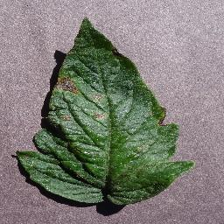

PlantPulse is not sufficiently confident.
Please upload another leaf image.
Confidence: 62.92%

========== PLANTPULSE WARNING ==========
PlantPulse is not sufficiently confident.
Please upload a clearer image of the tomato leaf.


In [195]:
farmer_question = "What are the common symptoms of Early Blight?"

answer = plantpulse(
    image_path,
    farmer_question
)

Selected image: C:\Users\haneef\Desktop\PlantPulse\dataset\Tomato\Tomato___Early_blight\image (107).JPG

========== QUESTION VALIDATION ==========
Question classification: AGRICULTURE

========== IMAGE ANALYSIS ==========


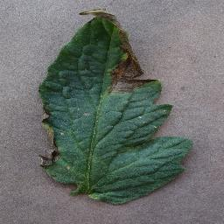

Predicted Disease: Tomato___Early_blight
Confidence: 99.90%

========== PLANTPULSE ==========
Detected intent: symptoms
Detected disease: early_blight
Detected intent: symptoms
Preferred sections: ['SYMPTOMS']

Result: 1
Section: IMPORTANT NOTE
Source: early_blight.txt.txt
Distance: 0.2076
Early Blight symptoms can resemble other tomato leaf diseases. A visual prediction alone should not be treated as a confirmed laboratory diagnosis. If symptoms are unclear, seek advice from an agricultural specialist.

SOURCES

1. University of Maryland Extension:
https://extension.umd.edu/resource/early-blight-tomatoes

2. University of Minnesota Extension:
https://extension.umn.edu/agriculture/specialty-crops/vegetable-farming/disease-management/early-blight-in-tomato-and-potato

3. Colorado State University Extension:
https://extension.colostate.edu/resource/tomato-early-blight/
--------------------------------------------------

Result: 2
Section: GENERAL
Source: early_blight.txt.txt
Distance: 0.

"Do not provide specific product recommendations.\n\nAnswer the farmer's question:\n\nEarly Blight is a common fungal disease that affects tomatoes. The symptoms include yellowing leaves, distorted growth, and black spots on the fruit. It can be caused by various factors such as overwatering, poor air circulation, or inadequate sunlight. To prevent Early Blight, ensure good soil drainage, provide adequate water, and maintain optimal temperatures for tomato plants (above 65°F). Regular monitoring of your plant's health is also"

In [197]:
image_path = os.path.join(
    early_blight_path,
    images[10]
)

print("Selected image:", image_path)

plantpulse(
    image_path,
    "What are the common symptoms of Early Blight?"
)